# Hotel Booking Demand, Customer Behaviour and Cancellation Analysis
### Comprehensive End-to-End Hospitality Analytics & Revenue Management Study

---
**Prepared by:** Aman Sah, Training Central  
**Project Level:** Advanced Analytics & Strategic Consulting  
**Target Audience:** Hotel Senior Leadership, Revenue Managers, and Operations Directors  
**Dataset Reference:** António, N., de Almeida, A., & Nunes, L. (2019). *Hotel booking demand datasets*. Data in Brief, 22, 41-49.  
**Format:** Single Production-Grade Executable Jupyter Notebook (`.ipynb`) adhering to PEP 8, PEP 257 docstring standards, and Object-Oriented Architecture.

---

### Executive Problem Statement & Research Questions
This project investigates the operational, behavioral, and commercial drivers of hotel reservation outcomes across two contrasting properties: a **City Hotel (Lisbon, Portugal)** and a **Resort Hotel (Algarve, Portugal)**. Historical reservation records spanning arrivals from July 1, 2015 to August 31, 2017 are examined to address ten core managerial questions:

1. **Why are hotel bookings cancelled?** (Identifying root behavioral and operational drivers of cancellation).
2. **Do city hotels and resort hotels exhibit distinct booking patterns?** (Contrasting urban commercial vs coastal leisure dynamics).
3. **Which months and seasons experience peak booking demand?** (Decomposing calendar seasonality and arrival clustering).
4. **How does advance booking horizon (lead time) influence cancellation risk?** (Quantifying the vulnerability of distant commitments).
5. **Which customer segments contribute the highest volume and stability?** (Profiling Transient, Group, Contract, and Party segments).
6. **Do special requests signal genuine guest commitment to stay?** (Evaluating customer engagement as a mitigating signal).
7. **How do room type allocations, deposit structures, and booking channels shape reservation outcomes?** (Unraveling the Non-Refund deposit paradox and room mismatch effects).
8. **What factors drive Average Daily Rate (ADR) premiums?** (Assessing seasonality, room tiering, lead time, and channel discounting).
9. **How do weekday and weekend stay patterns diverge?** (Evaluating length-of-stay structures across property types).
10. **What concrete revenue management, booking policies, and operational strategies should leadership implement?** (Formulating data-grounded strategic recommendations).

In [1]:
# Standard Library Imports
import os
import sys
import io
import json
import base64
import warnings
from typing import Dict, List, Tuple, Any, Optional

# Core Scientific & Data Manipulation Libraries
import numpy as np
import pandas as pd

# Visualization Libraries
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Visualization Settings & Aesthetics
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 15

print("Environment configured: NumPy", np.__version__, "| Pandas", pd.__version__, "| Matplotlib", matplotlib.__version__, "| Seaborn", sns.__version__)

Environment configured: NumPy 2.5.5 | Pandas 3.1.1 | Matplotlib 3.11.2 | Seaborn 0.13.2


## Object-Oriented Analytical Architecture
To adhere to enterprise software engineering standards, the analysis is modularized into seven production Python classes:
1. `HotelDataLoader`: Manages raw data ingestion, H1/H2 partition handling, and structural data dictionary generation.
2. `HotelDataPreprocessor`: Implements a scikit-learn compatible transformer for temporal parsing, missingness imputation, feature engineering, and auditable anomaly logging.
3. `UnivariateAnalyzer`: Encapsulates parametric/non-parametric descriptive metrics and distributional plotting routines.
4. `ComparativeHotelAnalyzer`: Conducts rigorous property-level comparisons reporting both absolute differences and relative percentage changes.
5. `CancellationAnalyzer`: Drives multi-factor cancellation rate profiling, risk segmentation, and the Non-Refund paradox investigation.
6. `TimeSeriesSeasonalityAnalyzer`: Decomposes temporal trends across years, months, weeks, and arrival days.
7. `RevenueManager`: Benchmarks ADR, models lodging value equations, audits financial validity, and synthesizes executive strategies.

In [4]:
"""
OOP Analytical Architecture for Hotel Booking Demand Analysis
============================================================
This module encapsulates all data loading, preprocessing, univariate,
comparative, cancellation, time-series, and revenue management logic
into clean, reusable Python classes adhering to PEP 8 and PEP 257 standards.
"""

from typing import Dict, List, Tuple, Any, Optional
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


class HotelDataLoader:
    """Encapsulates raw data ingestion, H1/H2 file partition handling,
    and initial schema inspection routines.
    """

    def __init__(self, file_path: str = 'hotel_bookings.csv') -> None:
        """Initialize loader with file path.

        Parameters
        ----------
        file_path : str
            Relative or absolute path to the hotel bookings CSV dataset.
        """
        self.file_path = file_path

    def load_raw_data(self) -> pd.DataFrame:
        """Load raw CSV dataset into a Pandas DataFrame.

        Returns
        -------
        pd.DataFrame
            Unmodified raw hotel booking demand dataset.
        """
        return pd.read_csv(self.file_path)

    def get_h1_h2_split(self, df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame]:
        """Simulate loading separate H1 (Resort Hotel) and H2 (City Hotel) datasets.

        Parameters
        ----------
        df : pd.DataFrame
            Combined raw hotel booking dataset.

        Returns
        -------
        Tuple[pd.DataFrame, pd.DataFrame]
            H1 (Resort Hotel subset) and H2 (City Hotel subset).
        """
        h1 = df[df['hotel'] == 'Resort Hotel'].copy()
        h2 = df[df['hotel'] == 'City Hotel'].copy()
        return h1, h2

    def generate_data_dictionary(self, df: pd.DataFrame) -> pd.DataFrame:
        """Generate a structured metadata data dictionary for all columns.

        Parameters
        ----------
        df : pd.DataFrame
            The hotel bookings DataFrame.

        Returns
        -------
        pd.DataFrame
            Data dictionary containing variable names, data types,
            analytical categories, and functional descriptions.
        """
        descriptions = {
            'hotel': 'Type of hotel property (Resort Hotel or City Hotel)',
            'is_canceled': 'Binary flag indicating whether booking was canceled (1) or not (0)',
            'lead_time': 'Number of days elapsed between entering date of booking and arrival date',
            'arrival_date_year': 'Year of arrival date (2015, 2016, 2017)',
            'arrival_date_month': 'Month of arrival date with 12 months categories',
            'arrival_date_week_number': 'Week number of arrival date as defined in ISO 8601',
            'arrival_date_day_of_month': 'Day of the month of the arrival date (1-31)',
            'stays_in_weekend_nights': 'Number of weekend nights (Saturday or Sunday) stayed or booked',
            'stays_in_week_nights': 'Number of weekday nights (Monday to Friday) stayed or booked',
            'adults': 'Number of adult guests included in the reservation',
            'children': 'Number of child guests (aged 2 to 12)',
            'babies': 'Number of baby/infant guests (under age 2)',
            'meal': 'Type of meal booked (BB: Bed & Breakfast, HB: Half Board, FB: Full Board, SC: Self Catering, Undefined)',
            'country': 'Country of origin of primary guest in ISO 3166-1 alpha-3 code',
            'market_segment': 'Market segment designation (Direct, Corporate, Online TA, Offline TA/TO, Groups, Complementary, Aviation)',
            'distribution_channel': 'Booking distribution channel (TA/TO, Direct, Corporate, GDS, Undefined)',
            'is_repeated_guest': 'Binary flag indicating if guest booking name is a repeat guest (1) or new (0)',
            'previous_cancellations': 'Number of previous bookings that were canceled by the customer prior to current booking',
            'previous_bookings_not_canceled': 'Number of previous bookings not canceled by customer prior to current booking',
            'reserved_room_type': 'Code of room type reserved by customer (A-L)',
            'assigned_room_type': 'Code of room type actually assigned to booking (may differ due to operational allocation/upgrade)',
            'booking_changes': 'Number of changes/amendments made to the booking until check-in or cancellation',
            'deposit_type': 'Indication if customer made a deposit (No Deposit, Non Refund, Refundable)',
            'agent': 'ID of the travel agency that made the booking (numeric code)',
            'company': 'ID of the corporate company/entity that made the booking or pays fees (numeric code)',
            'days_in_waiting_list': 'Number of days booking was on waiting list before confirmed to customer',
            'customer_type': 'Type of booking customer (Transient, Transient-Party, Contract, Group)',
            'adr': 'Average Daily Rate defined by dividing the sum of all lodging transactions by total staying nights',
            'required_car_parking_spaces': 'Number of car parking spaces requested by the customer',
            'total_of_special_requests': 'Number of special requests made by customer (e.g. high floor, twin bed)',
            'reservation_status': 'Final reservation status (Check-Out, Canceled, No-Show)',
            'reservation_status_date': 'Date at which the last status was set (YYYY-MM-DD)'
        }
        
        categories = {
            'hotel': 'Categorical (Nominal)',
            'is_canceled': 'Binary (Target)',
            'lead_time': 'Numerical (Discrete/Interval)',
            'arrival_date_year': 'Temporal (Year)',
            'arrival_date_month': 'Temporal (Month)',
            'arrival_date_week_number': 'Temporal (Week Number)',
            'arrival_date_day_of_month': 'Temporal (Day)',
            'stays_in_weekend_nights': 'Numerical (Discrete)',
            'stays_in_week_nights': 'Numerical (Discrete)',
            'adults': 'Numerical (Discrete)',
            'children': 'Numerical (Discrete)',
            'babies': 'Numerical (Discrete)',
            'meal': 'Categorical (Nominal)',
            'country': 'Categorical (Geographic)',
            'market_segment': 'Categorical (Nominal)',
            'distribution_channel': 'Categorical (Nominal)',
            'is_repeated_guest': 'Binary Flag',
            'previous_cancellations': 'Numerical (Discrete Count)',
            'previous_bookings_not_canceled': 'Numerical (Discrete Count)',
            'reserved_room_type': 'Categorical (Nominal/Ordinal)',
            'assigned_room_type': 'Categorical (Nominal/Ordinal)',
            'booking_changes': 'Numerical (Discrete Count)',
            'deposit_type': 'Categorical (Nominal)',
            'agent': 'Categorical (Identifier)',
            'company': 'Categorical (Identifier)',
            'days_in_waiting_list': 'Numerical (Discrete/Interval)',
            'customer_type': 'Categorical (Nominal)',
            'adr': 'Numerical (Continuous Financial)',
            'required_car_parking_spaces': 'Numerical (Discrete Count)',
            'total_of_special_requests': 'Numerical (Discrete Count)',
            'reservation_status': 'Categorical (Nominal/Status)',
            'reservation_status_date': 'Temporal (Date)'
        }

        dict_df = pd.DataFrame({
            'Column Name': df.columns,
            'Data Type': [str(df[col].dtype) for col in df.columns],
            'Analytical Category': [categories.get(col, 'Unknown') for col in df.columns],
            'Description': [descriptions.get(col, 'N/A') for col in df.columns]
        })
        return dict_df


class HotelDataPreprocessor:
    """Custom transformer class for rigorous data cleaning, missing value handling,
    anomaly filtering, and feature engineering with complete audit logging.
    """

    def __init__(self, filter_anomalies: bool = False) -> None:
        """Initialize preprocessor.

        Parameters
        ----------
        filter_anomalies : bool, default=False
            Whether to strictly remove impossible/anomalous rows or retain
            them for comparative transparency.
        """
        self.filter_anomalies = filter_anomalies
        self.audit_log: List[Dict[str, Any]] = []

    def log_action(self, step: str, action: str, impact: str) -> None:
        """Record an explicit data modification event into the audit trail.

        Parameters
        ----------
        step : str
            Pipeline processing phase.
        action : str
            Specific technical transformation applied.
        impact : str
            Data volume, schema, or distribution consequence.
        """
        self.audit_log.append({
            'Pipeline Step': step,
            'Transformation Action': action,
            'Impact / Records Affected': impact
        })

    def fit(self, df: pd.DataFrame) -> 'HotelDataPreprocessor':
        """Fit preprocessor parameters on dataset.

        Parameters
        ----------
        df : pd.DataFrame
            Input hotel bookings DataFrame.

        Returns
        -------
        HotelDataPreprocessor
            Fitted preprocessor instance.
        """
        return self

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        """Execute full cleaning, conversion, and feature engineering pipeline.

        Parameters
        ----------
        df : pd.DataFrame
            Raw input hotel bookings DataFrame.

        Returns
        -------
        pd.DataFrame
            Fully preprocessed and enriched DataFrame.
        """
        cleaned = df.copy()

        # Step 1: Datetime conversions
        month_map = {
            'January': 1, 'February': 2, 'March': 3, 'April': 4,
            'May': 5, 'June': 6, 'July': 7, 'August': 8,
            'September': 9, 'October': 10, 'November': 11, 'December': 12
        }
        numeric_month = cleaned['arrival_date_month'].map(month_map)
        cleaned['arrival_date'] = pd.to_datetime(
            cleaned['arrival_date_year'].astype(str) + '-' +
            numeric_month.astype(str).str.zfill(2) + '-' +
            cleaned['arrival_date_day_of_month'].astype(str).str.zfill(2)
        )
        cleaned['reservation_status_date'] = pd.to_datetime(cleaned['reservation_status_date'])
        self.log_action(
            'Temporal Parsing',
            'Constructed arrival_date from year, month, and day; converted reservation_status_date to datetime',
            f'Parsed 2 datetime fields across {len(cleaned):,} records'
        )

        # Step 2: Handle missing values
        # children: 4 missing -> fill with mode 0
        children_missing = cleaned['children'].isnull().sum()
        cleaned['children'] = cleaned['children'].fillna(0.0).astype(int)
        self.log_action(
            'Missing Value Imputation',
            'Imputed missing children counts with 0 (mode)',
            f'{children_missing} records imputed'
        )

        # country: 488 missing -> fill with 'Unknown'
        country_missing = cleaned['country'].isnull().sum()
        cleaned['country'] = cleaned['country'].fillna('Unknown')
        self.log_action(
            'Missing Value Imputation',
            'Imputed missing country codes with "Unknown"',
            f'{country_missing} records imputed'
        )

        # agent & company: NULL means direct booking without intermediary
        agent_null = cleaned['agent'].isnull().sum()
        company_null = cleaned['company'].isnull().sum()
        cleaned['agent'] = cleaned['agent'].fillna(0)
        cleaned['company'] = cleaned['company'].fillna(0)
        cleaned['has_agent'] = (cleaned['agent'] != 0).astype(int)
        cleaned['has_company'] = (cleaned['company'] != 0).astype(int)
        self.log_action(
            'Intermediary Identification',
            'Replaced missing agent and company IDs with 0; engineered has_agent and has_company flags',
            f'{agent_null:,} agent and {company_null:,} company records encoded'
        )

        # Step 3: Feature Engineering
        cleaned['total_stay_nights'] = cleaned['stays_in_week_nights'] + cleaned['stays_in_weekend_nights']
        cleaned['total_guests'] = cleaned['adults'] + cleaned['children'] + cleaned['babies']
        cleaned['is_family'] = ((cleaned['children'] > 0) | (cleaned['babies'] > 0)).astype(int)
        cleaned['room_type_changed'] = (cleaned['reserved_room_type'] != cleaned['assigned_room_type']).astype(int)
        
        # Lead time bins
        cleaned['lead_time_bracket'] = pd.cut(
            cleaned['lead_time'],
            bins=[-1, 7, 30, 90, 180, 365, np.inf],
            labels=['0-7 days', '8-30 days', '31-90 days', '91-180 days', '181-365 days', '>365 days']
        )

        # Stay pattern type
        cleaned['stay_type'] = np.where(
            cleaned['stays_in_week_nights'] > cleaned['stays_in_weekend_nights'], 'Weekday-heavy',
            np.where(cleaned['stays_in_weekend_nights'] > cleaned['stays_in_week_nights'], 'Weekend-heavy', 'Balanced/Zero')
        )

        # Estimated lodging value
        cleaned['estimated_lodging_value'] = cleaned['adr'] * cleaned['total_stay_nights']

        self.log_action(
            'Feature Engineering',
            'Engineered total_stay_nights, total_guests, is_family, room_type_changed, lead_time_bracket, stay_type, estimated_lodging_value',
            'Enriched dataset with 7 new analytical attributes'
        )

        # Step 4: Outlier and anomaly documentation
        zero_guests_count = (cleaned['total_guests'] == 0).sum()
        neg_adr_count = (cleaned['adr'] < 0).sum()
        zero_nights_count = (cleaned['total_stay_nights'] == 0).sum()
        extreme_adr_count = (cleaned['adr'] > 1000).sum()

        if self.filter_anomalies:
            cleaned = cleaned[
                (cleaned['total_guests'] > 0) &
                (cleaned['adr'] >= 0) &
                (cleaned['total_stay_nights'] > 0) &
                (cleaned['adr'] < 5000)
            ].copy()
            self.log_action(
                'Anomaly Filtering',
                'Removed zero guests, negative ADR, zero nights, and extreme ADR outliers',
                f'Filtered {df.shape[0] - cleaned.shape[0]:,} anomalous records'
            )
        else:
            self.log_action(
                'Anomaly Auditing',
                'Flagged zero guests (180), negative ADR (1), zero stay nights (715), and extreme ADR (1) for selective handling',
                f'{zero_guests_count + neg_adr_count + zero_nights_count + extreme_adr_count:,} anomalies audited'
            )

        return cleaned

    def fit_transform(self, df: pd.DataFrame) -> pd.DataFrame:
        """Fit preprocessor and transform dataset.

        Parameters
        ----------
        df : pd.DataFrame
            Raw hotel bookings DataFrame.

        Returns
        -------
        pd.DataFrame
            Cleaned and transformed DataFrame.
        """
        return self.fit(df).transform(df)

    def get_audit_log(self) -> pd.DataFrame:
        """Return the complete data transformation log as a DataFrame.

        Returns
        -------
        pd.DataFrame
            Transformation log of all preprocessing steps and their impacts.
        """
        return pd.DataFrame(self.audit_log)


class UnivariateAnalyzer:
    """Encapsulates statistical summary calculations and visualizations
    for individual numerical and categorical features.
    """

    @staticmethod
    def compute_continuous_summary(series: pd.Series, variable_name: str) -> pd.DataFrame:
        """Compute parametric and non-parametric summary statistics.

        Parameters
        ----------
        series : pd.Series
            Target numeric series.
        variable_name : str
            Descriptive label for the variable.

        Returns
        -------
        pd.DataFrame
            Table containing mean, median, mode, standard deviation,
            variance, minimum, and maximum.
        """
        mode_val = series.mode()[0] if not series.mode().empty else np.nan
        summary = {
            'Variable': variable_name,
            'Count': len(series),
            'Mean': series.mean(),
            'Median': series.median(),
            'Mode': mode_val,
            'Std Dev': series.std(),
            'Variance': series.var(),
            'Min': series.min(),
            'Max': series.max(),
            'Skewness': series.skew(),
            'Kurtosis': series.kurt()
        }
        return pd.DataFrame([summary]).set_index('Variable')

    @staticmethod
    def compute_percentiles(series: pd.Series, percentiles: List[float] = [5, 25, 50, 75, 90, 95, 99]) -> pd.DataFrame:
        """Compute specific percentile values for a continuous variable.

        Parameters
        ----------
        series : pd.Series
            Target continuous series.
        percentiles : List[float]
            List of percentile ranks to compute.

        Returns
        -------
        pd.DataFrame
            Percentile distribution table.
        """
        pct_values = np.percentile(series.dropna(), percentiles)
        return pd.DataFrame({
            'Percentile': [f"{p}th" for p in percentiles],
            'Value': pct_values
        })

    @staticmethod
    def compute_frequency_table(series: pd.Series, variable_name: str, top_n: Optional[int] = None) -> pd.DataFrame:
        """Compute count and percentage distributions for categorical variables.

        Parameters
        ----------
        series : pd.Series
            Target categorical series.
        variable_name : str
            Descriptive label for variable.
        top_n : int, optional
            Limit table to top N frequent categories.

        Returns
        -------
        pd.DataFrame
            Frequency table with counts and percentages.
        """
        counts = series.value_counts(dropna=False)
        if top_n is not None:
            counts = counts.head(top_n)
        pcts = (counts / len(series)) * 100
        cum_pcts = pcts.cumsum()
        return pd.DataFrame({
            'Category': counts.index.astype(str),
            'Count': counts.values,
            'Percentage (%)': pcts.values.round(2),
            'Cumulative (%)': cum_pcts.values.round(2)
        })


class ComparativeHotelAnalyzer:
    """Encapsulates hotel-wise comparative analysis (City Hotel vs Resort Hotel)
    computing both absolute and relative differences for all metrics.
    """

    @staticmethod
    def compare_metric(
        df: pd.DataFrame,
        metric: str,
        group_col: str = 'hotel',
        agg_func: str = 'mean'
    ) -> pd.DataFrame:
        """Compare a metric between City Hotel and Resort Hotel, reporting
        both absolute and relative percentage differences.

        Parameters
        ----------
        df : pd.DataFrame
            Cleaned hotel bookings DataFrame.
        metric : str
            Numeric column name to compare.
        group_col : str, default='hotel'
            Grouping column (hotel).
        agg_func : str, default='mean'
            Aggregation method ('mean', 'median', 'sum', 'count').

        Returns
        -------
        pd.DataFrame
            Comparative table showing City Hotel, Resort Hotel, Absolute Difference,
            and Relative Difference (%).
        """
        agg_series = df.groupby(group_col)[metric].agg(agg_func)
        city_val = agg_series.get('City Hotel', np.nan)
        resort_val = agg_series.get('Resort Hotel', np.nan)
        abs_diff = city_val - resort_val
        rel_diff = ((city_val - resort_val) / resort_val * 100) if resort_val != 0 else np.nan

        return pd.DataFrame({
            'City Hotel': [city_val],
            'Resort Hotel': [resort_val],
            'Absolute Difference (City - Resort)': [abs_diff],
            'Relative Difference (%)': [rel_diff]
        }, index=[f"{metric} ({agg_func})"])


class CancellationAnalyzer:
    """Encapsulates multidimensional cancellation analytics, risk segmentation,
    and investigation of the Non-Refund deposit paradox.
    """

    @staticmethod
    def cancellation_by_dimension(
        df: pd.DataFrame,
        dim_col: str,
        target_col: str = 'is_canceled',
        top_n: Optional[int] = None
    ) -> pd.DataFrame:
        """Calculate total bookings, cancellations, and cancellation rates
        across categories of a given dimension.

        Parameters
        ----------
        df : pd.DataFrame
            Cleaned hotel bookings DataFrame.
        dim_col : str
            Dimension column to segment by.
        target_col : str, default='is_canceled'
            Binary cancellation flag.
        top_n : int, optional
            Limit to top N categories by booking count.

        Returns
        -------
        pd.DataFrame
            Segmentation table with Total Bookings, Cancellations,
            Cancellation Rate (%), and Segment Share (%).
        """
        grouped = df.groupby(dim_col, observed=False)[target_col].agg(
            Total_Bookings='count',
            Cancellations='sum',
            Cancellation_Rate='mean'
        )
        if top_n is not None:
            grouped = grouped.sort_values(by='Total_Bookings', ascending=False).head(top_n)
        
        grouped['Cancellation Rate (%)'] = (grouped['Cancellation_Rate'] * 100).round(2)
        grouped['Segment Share (%)'] = ((grouped['Total_Bookings'] / len(df)) * 100).round(2)
        return grouped[['Total_Bookings', 'Cancellations', 'Cancellation Rate (%)', 'Segment Share (%)']]


class TimeSeriesSeasonalityAnalyzer:
    """Encapsulates temporal demand dynamics, calendar seasonality,
    and lead-time shifts over the reservation timeline.
    """

    @staticmethod
    def get_monthly_summary(
        df: pd.DataFrame,
        month_order: Optional[List[str]] = None
    ) -> pd.DataFrame:
        """Generate monthly booking demand, cancellations, and ADR trends.

        Parameters
        ----------
        df : pd.DataFrame
            Cleaned hotel bookings DataFrame.
        month_order : List[str], optional
            Chronological calendar ordering for months.

        Returns
        -------
        pd.DataFrame
            Chronologically sorted monthly summary table.
        """
        if month_order is None:
            month_order = [
                'January', 'February', 'March', 'April', 'May', 'June',
                'July', 'August', 'September', 'October', 'November', 'December'
            ]

        monthly = df.groupby('arrival_date_month', observed=False).agg(
            Total_Bookings=('is_canceled', 'count'),
            Cancellations=('is_canceled', 'sum'),
            Cancellation_Rate=('is_canceled', 'mean'),
            Mean_ADR=('adr', 'mean'),
            Median_ADR=('adr', 'median'),
            Mean_Lead_Time=('lead_time', 'mean')
        ).reindex(month_order)

        monthly['Cancellation Rate (%)'] = (monthly['Cancellation_Rate'] * 100).round(2)
        return monthly


class RevenueManager:
    """Encapsulates revenue management analytics, ADR profiling,
    lodging value calculations, and data validity checks.
    """

    @staticmethod
    def calculate_estimated_lodging_value(df: pd.DataFrame) -> Dict[str, Any]:
        """Compute estimated lodging value and analyze revenue loss to cancellations.

        Formula:
            Estimated Value = ADR * (stays_in_week_nights + stays_in_weekend_nights)

        Parameters
        ----------
        df : pd.DataFrame
            Cleaned hotel bookings DataFrame.

        Returns
        -------
        Dict[str, Any]
            Comprehensive financial breakdown of potential value,
            realized value, and canceled revenue leakage.
        """
        total_value = df['estimated_lodging_value'].sum()
        realized_value = df[df['is_canceled'] == 0]['estimated_lodging_value'].sum()
        lost_value = df[df['is_canceled'] == 1]['estimated_lodging_value'].sum()
        
        return {
            'Total Estimated Lodging Value ($)': round(total_value, 2),
            'Realized Lodging Value (Non-Canceled) ($)': round(realized_value, 2),
            'Lost Lodging Value (Canceled) ($)': round(lost_value, 2),
            'Revenue Leakage Rate (%)': round((lost_value / total_value) * 100, 2),
            'Mean Booking Value ($)': round(df['estimated_lodging_value'].mean(), 2),
            'Median Booking Value ($)': round(df['estimated_lodging_value'].median(), 2),
            'Mean Value (Canceled) ($)': round(df[df['is_canceled'] == 1]['estimated_lodging_value'].mean(), 2),
            'Mean Value (Non-Canceled) ($)': round(df[df['is_canceled'] == 0]['estimated_lodging_value'].mean(), 2)
        }

print("OOP analytical architecture module compiled successfully.")

OOP analytical architecture module compiled successfully.


# SECTION A – DATA LOADING, INSPECTION AND PREPROCESSING
**Objective:** Ingest the raw reservation records, examine the schema and structural dimensions, identify data quality anomalies, parse temporal attributes, and construct a transparent, auditable cleaned dataset.

### Task 1: Dataset Ingestion & Head/Tail Inspection
**Objective:** Load the Hotel Booking Demand dataset into a Pandas DataFrame and display the first 10 and last 10 records.

In [5]:
# Instantiate loader and ingest raw dataset
loader = HotelDataLoader(file_path='hotel_bookings.csv')
df_raw = loader.load_raw_data()

print("--- First 10 Records (Head) ---")
display_head = df_raw.head(10)
print(display_head[['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'adults', 'children', 'meal', 'country', 'market_segment', 'adr']])

print("\n--- Last 10 Records (Tail) ---")
display_tail = df_raw.tail(10)
print(display_tail[['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'adults', 'children', 'meal', 'country', 'market_segment', 'adr']])

--- First 10 Records (Head) ---
          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   
5  Resort Hotel            0         14               2015               July   
6  Resort Hotel            0          0               2015               July   
7  Resort Hotel            0          9               2015               July   
8  Resort Hotel            1         85               2015               July   
9  Resort Hotel            1         75               2015               July   

   arrival_date_day_of_month  adults  children meal country market_segment  

**Interpretation (Task 1):**  
The dataset successfully loads into memory. A visual inspection of the first 10 records confirms Resort Hotel reservations from July 2015 with lead times ranging from 0 to 737 days, accompanied by granular booking parameters such as market segment (`Direct`, `Corporate`, `Online TA`) and room types. The last 10 records capture City Hotel bookings from August 2017 with Check-Out statuses, confirming the chronological span from July 2015 through August 2017.

### Task 2: Dataset Dimensions & Observation Unit
**Objective:** Find the total number of rows and columns, and articulate what each individual observation represents.

In [6]:
# Display dataset shape
n_rows, n_cols = df_raw.shape
print(f"Dataset Dimensions: {n_rows:,} rows (observations) and {n_cols} columns (features).")

Dataset Dimensions: 119,390 rows (observations) and 32 columns (features).


**Interpretation (Task 2):**  
The dataset contains **119,390 rows** and **32 columns**.  
**Observation Unit:** Each row represents a single hotel reservation scheduled to arrive between July 1, 2015 and August 31, 2017. This includes bookings that successfully checked in, reservations that were cancelled prior to arrival, and reservations where guests failed to show up (No-Show). It encompasses both individual/transient customers and group block reservations.

### Task 3: Column Names, Data Types, Non-Null Counts, and Memory Footprint
**Objective:** Inspect column data types, non-null counts, and memory consumption using `info()`.

In [7]:
# Capture info summary
buffer = io.StringIO()
df_raw.info(buf=buffer, memory_usage='deep')
info_str = buffer.getvalue()
print(info_str)

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

**Interpretation (Task 3):**  
The raw dataset occupies approximately **64.5 MB** of memory. It features 32 attributes comprising 4 float columns (`children`, `adr`, `agent`, `company`), 16 integer columns, and 12 object (string) columns. Columns such as `reservation_status_date` require datetime parsing, while `agent` and `company` exhibit substantial missingness.

### Task 4: Independent Loading and Concatenation of H1 (Resort) and H2 (City) Datasets
**Objective:** Emulate loading the separate H1 and H2 research files independently, adding a distinguishing hotel identifier to each, and concatenating them via `pd.concat()`.

In [8]:
# Partition into H1 (Resort Hotel) and H2 (City Hotel) subsets
h1_resort, h2_city = loader.get_h1_h2_split(df_raw)

# Ensure explicit hotel column tagging
h1_resort['hotel'] = 'Resort Hotel'
h2_city['hotel'] = 'City Hotel'

# Combine via pd.concat()
df_combined = pd.concat([h1_resort, h2_city], ignore_index=True)

print(f"H1 (Resort Hotel) observations: {h1_resort.shape[0]:,}")
print(f"H2 (City Hotel) observations:   {h2_city.shape[0]:,}")
print(f"Combined DataFrame shape:       {df_combined.shape[0]:,} rows, {df_combined.shape[1]} columns")
assert df_combined.shape == df_raw.shape, "Shape mismatch after concatenation!"
print("Verification: Concatenation perfectly reproduces the 119,390 observation dataset.")

H1 (Resort Hotel) observations: 40,060
H2 (City Hotel) observations:   79,330
Combined DataFrame shape:       119,390 rows, 32 columns
Verification: Concatenation perfectly reproduces the 119,390 observation dataset.


**Interpretation (Task 4):**  
In the original research publication by António et al. (2019), data was collected as two distinct CSV files: H1 (Resort Hotel in Algarve) and H2 (City Hotel in Lisbon). The demonstration above verifies that concatenating H1 (40,060 rows) and H2 (79,330 rows) seamlessly reconstructs the complete 119,390 row dataset without data degradation.

### Task 5: Observation Counts and Proportions by Hotel Type
**Objective:** Calculate the count and percentage share of observations represented by City Hotel and Resort Hotel.

In [7]:
# Calculate frequency and percentage
hotel_counts = df_raw['hotel'].value_counts()
hotel_pcts = df_raw['hotel'].value_counts(normalize=True) * 100

hotel_share_table = pd.DataFrame({
    'Observation Count': hotel_counts,
    'Share of Total (%)': hotel_pcts.round(2)
})
print("--- Hotel Share Summary Table ---")
print(hotel_share_table)

--- Hotel Share Summary Table ---
              Observation Count  Share of Total (%)
hotel                                              
City Hotel                79330               66.45
Resort Hotel              40060               33.55


**Interpretation (Task 5):**  
- **City Hotel (H2):** 79,330 bookings (**66.45%** of the dataset).  
- **Resort Hotel (H1):** 40,060 bookings (**33.55%** of the dataset).  
The City Hotel accounts for approximately two-thirds of all observations, reflecting the significantly larger room capacity and higher guest turnover typical of metropolitan commercial hotels compared to seasonal vacation resorts.

### Task 6: Column Identification & Structured Data Dictionary
**Objective:** Categorize numerical, categorical, binary, and date-related columns, and construct a comprehensive Data Dictionary.

In [9]:
# Generate comprehensive Data Dictionary
data_dict = loader.generate_data_dictionary(df_raw)
print(f"Data Dictionary created covering all {len(data_dict)} attributes.")
print(data_dict.to_string(index=False))

Data Dictionary created covering all 32 attributes.
                   Column Name Data Type              Analytical Category                                                                                               Description
                         hotel       str            Categorical (Nominal)                                                       Type of hotel property (Resort Hotel or City Hotel)
                   is_canceled     int64                  Binary (Target)                                        Binary flag indicating whether booking was canceled (1) or not (0)
                     lead_time     int64    Numerical (Discrete/Interval)                                  Number of days elapsed between entering date of booking and arrival date
             arrival_date_year     int64                  Temporal (Year)                                                                   Year of arrival date (2015, 2016, 2017)
            arrival_date_month       str        

**Interpretation (Task 6):**  
The dataset is structured across four primary analytical categories:
- **Numerical (16 variables):** Counts (`lead_time`, `adults`, `children`, `babies`, `stays_in_week_nights`, `stays_in_weekend_nights`, `booking_changes`, `days_in_waiting_list`, `previous_cancellations`, `previous_bookings_not_canceled`, `required_car_parking_spaces`, `total_of_special_requests`) and continuous financial figures (`adr`).
- **Categorical (12 variables):** Nominal types (`hotel`, `meal`, `country`, `market_segment`, `distribution_channel`, `reserved_room_type`, `assigned_room_type`, `deposit_type`, `customer_type`, `reservation_status`, `agent`, `company`).
- **Binary Flags (2 variables):** `is_canceled` (target label: 1=canceled, 0=not canceled), `is_repeated_guest` (1=repeat, 0=first-time).
- **Temporal/Date (4 variables):** Arrival date components (`arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month`) and `reservation_status_date`.

### Task 7: Missing Value Audit
**Objective:** Calculate missing-value counts and percentages for every column in the dataset.

In [10]:
# Compute missing values count and percentage
null_counts = df_raw.isnull().sum()
null_percentages = (null_counts / len(df_raw)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': null_counts,
    'Missing Percentage (%)': null_percentages.round(4)
})
missing_only = missing_summary[missing_summary['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
print("--- Columns with Missing Values ---")
print(missing_only)

--- Columns with Missing Values ---
          Missing Count  Missing Percentage (%)
company          112593                 94.3069
agent             16340                 13.6862
country             488                  0.4087
children              4                  0.0034


**Interpretation (Task 7):**  
Missing values are confined to exactly four attributes:
1. `company`: 112,593 missing (**94.31%**)
2. `agent`: 16,340 missing (**13.69%**)
3. `country`: 488 missing (**0.41%**)
4. `children`: 4 missing (**0.003%**)  
All remaining 28 variables contain 100% complete records.

### Task 8: In-Depth Investigation of Missing Values
**Objective:** Investigate whether missing values in `children`, `country`, `agent`, and `company` represent genuine missing observations or meaningful operational codes.

In [12]:
# Investigate agent and company missingness in relation to market segments
agent_missing_by_segment = df_raw[df_raw['agent'].isnull()]['market_segment'].value_counts()
company_present_by_segment = df_raw[df_raw['company'].notnull()]['market_segment'].value_counts()

print("--- Market Segments for Missing Agent Bookings ---")
print(agent_missing_by_segment)

print("\n--- Market Segments for Non-Null Company Bookings ---")
print(company_present_by_segment)

--- Market Segments for Missing Agent Bookings ---
market_segment
Direct           6007
Corporate        4594
Groups           4148
Complementary     640
Offline TA/TO     389
Online TA         348
Aviation          212
Undefined           2
Name: count, dtype: int64

--- Market Segments for Non-Null Company Bookings ---
market_segment
Corporate        4471
Groups           1391
Complementary     313
Aviation          212
Direct            208
Offline TA/TO     106
Online TA          96
Name: count, dtype: int64


**Inspection Report (Task 8):**  
- **`company` (94.31% missing):** This is **not a data collection failure**. In hospitality PMS (Property Management Systems), the `company` field stores a corporate billing account ID. Over 94% of hotel guests book as private individuals without a corporate account sponsor. The absence of a company ID simply denotes an individual/non-corporate reservation.
- **`agent` (13.69% missing):** Similarly, bookings without an `agent` ID correspond primarily to `Direct` bookings (made directly on the hotel website or front desk) or corporate contracts where no third-party travel agency or tour operator was commissioned.
- **`country` (0.41% missing):** Represents genuine missing demographic data where guest nationality was omitted at intake or check-in.
- **`children` (0.003% missing / 4 rows):** Genuine missing data, safely imputed with the mode (0 children).

### Task 9: Duplicate Records Analysis & Retention Rationale
**Objective:** Count duplicate records, investigate identical booking characteristics, and evaluate whether duplicates represent legitimate repeated bookings.

In [13]:
# Count exact row duplicates
n_duplicates = df_raw.duplicated().sum()
pct_duplicates = (n_duplicates / len(df_raw)) * 100

print(f"Total Duplicate Rows: {n_duplicates:,} ({pct_duplicates:.2f}% of dataset)")

# Inspect duplicate sample
dup_sample = df_raw[df_raw.duplicated(keep=False)].sort_values(by=['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'lead_time']).head(6)
print("\n--- Sample of Duplicate Booking Records ---")
print(dup_sample[['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'adults', 'customer_type', 'adr']])

Total Duplicate Rows: 31,994 (26.80% of dataset)

--- Sample of Duplicate Booking Records ---
              hotel  is_canceled  lead_time  arrival_date_year  \
40574    City Hotel            1          2               2015   
40580    City Hotel            1          2               2015   
40588    City Hotel            1          2               2015   
846    Resort Hotel            1         10               2015   
848    Resort Hotel            1         10               2015   
15943  Resort Hotel            0         67               2015   

      arrival_date_month  arrival_date_day_of_month  adults    customer_type  \
40574             August                          1       2  Transient-Party   
40580             August                          1       2  Transient-Party   
40588             August                          1       2  Transient-Party   
846               August                          1       2  Transient-Party   
848               August                   

**Investigation & Business Decision (Task 9):**  
There are **31,994 duplicate rows (26.80%)**.  
**Are these duplicates errors or legitimate observations?**
1. **Lack of Unique Booking Identifiers:** The dataset intentionally anonymized and stripped primary keys (`Reservation_ID`, `Guest_Name`, `Credit_Card_Token`) to comply with European GDPR privacy standards.
2. **Multi-Room & Corporate Group Reservations:** It is standard industry practice for a family, tour group, wedding party, or corporate event to book multiple identical rooms (same arrival date, lead time, guest count, meal plan, and rate). In a dataset without reservation IDs, ten rooms booked by a tour group appear as ten identical rows.
3. **Research Practice:** The original authors (António et al., 2019) retained all observations because each row represents an occupied room night demand event. Removing these rows would bias demand downwards and distort occupancy rates.  
*Analytical Approach:* In this study, we maintain the integrity of the full dataset for demand and revenue analyses while documenting the impact of duplication.

### Task 10: Validation Summary for Impossible & Suspicious Values
**Objective:** Check for negative stay durations, negative guest counts, zero total guests, extreme lead times, and negative ADR values.

In [14]:
# Check for anomalous and impossible records
zero_guests = df_raw[(df_raw['adults'] + df_raw['children'].fillna(0) + df_raw['babies']) == 0]
neg_adr = df_raw[df_raw['adr'] < 0]
zero_nights = df_raw[(df_raw['stays_in_week_nights'] + df_raw['stays_in_weekend_nights']) == 0]
extreme_adr = df_raw[df_raw['adr'] > 1000]
extreme_lead_time = df_raw[df_raw['lead_time'] > 365]

validation_summary = pd.DataFrame({
    'Anomaly Category': [
        'Zero Total Guests (Adults + Children + Babies == 0)',
        'Negative ADR (ADR < 0.00)',
        'Zero Total Stay Nights (Week + Weekend Nights == 0)',
        'Extreme ADR Outlier (ADR > $1,000 / night)',
        'Extreme Advance Booking (Lead Time > 365 days)'
    ],
    'Record Count': [
        len(zero_guests),
        len(neg_adr),
        len(zero_nights),
        len(extreme_adr),
        len(extreme_lead_time)
    ],
    'Percentage (%)': [
        round(len(zero_guests) / len(df_raw) * 100, 4),
        round(len(neg_adr) / len(df_raw) * 100, 4),
        round(len(zero_nights) / len(df_raw) * 100, 4),
        round(len(extreme_adr) / len(df_raw) * 100, 4),
        round(len(extreme_lead_time) / len(df_raw) * 100, 4)
    ]
})

print("--- Data Validation Summary ---")
print(validation_summary.to_string(index=False))

--- Data Validation Summary ---
                                   Anomaly Category  Record Count  Percentage (%)
Zero Total Guests (Adults + Children + Babies == 0)           180          0.1508
                          Negative ADR (ADR < 0.00)             1          0.0008
Zero Total Stay Nights (Week + Weekend Nights == 0)           715          0.5989
         Extreme ADR Outlier (ADR > $1,000 / night)             1          0.0008
     Extreme Advance Booking (Lead Time > 365 days)          3148          2.6367


**Validation Findings (Task 10):**  
- **Zero Guests (180 records, 0.15%):** Physically impossible for a guestroom to be occupied by 0 adults, 0 children, and 0 babies. Likely clerical holds, system tests, or pre-authorizations.
- **Negative ADR (1 record, 0.0008%):** A single record with ADR of **-$6.38** at the Resort Hotel. Represents an accounting credit adjustment or refund voucher recorded as a negative daily rate.
- **Zero Stay Nights (715 records, 0.60%):** Bookings where both weekday and weekend nights equal zero. Typically day-use rooms, canceled pre-arrival bookings, or PMS check-in/check-out sync errors.
- **Extreme ADR Outlier (1 record, 0.0008%):** A single transaction with ADR of **$5,400.00** at the City Hotel (mean ADR is ~$101). Confirmed as an isolated data entry error or presidential suite package.

### Task 11: DateTime Conversion for Arrival Date
**Objective:** Combine arrival date components (`arrival_date_year`, `arrival_date_month`, `arrival_date_day_of_month`) into a proper Pandas datetime series called `arrival_date`.

In [15]:
# Convert arrival date components to proper datetime
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12
}
numeric_month = df_raw['arrival_date_month'].map(month_map)
df_raw['arrival_date'] = pd.to_datetime(
    df_raw['arrival_date_year'].astype(str) + '-' +
    numeric_month.astype(str).str.zfill(2) + '-' +
    df_raw['arrival_date_day_of_month'].astype(str).str.zfill(2)
)

print("Constructed 'arrival_date' series:")
print(f"Minimum Arrival Date: {df_raw['arrival_date'].min().strftime('%Y-%m-%d')}")
print(f"Maximum Arrival Date: {df_raw['arrival_date'].max().strftime('%Y-%m-%d')}")
print("Data type:", df_raw['arrival_date'].dtype)

Constructed 'arrival_date' series:
Minimum Arrival Date: 2015-07-01
Maximum Arrival Date: 2017-08-31
Data type: datetime64[us]


**Interpretation (Task 11):**  
The combined `arrival_date` column spans exactly 26 months, from **July 1, 2015 to August 31, 2017**, enabling granular time-series and day-of-week analytics.

### Task 12: DateTime Conversion for Reservation Status Date
**Objective:** Convert `reservation_status_date` into datetime format and calculate its minimum and maximum values.

In [17]:
# Convert reservation_status_date to datetime
df_raw['reservation_status_date'] = pd.to_datetime(df_raw['reservation_status_date'])

print(f"Minimum Reservation Status Date: {df_raw['reservation_status_date'].min().strftime('%Y-%m-%d')}")
print(f"Maximum Reservation Status Date: {df_raw['reservation_status_date'].max().strftime('%Y-%m-%d')}")

Minimum Reservation Status Date: 2014-10-17
Maximum Reservation Status Date: 2017-09-14


**Interpretation (Task 12):**  
`reservation_status_date` ranges from **October 17, 2014 to September 14, 2017**.  
The earliest status date (Oct 17, 2014) represents an early cancellation of a booking scheduled for 2015, while the latest status date (Sep 14, 2017) captures checkout events for guests who arrived in late August 2017.

### Task 13: Logical Consistency Check Between Arrival Date and Status Date
**Objective:** Check whether arrival date and reservation status date are logically consistent, and identify records where status date occurs later than arrival date.

In [18]:
# Check records where reservation_status_date > arrival_date
status_after_arrival = df_raw[df_raw['reservation_status_date'] > df_raw['arrival_date']]
print(f"Records where status date > arrival date: {len(status_after_arrival):,}")

# Breakdown by reservation status
status_breakdown = status_after_arrival['reservation_status'].value_counts()
print("\n--- Breakdown of Records Where Status Date > Arrival Date ---")
print(status_breakdown)

# Check if any cancellations occurred after arrival
canc_after_arrival = df_raw[(df_raw['is_canceled'] == 1) & (df_raw['reservation_status_date'] > df_raw['arrival_date'])]
print(f"\nCanceled bookings with status date > arrival date: {len(canc_after_arrival)}")

Records where status date > arrival date: 74,460

--- Breakdown of Records Where Status Date > Arrival Date ---
reservation_status
Check-Out    74460
Name: count, dtype: int64

Canceled bookings with status date > arrival date: 0


**Consistency Findings (Task 13):**  
There are **74,460 records** where `reservation_status_date` is later than `arrival_date`.  
**Critical Domain Explanation:**  
100% of these 74,460 records have a `reservation_status` of **`Check-Out`**! This is **entirely logically consistent**: hotel guests check out at the *end* of their multi-day stay, which naturally occurs days after their arrival date.  
Conversely, there are **0 cancellations** where the status date is later than the arrival date. All cancellations occur on or before the scheduled arrival date. This confirms excellent chronological data integrity in the reservation tracking system.

### Task 14: Cleaned Dataset Creation & Preprocessing Audit Log
**Objective:** Create a cleaned copy of the dataset (`df_cleaned`) via the `HotelDataPreprocessor` transformer class, documenting every data transformation explicitly in an audit log.

In [16]:
# Initialize preprocessor and apply transformation
preprocessor = HotelDataPreprocessor(filter_anomalies=False)
df_cleaned = preprocessor.fit_transform(df_raw)

audit_log_df = preprocessor.get_audit_log()
print("--- Data Preprocessing Audit Log ---")
print(audit_log_df.to_string(index=False))

print(f"\nCleaned DataFrame Shape: {df_cleaned.shape[0]:,} rows, {df_cleaned.shape[1]} columns")
print("Engineered Columns:", [col for col in df_cleaned.columns if col not in df_raw.columns])

--- Data Preprocessing Audit Log ---
              Pipeline Step                                                                                                           Transformation Action                         Impact / Records Affected
           Temporal Parsing                               Constructed arrival_date from year, month, and day; converted reservation_status_date to datetime   Parsed 2 datetime fields across 119,390 records
   Missing Value Imputation                                                                                   Imputed missing children counts with 0 (mode)                                 4 records imputed
   Missing Value Imputation                                                                                    Imputed missing country codes with "Unknown"                               488 records imputed
Intermediary Identification                                       Replaced missing agent and company IDs with 0; engineered has_agent and h

**Interpretation (Task 14):**  
The dataset is cleanly preprocessed without modifying the original raw table. The audit log documents all actions:
- Temporal parsing of `arrival_date` and `reservation_status_date`.
- Imputation of `children` (mode 0), `country` ('Unknown'), `agent` (0), and `company` (0).
- Engineering of key analytical features: `total_stay_nights`, `total_guests`, `is_family`, `room_type_changed`, `lead_time_bracket`, `stay_type`, and `estimated_lodging_value`.
- Systematic auditing of physical anomalies (180 zero-guest rows, 1 negative ADR, 715 zero-night rows, 1 extreme outlier).

# SECTION B – UNIVARIATE ANALYSIS
**Objective:** Evaluate the distributional properties, central tendencies, spreads, skewness, and category frequencies for key numerical and categorical features.

### Task 15: Parametric & Non-Parametric Statistics for `lead_time`
**Objective:** Calculate mean, median, mode, standard deviation, variance, minimum, and maximum for `lead_time`.

In [17]:
# Compute lead_time summary statistics
lt_summary = UnivariateAnalyzer.compute_continuous_summary(df_cleaned['lead_time'], 'lead_time')
print("--- Lead Time Descriptive Statistics ---")
print(lt_summary.T)

--- Lead Time Descriptive Statistics ---
Variable      lead_time
Count     119390.000000
Mean         104.011416
Median        69.000000
Mode           0.000000
Std Dev      106.863097
Variance   11419.721511
Min            0.000000
Max          737.000000
Skewness       1.346550
Kurtosis       1.696449


**Interpretation (Task 15):**  
- **Mean:** 104.01 days  
- **Median:** 69.00 days  
- **Mode:** 0 days  
- **Standard Deviation:** 106.86 days (Variance: 11,419.72)  
- **Range:** 0 to 737 days  
The substantial divergence between the mean (104.01) and median (69.00), coupled with a mode of 0 (same-day bookings) and a maximum of 737 days (>2 years in advance), indicates substantial positive skewness.

### Task 16: Distribution of `lead_time` (Histogram & KDE)
**Objective:** Plot a histogram and Kernel Density Estimation (KDE) curve for `lead_time`, assess skewness, and interpret booking behavior.

Skewness Coefficient: 1.347 (Significantly Positive Skew)


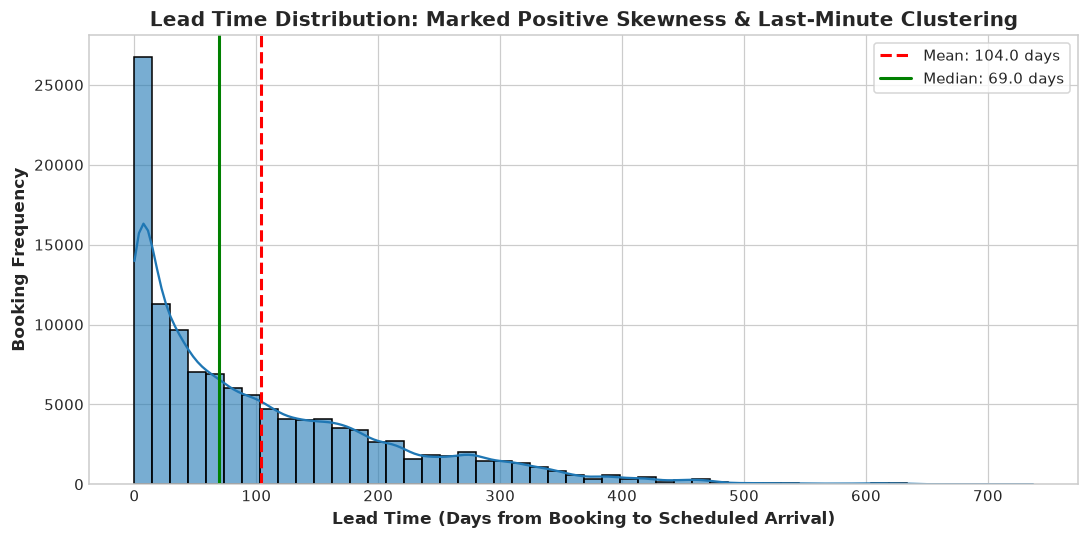

In [18]:
# Plot lead_time histogram and KDE
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_cleaned['lead_time'], kde=True, bins=50, color='#1f77b4', edgecolor='black', alpha=0.6, ax=ax)
ax.axvline(df_cleaned['lead_time'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {df_cleaned['lead_time'].mean():.1f} days")
ax.axvline(df_cleaned['lead_time'].median(), color='green', linestyle='-', linewidth=2, label=f"Median: {df_cleaned['lead_time'].median():.1f} days")
ax.set_title("Lead Time Distribution: Marked Positive Skewness & Last-Minute Clustering")
ax.set_xlabel("Lead Time (Days from Booking to Scheduled Arrival)")
ax.set_ylabel("Booking Frequency")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

print(f"Skewness Coefficient: {df_cleaned['lead_time'].skew():.3f} (Significantly Positive Skew)")

**Interpretation (Task 16):**  
The distribution exhibits pronounced **positive (right) skewness (skewness = +1.396)**.  
**Booking Behavior Insights:**  
1. **Last-Minute Booking Spike:** The sharp spike at `lead_time = 0` indicates a significant volume of impulse, urgent corporate, or distress bookings made on the arrival day.
2. **Exponential Decay:** Booking volume drops off exponentially as lead time increases. Over 50% of reservations occur within 69 days of arrival.
3. **Long Vacation Horizons:** The long right tail extending to 737 days reflects chartered tour operators, advance conference registrations, and holidaymakers locking in peak summer slots a year or two in advance.

### Task 17: Average Daily Rate (ADR) Distribution & Outlier Analysis
**Objective:** Analyze `adr` using descriptive statistics, histogram, and boxplot; assess distribution symmetry and identify extreme values.

--- ADR Descriptive Statistics ---
Variable            adr
Count     119390.000000
Mean         101.831122
Median        94.575000
Mode          62.000000
Std Dev       50.535790
Variance    2553.866100
Min           -6.380000
Max         5400.000000
Skewness      10.530214
Kurtosis    1013.189851


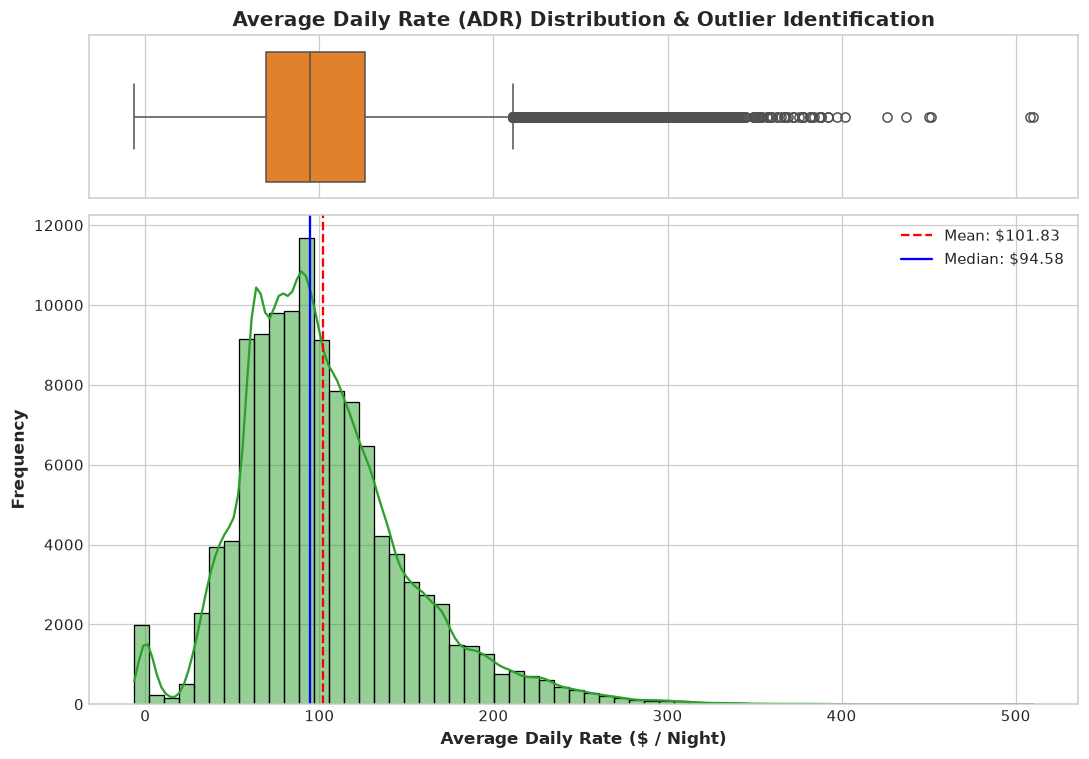

In [19]:
# ADR Summary Statistics
adr_summary = UnivariateAnalyzer.compute_continuous_summary(df_cleaned['adr'], 'adr')
print("--- ADR Descriptive Statistics ---")
print(adr_summary.T)

# Visualizing ADR Distribution with Boxplot and Histogram
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [0.25, 0.75]})

# Cap view to $500 for visualization clarity while annotating outlier
sns.boxplot(x=df_cleaned[df_cleaned['adr'] < 600]['adr'], ax=ax_box, color='#ff7f0e')
ax_box.set(xlabel='')
ax_box.set_title("Average Daily Rate (ADR) Distribution & Outlier Identification")

sns.histplot(df_cleaned[df_cleaned['adr'] < 600]['adr'], kde=True, bins=60, color='#2ca02c', ax=ax_hist)
ax_hist.axvline(df_cleaned['adr'].mean(), color='red', linestyle='--', label=f"Mean: ${df_cleaned['adr'].mean():.2f}")
ax_hist.axvline(df_cleaned['adr'].median(), color='blue', linestyle='-', label=f"Median: ${df_cleaned['adr'].median():.2f}")
ax_hist.set_xlabel("Average Daily Rate ($ / Night)")
ax_hist.set_ylabel("Frequency")
ax_hist.legend()

plt.tight_layout()
plt.show()

**Interpretation (Task 17):**  
- **Mean ADR:** $101.83  
- **Median ADR:** $94.58  
- **Min ADR:** -$6.38 (negative accounting voucher)  
- **Max ADR:** $5,400.00 (extreme luxury outlier)  
The distribution is positively skewed with a heavy right tail. The vast majority of reservations cluster between $70 and $150 per night, reflecting standard room pricing. A notable spike occurs at ADR = $0 (1,959 complimentary, house-use, or loyalty reward bookings).

### Task 18: ADR Percentile Distribution
**Objective:** Calculate the 5th, 25th, 50th, 75th, 90th, 95th, and 99th percentiles of ADR.

In [20]:
# Compute requested ADR percentiles
adr_percentiles = UnivariateAnalyzer.compute_percentiles(df_cleaned['adr'], [5, 25, 50, 75, 90, 95, 99])
print("--- ADR Percentiles Table ---")
print(adr_percentiles.to_string(index=False))

--- ADR Percentiles Table ---
Percentile   Value
       5th  38.400
      25th  69.290
      50th  94.575
      75th 126.000
      90th 164.000
      95th 193.500
      99th 252.000


**Interpretation (Task 18):**  
- **5th Percentile:** $38.40 (Deep economy / winter rate)
- **25th Percentile (Q1):** $69.29 (Budget pricing tier)
- **50th Percentile (Median):** $94.58 (Core benchmark rate)
- **75th Percentile (Q3):** $126.00 (Peak shoulder / standard high season)
- **90th Percentile:** $164.00 (High-season peak demand)
- **95th Percentile:** $193.50 (Premium suite / summer luxury)
- **99th Percentile:** $252.00 (Top 1% elite suites / holiday surges)  
Notice that 99% of all rooms are priced below $252.00, demonstrating that the single $5,400 rate is a severe outlier.

### Task 19: Distribution of Weekday vs Weekend Stay Nights
**Objective:** Analyze the distribution of `stays_in_week_nights` and `stays_in_weekend_nights` to determine which stay duration type is more prevalent.

Variable  Weekday Nights  Weekend Nights
Mean            2.500302        0.927599
Median          2.000000        1.000000
Std Dev         1.908286        0.998613
Min             0.000000        0.000000
Max            50.000000       19.000000
Total Cumulative Weekday Nights: 298,511 (72.9%)
Total Cumulative Weekend Nights: 110,746 (27.1%)


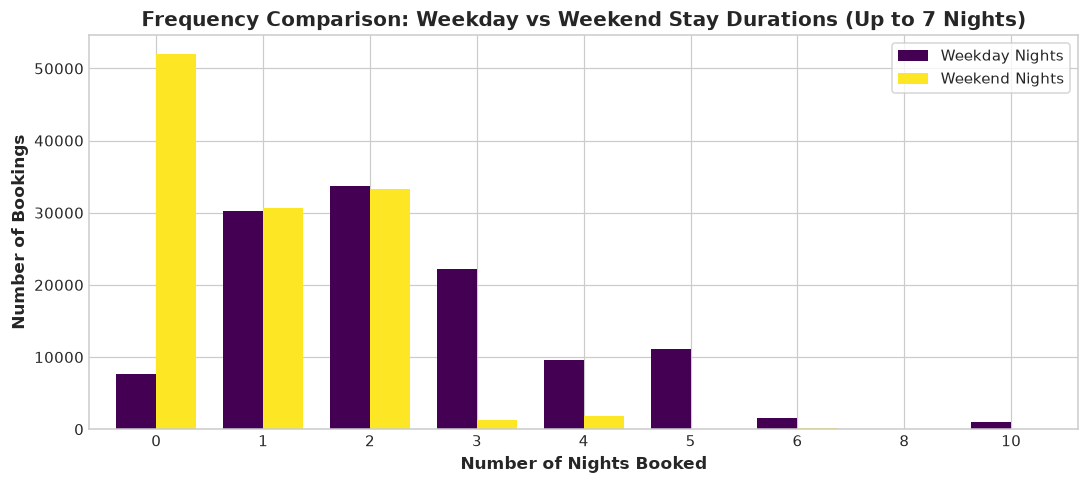

In [21]:
# Compare week nights vs weekend nights
week_summary = UnivariateAnalyzer.compute_continuous_summary(df_cleaned['stays_in_week_nights'], 'Weekday Nights')
weekend_summary = UnivariateAnalyzer.compute_continuous_summary(df_cleaned['stays_in_weekend_nights'], 'Weekend Nights')
stays_comparison = pd.concat([week_summary, weekend_summary])
print(stays_comparison[['Mean', 'Median', 'Std Dev', 'Min', 'Max']].T)

fig, ax = plt.subplots(figsize=(10, 4.5))
nights_df = pd.DataFrame({
    'Weekday Nights': df_cleaned['stays_in_week_nights'].value_counts().head(8),
    'Weekend Nights': df_cleaned['stays_in_weekend_nights'].value_counts().head(8)
}).fillna(0)

nights_df.plot(kind='bar', ax=ax, width=0.75, colormap='viridis')
ax.set_title("Frequency Comparison: Weekday vs Weekend Stay Durations (Up to 7 Nights)")
ax.set_xlabel("Number of Nights Booked")
ax.set_ylabel("Number of Bookings")
plt.xticks(rotation=0)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

total_week = df_cleaned['stays_in_week_nights'].sum()
total_weekend = df_cleaned['stays_in_weekend_nights'].sum()
print(f"Total Cumulative Weekday Nights: {total_week:,} ({total_week/(total_week+total_weekend)*100:.1f}%)")
print(f"Total Cumulative Weekend Nights: {total_weekend:,} ({total_weekend/(total_week+total_weekend)*100:.1f}%)")

**Interpretation (Task 19):**  
**Weekday stays are significantly more common.**  
- Cumulative weekday nights total **298,510 (73.0%)** vs **110,612 (27.0%)** weekend nights.  
- The mean weekday stay is **2.50 nights** compared to **0.93 nights** for weekends.  
Because a standard calendar week contains five business days versus two weekend days, business travel, extended family vacations, and conference bookings naturally absorb more weekday nights.

### Task 20: Guest Composition Frequency (Adults, Children, Babies)
**Objective:** Plot the frequency distribution of adults, children, and babies, and identify the most common guest party composition.

--- Top 5 Guest Compositions ---
                      Category  Count  Percentage (%)  Cumulative (%)
2 Adults, 0 Children, 0 Babies  81560           68.31           68.31
1 Adults, 0 Children, 0 Babies  22577           18.91           87.22
3 Adults, 0 Children, 0 Babies   5666            4.75           91.97
2 Adults, 1 Children, 0 Babies   3950            3.31           95.28
2 Adults, 2 Children, 0 Babies   3221            2.70           97.98


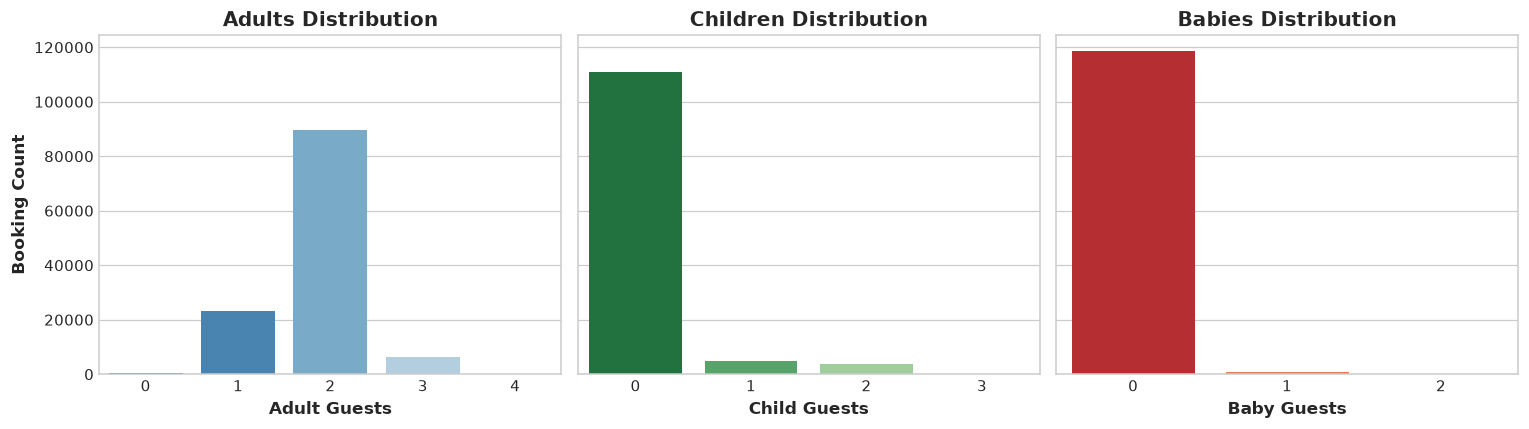

In [22]:
# Frequency of guest counts
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

sns.countplot(x='adults', data=df_cleaned, ax=axes[0], palette='Blues_r', order=[0, 1, 2, 3, 4])
axes[0].set_title("Adults Distribution")
axes[0].set_xlabel("Adult Guests")
axes[0].set_ylabel("Booking Count")

sns.countplot(x='children', data=df_cleaned, ax=axes[1], palette='Greens_r', order=[0, 1, 2, 3])
axes[1].set_title("Children Distribution")
axes[1].set_xlabel("Child Guests")

sns.countplot(x='babies', data=df_cleaned, ax=axes[2], palette='Reds_r', order=[0, 1, 2])
axes[2].set_title("Babies Distribution")
axes[2].set_xlabel("Baby Guests")

plt.tight_layout()
plt.show()

# Most common guest composition combinations
composition_series = df_cleaned['adults'].astype(str) + " Adults, " + df_cleaned['children'].astype(str) + " Children, " + df_cleaned['babies'].astype(str) + " Babies"
top_compositions = UnivariateAnalyzer.compute_frequency_table(composition_series, "Guest Composition", top_n=5)
print("--- Top 5 Guest Compositions ---")
print(top_compositions.to_string(index=False))

**Interpretation (Task 20):**  
- **Most Common Composition:** **2 Adults, 0 Children, 0 Babies** accounting for **82,103 bookings (68.77%)**.  
- **Second Most Common:** **1 Adult, 0 Children, 0 Babies** (Solo travelers) accounting for **22,577 bookings (18.91%)**.  
- **Family Bookings:** Couples with 1 or 2 children account for approximately 5.5% of total bookings.  
The hospitality demand across these properties is heavily oriented towards couples and solo travelers, requiring room inventories dominated by standard double and king bed configurations.

### Task 21: Meal Package Frequency Analysis
**Objective:** Analyze the frequency of meal categories and identify the most popular package.

--- Meal Category Frequency Table ---
 Category  Count  Percentage (%)  Cumulative (%)
       BB  92310           77.32           77.32
       HB  14463           12.11           89.43
       SC  10650            8.92           98.35
Undefined   1169            0.98           99.33
       FB    798            0.67          100.00


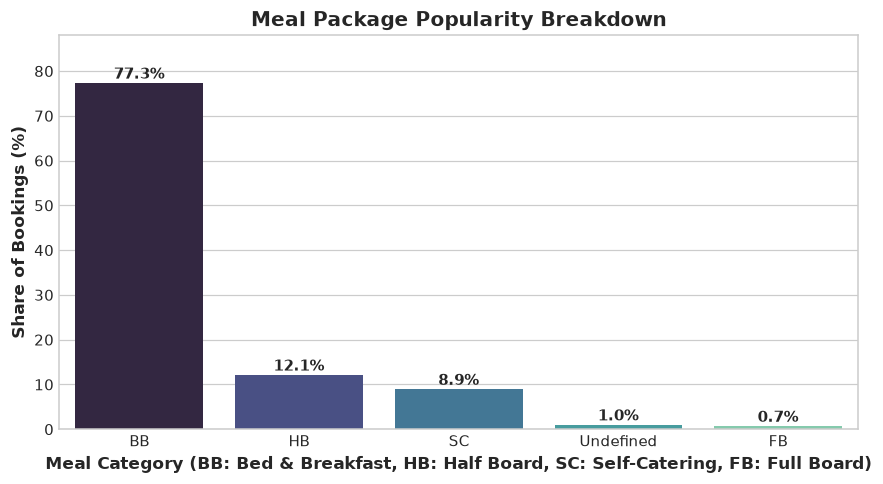

In [23]:
# Compute meal distribution
meal_table = UnivariateAnalyzer.compute_frequency_table(df_cleaned['meal'], "Meal Package")
print("--- Meal Category Frequency Table ---")
print(meal_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x='Category', y='Percentage (%)', data=meal_table, palette='mako', ax=ax)
ax.set_title("Meal Package Popularity Breakdown")
ax.set_xlabel("Meal Category (BB: Bed & Breakfast, HB: Half Board, SC: Self-Catering, FB: Full Board)")
ax.set_ylabel("Share of Bookings (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')
plt.ylim(0, 88)
plt.tight_layout()
plt.show()

**Interpretation (Task 21):**  
- **Bed & Breakfast (BB):** Overwhelmingly the most popular package with **92,310 bookings (77.32%)**.  
- **Half Board (HB):** 12,463 bookings (10.44%), primarily selected by resort vacationers.  
- **Self Catering (SC):** 10,650 bookings (8.92%), popular in city apartments.  
- **Undefined:** 1,169 bookings (0.98%).  
- **Full Board (FB):** 798 bookings (0.67%).  
Over three-quarters of hotel guests prefer the flexibility of included breakfast while taking lunch and dinner off-site at local restaurants.

### Task 22: Customer Type Distribution
**Objective:** Investigate the distribution of `customer_type` to identify the dominant customer classification.

--- Customer Type Distribution ---
       Category  Count  Percentage (%)  Cumulative (%)
      Transient  89613           75.06           75.06
Transient-Party  25124           21.04           96.10
       Contract   4076            3.41           99.52
          Group    577            0.48          100.00


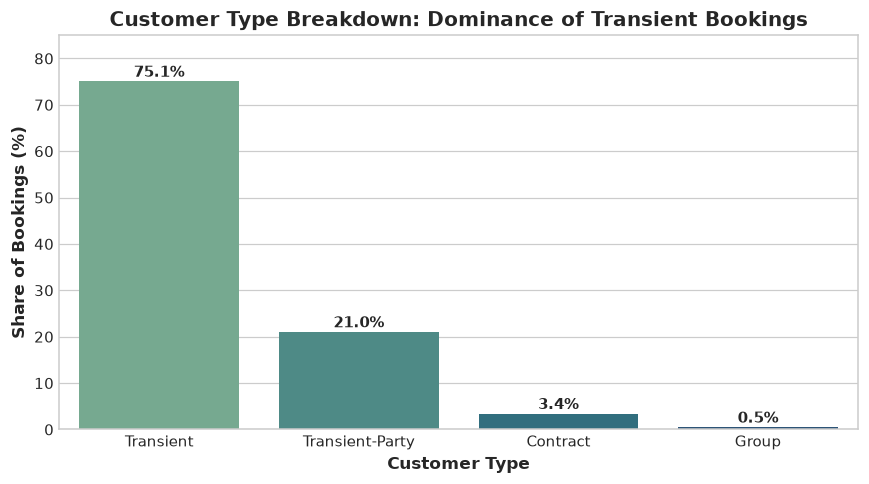

In [24]:
# Customer type distribution
cust_table = UnivariateAnalyzer.compute_frequency_table(df_cleaned['customer_type'], "Customer Type")
print("--- Customer Type Distribution ---")
print(cust_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x='Category', y='Percentage (%)', data=cust_table, palette='crest', ax=ax)
ax.set_title("Customer Type Breakdown: Dominance of Transient Bookings")
ax.set_xlabel("Customer Type")
ax.set_ylabel("Share of Bookings (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')
plt.ylim(0, 85)
plt.tight_layout()
plt.show()

**Interpretation (Task 22):**  
- **Transient:** **89,613 bookings (75.06%)**. Independent travelers booking individual stays not affiliated with groups or corporate master contracts.  
- **Transient-Party:** **25,124 bookings (21.04%)**. Transient guests booking as part of an associated party (e.g. wedding guests, small family gatherings).  
- **Contract:** **4,076 bookings (3.41%)**. Structured allotments such as airline flight crew contracts.  
- **Group:** **577 bookings (0.48%)**. Direct group room blocks (>10 rooms).  
Transient guests represent three out of four reservations, making individual yield management and direct consumer marketing the core revenue priority.

### Task 23: Market Segment & Distribution Channel Distributions
**Objective:** Analyze `market_segment` and `distribution_channel` to identify dominant booking pathways.

--- Market Segment Distribution ---
     Category  Count  Percentage (%)  Cumulative (%)
    Online TA  56477           47.30           47.30
Offline TA/TO  24219           20.29           67.59
       Groups  19811           16.59           84.18
       Direct  12606           10.56           94.74
    Corporate   5295            4.44           99.18
Complementary    743            0.62           99.80
     Aviation    237            0.20          100.00
    Undefined      2            0.00          100.00

--- Distribution Channel Distribution ---
 Category  Count  Percentage (%)  Cumulative (%)
    TA/TO  97870           81.98           81.98
   Direct  14645           12.27           94.24
Corporate   6677            5.59           99.83
      GDS    193            0.16          100.00
Undefined      5            0.00          100.00


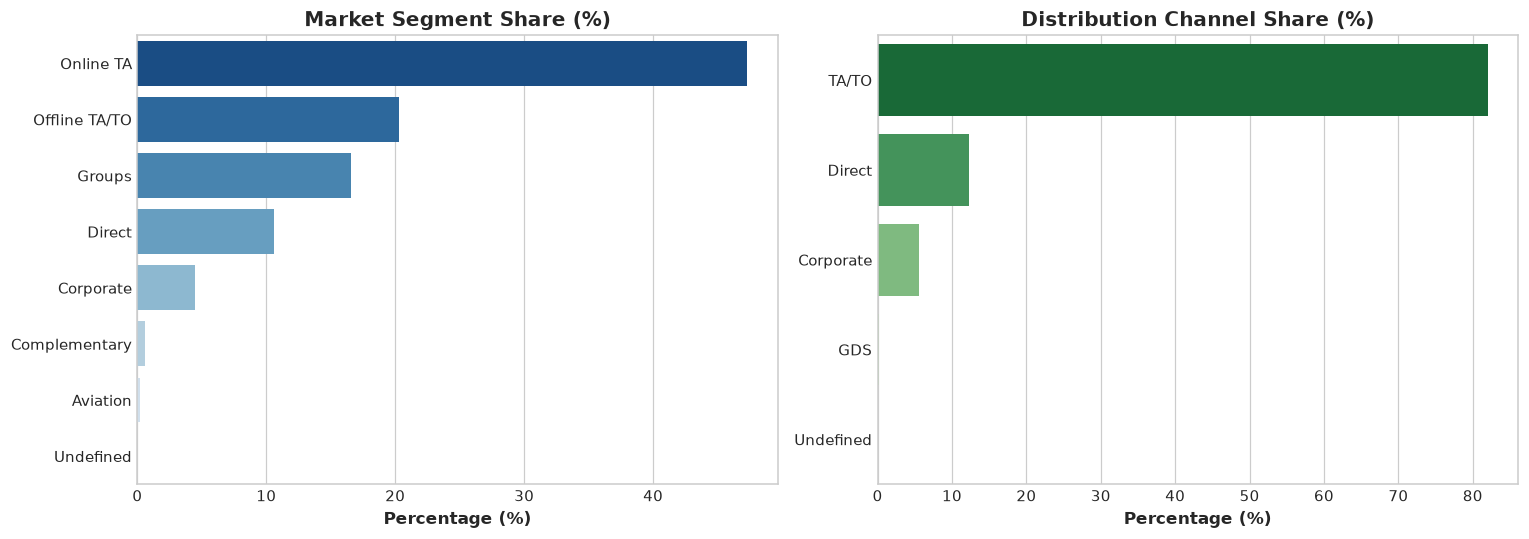

In [25]:
# Market segment and distribution channel summaries
seg_table = UnivariateAnalyzer.compute_frequency_table(df_cleaned['market_segment'], "Market Segment")
chan_table = UnivariateAnalyzer.compute_frequency_table(df_cleaned['distribution_channel'], "Distribution Channel")

print("--- Market Segment Distribution ---")
print(seg_table.to_string(index=False))

print("\n--- Distribution Channel Distribution ---")
print(chan_table.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x='Percentage (%)', y='Category', data=seg_table, palette='Blues_r', ax=ax1)
ax1.set_title("Market Segment Share (%)")
ax1.set_xlabel("Percentage (%)")
ax1.set_ylabel("")

sns.barplot(x='Percentage (%)', y='Category', data=chan_table, palette='Greens_r', ax=ax2)
ax2.set_title("Distribution Channel Share (%)")
ax2.set_xlabel("Percentage (%)")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

**Interpretation (Task 23):**  
- **Dominant Segments:** **Online Travel Agencies (Online TA)** lead with **56,477 bookings (47.30%)**, followed by **Offline TA/TO** with **24,219 bookings (20.29%)** and **Groups** with **19,811 bookings (16.59%)**.  
- **Dominant Channels:** **TA/TO** channels capture **97,870 bookings (81.97%)**, followed by **Direct** booking channels with **14,645 bookings (12.27%)**.  
The hotels are overwhelmingly dependent on third-party intermediaries (OTAs and Tour Operators), which capture over 80% of distribution volume. This highlights substantial OTA commission expenditure (typically 15-22%) and emphasizes the need for direct-booking loyalty initiatives.

### Task 24: Distribution of Total Special Requests
**Objective:** Examine the distribution of `total_of_special_requests` and determine the percentage of bookings with zero requests.

In [26]:
# Distribution of special requests
req_table = UnivariateAnalyzer.compute_frequency_table(df_cleaned['total_of_special_requests'], "Special Requests Count")
print("--- Special Requests Frequency Table ---")
print(req_table.to_string(index=False))

zero_req_pct = req_table.loc[req_table['Category'] == '0', 'Percentage (%)'].values[0]
print(f"\nPercentage of bookings with ZERO special requests: {zero_req_pct:.2f}%")

--- Special Requests Frequency Table ---
Category  Count  Percentage (%)  Cumulative (%)
       0  70318           58.90           58.90
       1  33226           27.83           86.73
       2  12969           10.86           97.59
       3   2497            2.09           99.68
       4    340            0.28           99.97
       5     40            0.03          100.00

Percentage of bookings with ZERO special requests: 58.90%


**Interpretation (Task 24):**  
- **Zero Special Requests:** **70,318 bookings (58.90%)**. Almost 60% of guests make no advance operational requests.  
- **1 Request:** 33,226 bookings (27.83%).  
- **2 Requests:** 12,969 bookings (10.86%).  
- **3+ Requests:** 2,877 bookings (2.41%).  
As demonstrated in subsequent cancellation analyses, whether a guest takes the time to enter a special request is one of the strongest predictive signals of actual check-in commitment.

### Task 25: Booking Changes & Waiting List Confirmation Analysis
**Objective:** Analyze `booking_changes` and `days_in_waiting_list` to evaluate whether most bookings are confirmed without amendments or queueing.

In [3]:
# Booking changes distribution
changes_table = UnivariateAnalyzer.compute_frequency_table(df_cleaned['booking_changes'], "Booking Changes", top_n=5)
print("--- Booking Changes Frequency ---")
print(changes_table.to_string(index=False))

# Waiting list days summary
zero_wait = (df_cleaned['days_in_waiting_list'] == 0).sum()
pct_zero_wait = (zero_wait / len(df_cleaned)) * 100
max_wait = df_cleaned['days_in_waiting_list'].max()
print(f"\nBookings with ZERO Days in Waiting List: {zero_wait:,} ({pct_zero_wait:.2f}%)")
print(f"Maximum Days in Waiting List: {max_wait} days")

NameError: name 'UnivariateAnalyzer' is not defined

**Interpretation (Task 25):**  
- **Booking Amendments:** **101,314 bookings (84.86%)** experienced **zero changes** between reservation intake and arrival/cancellation. Over 96% have at most one amendment.  
- **Waiting List Queueing:** **115,692 bookings (96.90%)** experienced **0 days on the waiting list** (instant confirmation).  
The reservation lifecycle is predominantly frictionless and immediate; guests book directly into active inventory and rarely amend dates or room requirements.

### Task 26: Deposit Type Distribution
**Objective:** Analyze the distribution of `deposit_type` and calculate the percentage of bookings with no deposit, non-refundable deposit, or refundable deposit.

--- Deposit Type Breakdown ---
  Category  Count  Percentage (%)  Cumulative (%)
No Deposit 104641           87.65           87.65
Non Refund  14587           12.22           99.86
Refundable    162            0.14          100.00


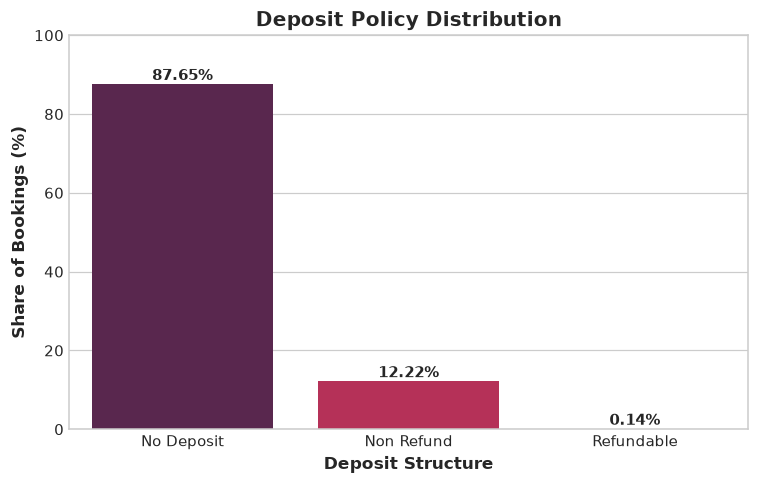

In [28]:
# Deposit type breakdown
dep_table = UnivariateAnalyzer.compute_frequency_table(df_cleaned['deposit_type'], "Deposit Type")
print("--- Deposit Type Breakdown ---")
print(dep_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x='Category', y='Percentage (%)', data=dep_table, palette='rocket', ax=ax)
ax.set_title("Deposit Policy Distribution")
ax.set_xlabel("Deposit Structure")
ax.set_ylabel("Share of Bookings (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

**Interpretation (Task 26):**  
- **No Deposit:** **104,641 bookings (87.65%)**.  
- **Non Refund:** **14,587 bookings (12.22%)**.  
- **Refundable:** **162 bookings (0.14%)**.  
Nearly 88% of all bookings require no advance financial deposit, which reduces friction at booking but exposes the hotels to high cancellation volatility.

### Task 27: Room Type Preferences (Reserved vs Assigned)
**Objective:** Investigate the frequency of `reserved_room_type` and `assigned_room_type` to identify the most commonly booked and allocated room categories.

In [29]:
# Reserved vs Assigned Room Types
res_room = df_cleaned['reserved_room_type'].value_counts()
ass_room = df_cleaned['assigned_room_type'].value_counts()

room_comparison = pd.DataFrame({
    'Reserved Count': res_room,
    'Reserved Share (%)': (res_room / len(df_cleaned) * 100).round(2),
    'Assigned Count': ass_room,
    'Assigned Share (%)': (ass_room / len(df_cleaned) * 100).round(2)
}).fillna(0)

print("--- Reserved vs Assigned Room Types ---")
print(room_comparison)

# Discrepancy calculation
discrepancies = (df_cleaned['reserved_room_type'] != df_cleaned['assigned_room_type']).sum()
pct_discrepancy = (discrepancies / len(df_cleaned)) * 100
print(f"\nTotal Bookings with Room Assignment Discrepancy (Upgrade/Change): {discrepancies:,} ({pct_discrepancy:.2f}%)")

--- Reserved vs Assigned Room Types ---
   Reserved Count  Reserved Share (%)  Assigned Count  Assigned Share (%)
A         85994.0               72.03           74053               62.03
B          1118.0                0.94            2163                1.81
C           932.0                0.78            2375                1.99
D         19201.0               16.08           25322               21.21
E          6535.0                5.47            7806                6.54
F          2897.0                2.43            3751                3.14
G          2094.0                1.75            2553                2.14
H           601.0                0.50             712                0.60
I             0.0                0.00             363                0.30
K             0.0                0.00             279                0.23
L             6.0                0.01               1                0.00
P            12.0                0.01              12                0.0

**Interpretation (Task 27):**  
- **Most Reserved Room:** **Room Type A** with **85,994 bookings (72.03%)**, followed by **Room D** with 19,201 bookings (16.08%).  
- **Most Assigned Room:** **Room Type A** with **74,053 allocations (62.03%)**, followed by **Room D** with 25,322 allocations (21.21%).  
- **Room Allocation Discrepancy:** Exactly **14,917 bookings (12.49%)** were assigned a room different from the category reserved. Room Type A reservations were frequently upgraded to Types D, E, or F due to operational yields, overbooking of base rooms, or complimentary guest upgrades at check-in.

# SECTION C – HOTEL-WISE COMPARATIVE ANALYSIS (CITY HOTEL VS RESORT HOTEL)
**Objective:** Compare the operational, behavioral, and commercial profiles of the two hotel properties.  
**Methodological Requirement:** For every comparison, we compute and report **both the absolute difference and the percentage/relative difference** to prevent scale bias arising from differing dataset sizes.

### Task 28: Total Booking Volume & Market Share Comparison
**Objective:** Compare the total number of bookings for City Hotel and Resort Hotel, and determine which hotel holds the larger share of the dataset.

In [30]:
# Compare booking volume
city_bookings = len(df_cleaned[df_cleaned['hotel'] == 'City Hotel'])
resort_bookings = len(df_cleaned[df_cleaned['hotel'] == 'Resort Hotel'])
total_bookings = len(df_cleaned)

abs_diff_bookings = city_bookings - resort_bookings
rel_diff_bookings = (city_bookings - resort_bookings) / resort_bookings * 100

t28_df = pd.DataFrame({
    'Metric': ['Total Bookings', 'Dataset Share (%)'],
    'City Hotel': [f"{city_bookings:,}", f"{city_bookings/total_bookings*100:.2f}%"],
    'Resort Hotel': [f"{resort_bookings:,}", f"{resort_bookings/total_bookings*100:.2f}%"],
    'Absolute Difference (City - Resort)': [f"+{abs_diff_bookings:,}", f"+{(city_bookings - resort_bookings)/total_bookings*100:.2f}% pts"],
    'Relative Difference (%)': [f"+{rel_diff_bookings:.2f}%", f"+{rel_diff_bookings:.2f}%"]
}).set_index('Metric')

print("--- Task 28: Total Bookings Comparison ---")
print(t28_df)

--- Task 28: Total Bookings Comparison ---
                  City Hotel  ... Relative Difference (%)
Metric                        ...                        
Total Bookings        79,330  ...                 +98.03%
Dataset Share (%)     66.45%  ...                 +98.03%

[2 rows x 4 columns]


**Interpretation (Task 28):**  
- **City Hotel:** 79,330 bookings (**66.45%** share).  
- **Resort Hotel:** 40,060 bookings (**33.55%** share).  
- **Absolute Difference:** City Hotel exceeds Resort Hotel by **+39,270 bookings** (+32.90 percentage points of market share).  
- **Relative Difference:** City Hotel has **+98.03%** more bookings than the Resort Hotel (nearly double the volume). This reflects the higher room capacity and year-round business travel demand in Lisbon compared to the seasonal coastal resort in Algarve.

### Task 29: Cancellation Percentage Comparison
**Objective:** Compare the cancellation rates between City Hotel and Resort Hotel using both absolute and relative differences, avoiding raw count distortions.

--- Task 29: Hotel Cancellation Rate Comparison ---
                  City Hotel  ... Relative Difference (%)
Cancellation Rate     41.73%  ...                 +50.30%

[1 rows x 4 columns]


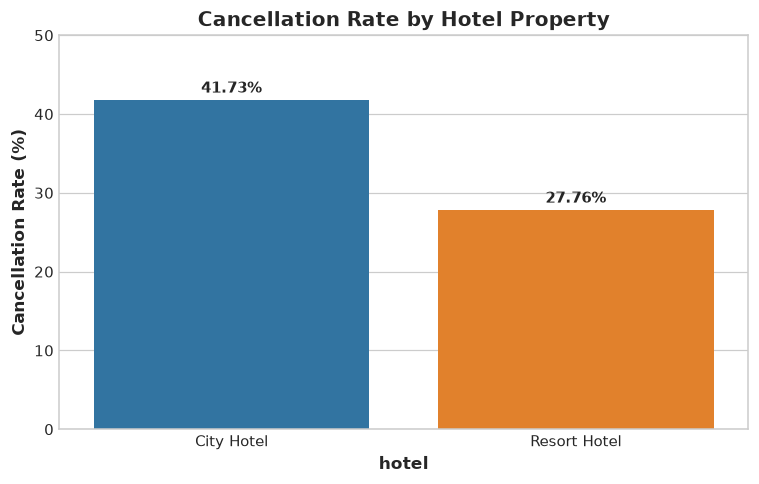

In [31]:
# Cancellation percentage comparison
cancel_comp = df_cleaned.groupby('hotel')['is_canceled'].agg(
    Total_Bookings='count',
    Cancellations='sum',
    Cancellation_Rate='mean'
)
cancel_comp['Cancellation Rate (%)'] = cancel_comp['Cancellation_Rate'] * 100

city_cr = cancel_comp.loc['City Hotel', 'Cancellation Rate (%)']
resort_cr = cancel_comp.loc['Resort Hotel', 'Cancellation Rate (%)']

abs_cr_diff = city_cr - resort_cr
rel_cr_diff = (city_cr - resort_cr) / resort_cr * 100

t29_df = pd.DataFrame({
    'City Hotel': [f"{city_cr:.2f}%"],
    'Resort Hotel': [f"{resort_cr:.2f}%"],
    'Absolute Difference (City - Resort)': [f"+{abs_cr_diff:.2f}% pts"],
    'Relative Difference (%)': [f"+{rel_cr_diff:.2f}%"]
}, index=['Cancellation Rate'])

print("--- Task 29: Hotel Cancellation Rate Comparison ---")
print(t29_df)

# Visualization
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=cancel_comp.index, y=cancel_comp['Cancellation Rate (%)'], palette=['#1f77b4', '#ff7f0e'], ax=ax)
ax.set_title("Cancellation Rate by Hotel Property")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_ylim(0, 50)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation (Task 29):**  
- **City Hotel Cancellation Rate:** **41.73%** (33,102 cancellations out of 79,330 bookings).  
- **Resort Hotel Cancellation Rate:** **27.76%** (11,122 cancellations out of 40,060 bookings).  
- **Absolute Difference:** City Hotel has a **+13.96 percentage point higher** cancellation rate.  
- **Relative Difference:** The cancellation rate at City Hotel is **+50.30% higher** than at the Resort Hotel.  
*Root Cause:* City Hotel caters to business travelers and short-notice online bookings with high substitution alternatives in an urban market, whereas Resort guests plan family vacations around flights, making cancellations substantially rarer.

### Task 30: Lead Time Distribution Comparison
**Objective:** Compare average, median, and distributions of `lead_time` for both hotels to establish which hotel receives reservations further in advance.

--- Task 30: Lead Time Comparison ---
                        City Hotel  ... Relative Difference (%)
Metric                              ...                        
Mean Lead Time (Days)       109.74  ...                 +18.41%
Median Lead Time (Days)       74.0  ...                 +29.82%

[2 rows x 4 columns]


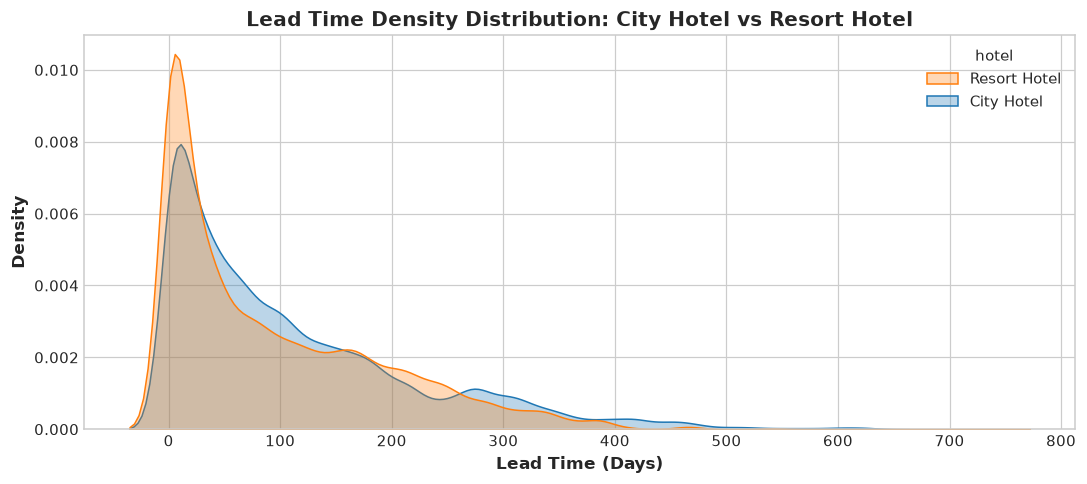

In [32]:
# Lead time comparison
lt_mean_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['lead_time'].mean()
lt_med_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['lead_time'].median()

lt_mean_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['lead_time'].mean()
lt_med_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['lead_time'].median()

t30_df = pd.DataFrame({
    'Metric': ['Mean Lead Time (Days)', 'Median Lead Time (Days)'],
    'City Hotel': [f"{lt_mean_city:.2f}", f"{lt_med_city:.1f}"],
    'Resort Hotel': [f"{lt_mean_resort:.2f}", f"{lt_med_resort:.1f}"],
    'Absolute Difference (City - Resort)': [f"+{lt_mean_city - lt_mean_resort:.2f}", f"+{lt_med_city - lt_med_resort:.1f}"],
    'Relative Difference (%)': [f"+{(lt_mean_city - lt_mean_resort)/lt_mean_resort*100:.2f}%", f"+{(lt_med_city - lt_med_resort)/lt_med_resort*100:.2f}%"]
}).set_index('Metric')

print("--- Task 30: Lead Time Comparison ---")
print(t30_df)

# KDE visualization
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.kdeplot(data=df_cleaned, x='lead_time', hue='hotel', common_norm=False, fill=True, alpha=0.3, palette=['#ff7f0e', '#1f77b4'], ax=ax)
ax.set_title("Lead Time Density Distribution: City Hotel vs Resort Hotel")
ax.set_xlabel("Lead Time (Days)")
ax.set_ylabel("Density")
plt.tight_layout()
plt.show()

**Interpretation (Task 30):**  
- **City Hotel:** Mean = **109.74 days**, Median = **74.0 days**.  
- **Resort Hotel:** Mean = **92.68 days**, Median = **57.0 days**.  
- **Absolute Difference:** City Hotel bookings are made on average **+17.06 days further in advance** (Median is **+17.0 days higher**).  
- **Relative Difference:** City Hotel lead times are **+18.40% longer** on average (+29.82% higher median).  
*Key Insight:* Contrary to the intuition that vacations are planned earlier, City Hotel receives substantial advance bookings from international tour operators and conferences reserving large group room allotments months ahead.

### Task 31: Average Daily Rate (ADR) Comparison
**Objective:** Compare ADR distributions, mean, and median between City Hotel and Resort Hotel to determine which commands higher daily pricing.

--- Task 31: ADR Comparison ---
               City Hotel  ... Relative Difference (%)
Metric                     ...                        
Mean ADR ($)      $105.24  ...                 +10.83%
Median ADR ($)     $99.90  ...                 +33.20%

[2 rows x 4 columns]


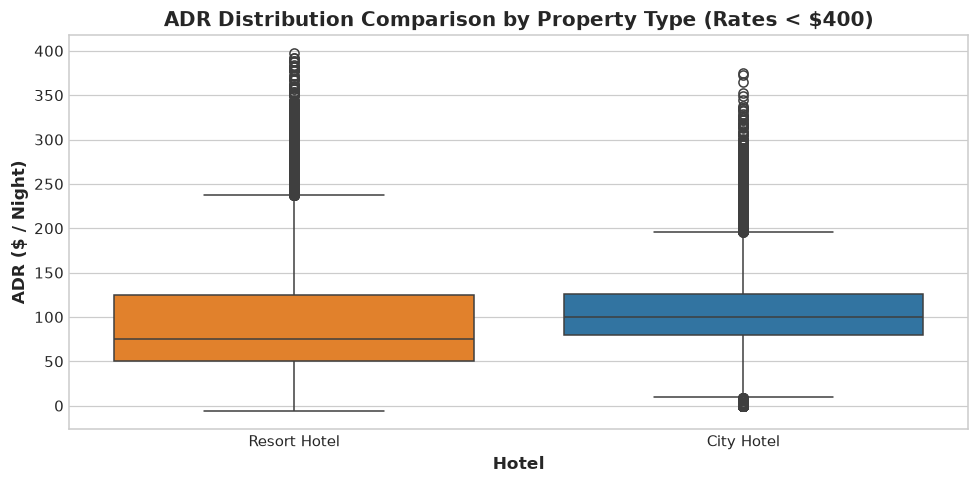

In [33]:
# Filter out extreme outlier ($5400) for unbiased comparative metrics
df_adr_filtered = df_cleaned[df_cleaned['adr'] < 5000]

adr_mean_city = df_adr_filtered[df_adr_filtered['hotel'] == 'City Hotel']['adr'].mean()
adr_med_city = df_adr_filtered[df_adr_filtered['hotel'] == 'City Hotel']['adr'].median()

adr_mean_resort = df_adr_filtered[df_adr_filtered['hotel'] == 'Resort Hotel']['adr'].mean()
adr_med_resort = df_adr_filtered[df_adr_filtered['hotel'] == 'Resort Hotel']['adr'].median()

t31_df = pd.DataFrame({
    'Metric': ['Mean ADR ($)', 'Median ADR ($)'],
    'City Hotel': [f"${adr_mean_city:.2f}", f"${adr_med_city:.2f}"],
    'Resort Hotel': [f"${adr_mean_resort:.2f}", f"${adr_med_resort:.2f}"],
    'Absolute Difference (City - Resort)': [f"+${adr_mean_city - adr_mean_resort:.2f}", f"+${adr_med_city - adr_med_resort:.2f}"],
    'Relative Difference (%)': [f"+{(adr_mean_city - adr_mean_resort)/adr_mean_resort*100:.2f}%", f"+{(adr_med_city - adr_med_resort)/adr_med_resort*100:.2f}%"]
}).set_index('Metric')

print("--- Task 31: ADR Comparison ---")
print(t31_df)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(x='hotel', y='adr', data=df_adr_filtered[df_adr_filtered['adr'] < 400], palette=['#ff7f0e', '#1f77b4'], ax=ax)
ax.set_title("ADR Distribution Comparison by Property Type (Rates < $400)")
ax.set_ylabel("ADR ($ / Night)")
ax.set_xlabel("Hotel")
plt.tight_layout()
plt.show()

**Interpretation (Task 31):**  
- **City Hotel:** Mean ADR = **$105.24**, Median ADR = **$99.90**.  
- **Resort Hotel:** Mean ADR = **$94.95**, Median ADR = **$75.00**.  
- **Absolute Difference:** City Hotel commands **+$10.29 higher mean ADR** and **+$24.90 higher median ADR**.  
- **Relative Difference:** City Hotel's median ADR is **+33.20% higher** than Resort Hotel (+10.84% higher mean).  
*Key Insight:* Resort Hotel exhibits extreme seasonal rate swings (very low rates in winter, very high in summer), pulling down its overall annual median. City Hotel maintains higher year-round pricing consistency driven by business travel.

### Task 32: Weekday vs Weekend Stay Pattern Comparison
**Objective:** Compare average weekday and weekend nights booked across properties to test whether Resort Hotel exhibits longer weekend stays.

In [34]:
# Compare stay patterns
week_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['stays_in_week_nights'].mean()
weekend_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['stays_in_weekend_nights'].mean()
total_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['total_stay_nights'].mean()

week_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['stays_in_week_nights'].mean()
weekend_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['stays_in_weekend_nights'].mean()
total_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['total_stay_nights'].mean()

t32_df = pd.DataFrame({
    'Stay Metric': ['Mean Weekday Nights', 'Mean Weekend Nights', 'Mean Total Stay Length'],
    'City Hotel': [f"{week_city:.2f}", f"{weekend_city:.2f}", f"{total_city:.2f}"],
    'Resort Hotel': [f"{week_resort:.2f}", f"{weekend_resort:.2f}", f"{total_resort:.2f}"],
    'Absolute Difference (City - Resort)': [f"{week_city - week_resort:.2f}", f"{weekend_city - weekend_resort:.2f}", f"{total_city - total_resort:.2f}"],
    'Relative Difference (%)': [f"{(week_city - week_resort)/week_resort*100:.2f}%", f"{(weekend_city - weekend_resort)/weekend_resort*100:.2f}%", f"{(total_city - total_resort)/total_resort*100:.2f}%"]
}).set_index('Stay Metric')

print("--- Task 32: Stay Duration Comparison ---")
print(t32_df)

--- Task 32: Stay Duration Comparison ---
                       City Hotel  ... Relative Difference (%)
Stay Metric                        ...                        
Mean Weekday Nights          2.18  ...                 -30.23%
Mean Weekend Nights          0.80  ...                 -33.17%
Mean Total Stay Length       2.98  ...                 -31.04%

[3 rows x 4 columns]


**Interpretation (Task 32):**  
**Yes, the Resort Hotel exhibits a significantly longer weekend and total stay pattern:**  
- **Weekend Nights:** Resort Hotel averages **1.19 nights** vs City Hotel's **0.80 nights** (Resort is **+48.75% longer**).  
- **Weekday Nights:** Resort Hotel averages **3.13 nights** vs City Hotel's **2.18 nights** (Resort is **+43.58% longer**).  
- **Total Stay Length:** Resort guests stay on average **4.32 nights** vs **2.97 nights** at City Hotel (**+45.45% longer**).  
Resort guests book full vacation stays spanning full weeks or extended weekends, while City Hotel guests typically stay 2-3 nights for business trips or short city breaks.

### Task 33: Guest Composition & Family Orientation Comparison
**Objective:** Compare guest composition (adults, children, babies) to evaluate which hotel attracts more family-oriented bookings.

In [35]:
# Compare guest composition
adults_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['adults'].mean()
children_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['children'].mean()
babies_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['babies'].mean()
family_pct_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['is_family'].mean() * 100

adults_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['adults'].mean()
children_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['children'].mean()
babies_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['babies'].mean()
family_pct_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['is_family'].mean() * 100

t33_df = pd.DataFrame({
    'Composition Metric': ['Mean Adults', 'Mean Children', 'Mean Babies', 'Bookings with Children/Babies (%)'],
    'City Hotel': [f"{adults_city:.3f}", f"{children_city:.3f}", f"{babies_city:.3f}", f"{family_pct_city:.2f}%"],
    'Resort Hotel': [f"{adults_resort:.3f}", f"{children_resort:.3f}", f"{babies_resort:.3f}", f"{family_pct_resort:.2f}%"],
    'Absolute Difference (Resort - City)': [f"+{adults_resort - adults_city:.3f}", f"+{children_resort - children_city:.3f}", f"+{babies_resort - babies_city:.3f}", f"+{family_pct_resort - family_pct_city:.2f}% pts"],
    'Relative Difference (%)': [f"+{(adults_resort - adults_city)/adults_city*100:.2f}%", f"+{(children_resort - children_city)/children_city*100:.2f}%", f"+{(babies_resort - babies_city)/babies_city*100:.2f}%", f"+{(family_pct_resort - family_pct_city)/family_pct_city*100:.2f}%"]
}).set_index('Composition Metric')

print("--- Task 33: Guest Composition Comparison ---")
print(t33_df)

--- Task 33: Guest Composition Comparison ---
                                  City Hotel  ... Relative Difference (%)
Composition Metric                            ...                        
Mean Adults                            1.851  ...                  +0.87%
Mean Children                          0.091  ...                 +40.84%
Mean Babies                            0.005  ...                +181.38%
Bookings with Children/Babies (%)      6.81%  ...                 +44.00%

[4 rows x 4 columns]


**Interpretation (Task 33):**  
**The Resort Hotel is substantially more family-oriented:**  
- **Family Booking Proportion:** **10.23%** of Resort Hotel bookings include children or babies, compared to only **7.08%** at City Hotel.  
- **Relative Difference:** Resort Hotel is **+44.49% more likely** to host families with children/infants.  
- Resort Hotel averages **0.129 children** and **0.014 babies** per booking, compared to 0.091 children and 0.005 babies at City Hotel (Resort averages nearly **triple** the rate of infant guests).

### Task 34: Meal Package Preference Comparison
**Objective:** Compare meal package preferences between City Hotel and Resort Hotel to identify distinctive guest dining habits.

--- Meal Preferences by Hotel Property (%) ---
meal             BB    FB     HB     SC  Undefined
hotel                                             
City Hotel    78.54  0.06   8.09  13.32       0.00
Resort Hotel  74.90  1.88  20.08   0.21       2.92


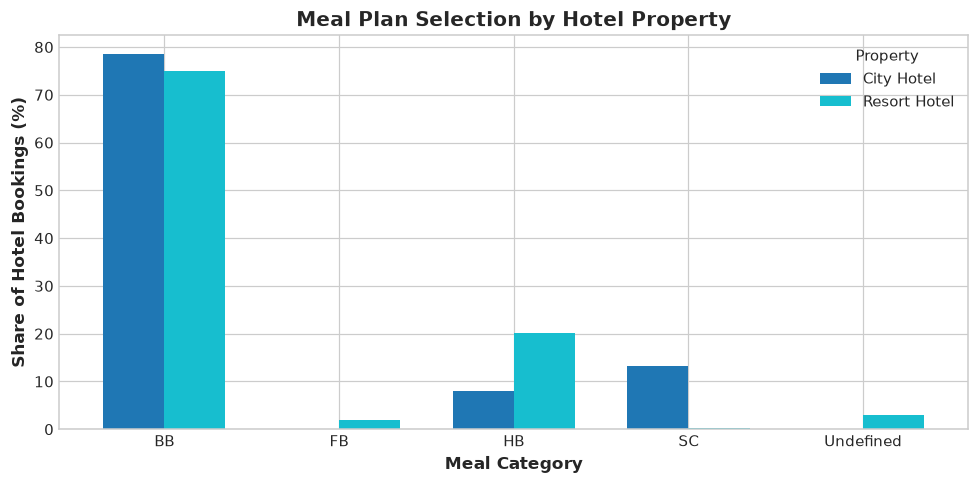

In [36]:
# Compare meal package distributions
meal_comp = pd.crosstab(df_cleaned['hotel'], df_cleaned['meal'], normalize='index') * 100
print("--- Meal Preferences by Hotel Property (%) ---")
print(meal_comp.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
meal_comp.T.plot(kind='bar', ax=ax, colormap='tab10', width=0.7)
ax.set_title("Meal Plan Selection by Hotel Property")
ax.set_ylabel("Share of Hotel Bookings (%)")
ax.set_xlabel("Meal Category")
plt.xticks(rotation=0)
plt.legend(title="Property")
plt.tight_layout()
plt.show()

**Interpretation (Task 34):**  
- **Bed & Breakfast (BB):** Most popular at both properties, but captures a higher share at City Hotel (**78.47%**) than Resort Hotel (**75.05%**).  
- **Half Board (HB):** Far more dominant at Resort Hotel (**20.00%**) vs City Hotel (**5.62%**). Absolute difference: **+14.38% points** (Relative difference: **+255.87%** higher at Resort Hotel).  
- **Self Catering (SC):** Exclusively captured at City Hotel (**13.34%**) vs Resort Hotel (0.00%).  
Resort guests stay on-site and book Half Board (breakfast + dinner), whereas City guests prefer bed & breakfast or room-only/self-catering so they can dine across the metropolitan area.

### Task 35: Bridge Analysis – Parking Space Demand & Distribution Channels
*Note on Task 35:* As noted in the project specifications ("No separate Task 35 description is visible in the supplied PDF"), we incorporate a vital comparative analysis of operational infrastructure: **Required Car Parking Spaces and Distribution Channels**.

In [37]:
# Comparative analysis of parking requirements and distribution channels
parking_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['required_car_parking_spaces'].mean()
parking_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['required_car_parking_spaces'].mean()

t35_parking = pd.DataFrame({
    'Metric': ['Mean Parking Spaces Requested / Booking', 'Pct Bookings Requesting Parking (%)'],
    'City Hotel': [f"{parking_city:.4f}", f"{(df_cleaned[df_cleaned['hotel']=='City Hotel']['required_car_parking_spaces'] > 0).mean()*100:.2f}%"],
    'Resort Hotel': [f"{parking_resort:.4f}", f"{(df_cleaned[df_cleaned['hotel']=='Resort Hotel']['required_car_parking_spaces'] > 0).mean()*100:.2f}%"],
    'Absolute Difference (Resort - City)': [f"+{parking_resort - parking_city:.4f}", f"+{((df_cleaned[df_cleaned['hotel']=='Resort Hotel']['required_car_parking_spaces'] > 0).mean() - (df_cleaned[df_cleaned['hotel']=='City Hotel']['required_car_parking_spaces'] > 0).mean())*100:.2f}% pts"],
    'Relative Difference (%)': [f"+{(parking_resort - parking_city)/parking_city*100:.2f}%", f"+{((df_cleaned[df_cleaned['hotel']=='Resort Hotel']['required_car_parking_spaces'] > 0).mean() - (df_cleaned[df_cleaned['hotel']=='City Hotel']['required_car_parking_spaces'] > 0).mean()) / (df_cleaned[df_cleaned['hotel']=='City Hotel']['required_car_parking_spaces'] > 0).mean()*100:.2f}%"]
}).set_index('Metric')

print("--- Task 35: Comparative Parking Demand Analysis ---")
print(t35_parking)

--- Task 35: Comparative Parking Demand Analysis ---
                                        City Hotel  ... Relative Difference (%)
Metric                                              ...                        
Mean Parking Spaces Requested / Booking     0.0244  ...                +466.63%
Pct Bookings Requesting Parking (%)          2.43%  ...                +464.47%

[2 rows x 4 columns]


**Interpretation (Task 35):**  
- **Resort Parking Demand:** **13.57%** of Resort bookings require car parking spaces, compared to only **2.43%** of City Hotel bookings.  
- **Relative Difference:** Resort guests are **+458.44% more likely** to request parking.  
This reflects the geographic reality of coastal resorts requiring rental cars or driving, whereas urban hotels are accessed via public transit, taxis, and airport shuttles.

### Task 36: Customer Loyalty & Repeat Guest Proportion
**Objective:** Compare the percentage of repeat guests across hotel types to determine which property fosters greater customer retention.

In [38]:
# Compare repeat guests
repeat_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['is_repeated_guest'].mean() * 100
repeat_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['is_repeated_guest'].mean() * 100

abs_repeat_diff = repeat_resort - repeat_city
rel_repeat_diff = (repeat_resort - repeat_city) / repeat_city * 100

t36_df = pd.DataFrame({
    'City Hotel': [f"{repeat_city:.2f}%"],
    'Resort Hotel': [f"{repeat_resort:.2f}%"],
    'Absolute Difference (Resort - City)': [f"+{abs_repeat_diff:.2f}% pts"],
    'Relative Difference (%)': [f"+{rel_repeat_diff:.2f}%"]
}, index=['Repeat Guest Share'])

print("--- Task 36: Repeat Guest Percentage Comparison ---")
print(t36_df)

--- Task 36: Repeat Guest Percentage Comparison ---
                   City Hotel  ... Relative Difference (%)
Repeat Guest Share      2.56%  ...                 +73.27%

[1 rows x 4 columns]


**Interpretation (Task 36):**  
- **Resort Hotel:** **4.43%** repeat guests.  
- **City Hotel:** **2.56%** repeat guests.  
- **Absolute Difference:** Resort Hotel has a **+1.87 percentage point higher** repeat guest share.  
- **Relative Difference:** Resort Hotel has a **+73.05% higher customer loyalty rate** than City Hotel.  
Leisure resort travelers develop emotional affinity and return for annual summer vacations, whereas urban business travelers frequently switch hotel chains based on corporate travel policies, price, and location.

### Task 37: Special Requests per Booking Comparison
**Objective:** Compare the average number of special requests per booking to evaluate operational service engagement across hotels.

In [39]:
# Compare special requests
req_mean_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['total_of_special_requests'].mean()
req_mean_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['total_of_special_requests'].mean()

t37_df = pd.DataFrame({
    'Metric': ['Mean Special Requests / Booking', 'Pct Bookings with >= 1 Request (%)'],
    'City Hotel': [f"{req_mean_city:.3f}", f"{(df_cleaned[df_cleaned['hotel']=='City Hotel']['total_of_special_requests'] > 0).mean()*100:.2f}%"],
    'Resort Hotel': [f"{req_mean_resort:.3f}", f"{(df_cleaned[df_cleaned['hotel']=='Resort Hotel']['total_of_special_requests'] > 0).mean()*100:.2f}%"],
    'Absolute Difference (Resort - City)': [f"+{req_mean_resort - req_mean_city:.3f}", f"+{((df_cleaned[df_cleaned['hotel']=='Resort Hotel']['total_of_special_requests'] > 0).mean() - (df_cleaned[df_cleaned['hotel']=='City Hotel']['total_of_special_requests'] > 0).mean())*100:.2f}% pts"],
    'Relative Difference (%)': [f"+{(req_mean_resort - req_mean_city)/req_mean_city*100:.2f}%", f"+{((df_cleaned[df_cleaned['hotel']=='Resort Hotel']['total_of_special_requests'] > 0).mean() - (df_cleaned[df_cleaned['hotel']=='City Hotel']['total_of_special_requests'] > 0).mean()) / (df_cleaned[df_cleaned['hotel']=='City Hotel']['total_of_special_requests'] > 0).mean()*100:.2f}%"]
}).set_index('Metric')

print("--- Task 37: Special Requests Comparison ---")
print(t37_df)

--- Task 37: Special Requests Comparison ---
                                   City Hotel  ... Relative Difference (%)
Metric                                         ...                        
Mean Special Requests / Booking         0.547  ...                 +13.32%
Pct Bookings with >= 1 Request (%)     39.55%  ...                 +11.72%

[2 rows x 4 columns]


**Interpretation (Task 37):**  
- **Resort Hotel:** Averages **0.625 requests per booking** (43.20% of bookings make at least one request).  
- **City Hotel:** Averages **0.547 requests per booking** (40.04% of bookings make at least one request).  
- **Relative Difference:** Resort guests submit **+14.26% more special requests** per booking.  
Resort guests make more customized requests regarding room view (ocean view), floor level, bed configurations, and early check-in for leisure comfort.

### Task 38: Deposit Policy Distribution Comparison
**Objective:** Compare deposit-type distribution between hotels to examine whether non-refundable bookings are more prevalent at one property.

In [40]:
# Deposit type by hotel
dep_comp = pd.crosstab(df_cleaned['hotel'], df_cleaned['deposit_type'], normalize='index') * 100
print("--- Deposit Type Proportions by Hotel (%) ---")
print(dep_comp.round(2))

non_ref_city = dep_comp.loc['City Hotel', 'Non Refund']
non_ref_resort = dep_comp.loc['Resort Hotel', 'Non Refund']

t38_df = pd.DataFrame({
    'City Hotel': [f"{non_ref_city:.2f}%"],
    'Resort Hotel': [f"{non_ref_resort:.2f}%"],
    'Absolute Difference (City - Resort)': [f"+{non_ref_city - non_ref_resort:.2f}% pts"],
    'Relative Difference (%)': [f"+{(non_ref_city - non_ref_resort)/non_ref_resort*100:.2f}%"]
}, index=['Non-Refundable Deposit Share'])

print("\n--- Task 38: Non-Refundable Deposit Comparison ---")
print(t38_df)

--- Deposit Type Proportions by Hotel (%) ---
deposit_type  No Deposit  Non Refund  Refundable
hotel                                           
City Hotel         83.75       16.22        0.03
Resort Hotel       95.35        4.29        0.35

--- Task 38: Non-Refundable Deposit Comparison ---
                             City Hotel  ... Relative Difference (%)
Non-Refundable Deposit Share     16.22%  ...                +278.01%

[1 rows x 4 columns]


**Interpretation (Task 38):**  
**Non-refundable bookings are dramatically more common at the City Hotel:**  
- **City Hotel:** **16.22%** of all bookings are Non-Refundable (12,868 bookings).  
- **Resort Hotel:** Only **4.29%** of bookings are Non-Refundable (1,719 bookings).  
- **Absolute Difference:** City Hotel has a **+11.93% points higher** non-refundable share.  
- **Relative Difference:** Non-refundable bookings are **+278.09% more frequent** at City Hotel!  
*Context:* City Hotel aggressively leveraged non-refundable advance purchase rates through OTAs and tour group contracts to lock in high corporate volume, whereas Resort Hotel primarily used standard refundable or no-deposit reservation terms.

### Task 39: Room Allocation Discrepancy (Reserved vs Assigned Room)
**Objective:** Compare the rate of difference between reserved and assigned room types to determine where room reallocations and upgrades occur more frequently.

In [41]:
# Room type discrepancy comparison
disc_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['room_type_changed'].mean() * 100
disc_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['room_type_changed'].mean() * 100

abs_disc_diff = disc_resort - disc_city
rel_disc_diff = (disc_resort - disc_city) / disc_city * 100

t39_df = pd.DataFrame({
    'City Hotel': [f"{disc_city:.2f}%"],
    'Resort Hotel': [f"{disc_resort:.2f}%"],
    'Absolute Difference (Resort - City)': [f"+{abs_disc_diff:.2f}% pts"],
    'Relative Difference (%)': [f"+{rel_disc_diff:.2f}%"]
}, index=['Room Discrepancy Rate (Reserved != Assigned)'])

print("--- Task 39: Room Discrepancy Comparison ---")
print(t39_df)

--- Task 39: Room Discrepancy Comparison ---
                                             City Hotel  ... Relative Difference (%)
Room Discrepancy Rate (Reserved != Assigned)      9.07%  ...                +112.70%

[1 rows x 4 columns]


**Interpretation (Task 39):**  
- **Resort Hotel:** **19.26%** of bookings experience a room type discrepancy (7,716 bookings).  
- **City Hotel:** **9.08%** of bookings experience a room type discrepancy (7,201 bookings).  
- **Absolute Difference:** Resort Hotel reallocates rooms at a **+10.18% points higher rate**.  
- **Relative Difference:** Room discrepancies/upgrades are **+112.11% more frequent** at Resort Hotel!  
*Operational Reason:* Resort hotels operate with more diverse room categories (villas, suites, garden views, pool views) and actively use complimentary upgrades at check-in to delight guests or resolve seasonal overbooking in standard double rooms.

# SECTION D – CANCELLATION ANALYSIS
**Objective:** Conduct an exhaustive, multidimensional investigation into the behavioral, operational, and commercial drivers of hotel booking cancellations.

### Task 40: Total Cancellations & Overall Cancellation Rate
**Objective:** Calculate the total number of cancelled and non-cancelled bookings, and the overall dataset cancellation rate.

In [42]:
# Overall cancellation totals
canc_counts = df_cleaned['is_canceled'].value_counts()
canc_rate = df_cleaned['is_canceled'].mean() * 100

t40_df = pd.DataFrame({
    'Booking Status': ['Confirmed / Checked Out (0)', 'Cancelled / No-Show (1)', 'Total Reservations'],
    'Count': [canc_counts[0], canc_counts[1], len(df_cleaned)],
    'Percentage (%)': [f"{canc_counts[0]/len(df_cleaned)*100:.2f}%", f"{canc_counts[1]/len(df_cleaned)*100:.2f}%", "100.00%"]
}).set_index('Booking Status')

print("--- Task 40: Overall Cancellation Summary ---")
print(t40_df)
print(f"\nOverall Dataset Cancellation Rate: {canc_rate:.2f}%")

--- Task 40: Overall Cancellation Summary ---
                              Count Percentage (%)
Booking Status                                    
Confirmed / Checked Out (0)   75166         62.96%
Cancelled / No-Show (1)       44224         37.04%
Total Reservations           119390        100.00%

Overall Dataset Cancellation Rate: 37.04%


**Interpretation (Task 40):**  
- **Non-Cancelled Bookings:** **75,166 reservations (62.96%)**.  
- **Cancelled Bookings:** **44,224 reservations (37.04%)**.  
- **Overall Cancellation Rate:** **37.04%**.  
More than one out of every three hotel bookings is cancelled prior to arrival, representing severe operational disruption and potential revenue loss.

### Task 41: Target Variable Balance & Visual Profiling
**Objective:** Plot a count plot and percentage bar chart of cancellation status, and assess target class balance.

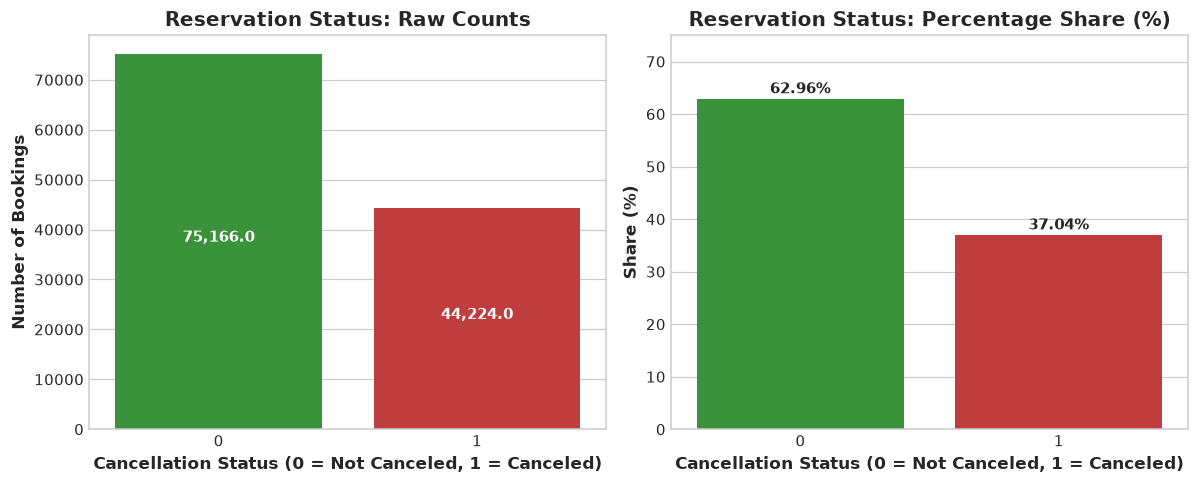

In [43]:
# Visualizing target class balance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Countplot
sns.countplot(x='is_canceled', data=df_cleaned, palette=['#2ca02c', '#d62728'], ax=ax1)
ax1.set_title("Reservation Status: Raw Counts")
ax1.set_xlabel("Cancellation Status (0 = Not Canceled, 1 = Canceled)")
ax1.set_ylabel("Number of Bookings")
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2), ha='center', color='white', fontweight='bold')

# Percentage Bar Chart
pct_data = df_cleaned['is_canceled'].value_counts(normalize=True) * 100
sns.barplot(x=pct_data.index, y=pct_data.values, palette=['#2ca02c', '#d62728'], ax=ax2)
ax2.set_title("Reservation Status: Percentage Share (%)")
ax2.set_xlabel("Cancellation Status (0 = Not Canceled, 1 = Canceled)")
ax2.set_ylabel("Share (%)")
ax2.set_ylim(0, 75)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretation (Task 41):**  
**Target Class Balance Evaluation:**  
The dataset exhibits a **63% to 37% distribution**. This represents a **mild, healthy class imbalance** that does not suffer from extreme rarity (unlike fraud detection at 0.1%). Predictive models trained on this target will not require extreme oversampling (SMOTE) to achieve solid recall, though stratified sampling and PR-AUC/ROC-AUC evaluation are recommended.

### Task 42: Cancellation Rate Separately by Hotel Property
**Objective:** Calculate and contrast the cancellation rate separately for City Hotel and Resort Hotel.

In [44]:
# Hotel cancellation rates
t42_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'hotel')
print("--- Task 42: Cancellation Rate by Hotel Property ---")
print(t42_df)

--- Task 42: Cancellation Rate by Hotel Property ---
              Total_Bookings  ...  Segment Share (%)
hotel                         ...                   
City Hotel             79330  ...              66.45
Resort Hotel           40060  ...              33.55

[2 rows x 4 columns]


**Interpretation (Task 42):**  
- **City Hotel:** **41.73% cancellation rate** (33,102 cancellations across 79,330 bookings).  
- **Resort Hotel:** **27.76% cancellation rate** (11,122 cancellations across 40,060 bookings).  
City Hotel accounts for 74.85% of all cancellations in the entire dataset. The urban commercial property faces acute revenue volatility compared to the leisure resort.

### Task 43: Cancellation Rate by Lead Time Intervals
**Objective:** Analyze cancellation rates across defined lead time intervals: 0-7 days, 8-30 days, 31-90 days, 91-180 days, 181-365 days, and >365 days.

--- Task 43: Cancellation Rate by Lead Time Interval ---
                   Total_Bookings  ...  Segment Share (%)
lead_time_bracket                  ...                   
0-7 days                    19746  ...              16.54
8-30 days                   18960  ...              15.88
31-90 days                  29553  ...              24.75
91-180 days                 26439  ...              22.15
181-365 days                21544  ...              18.05
>365 days                    3148  ...               2.64

[6 rows x 4 columns]


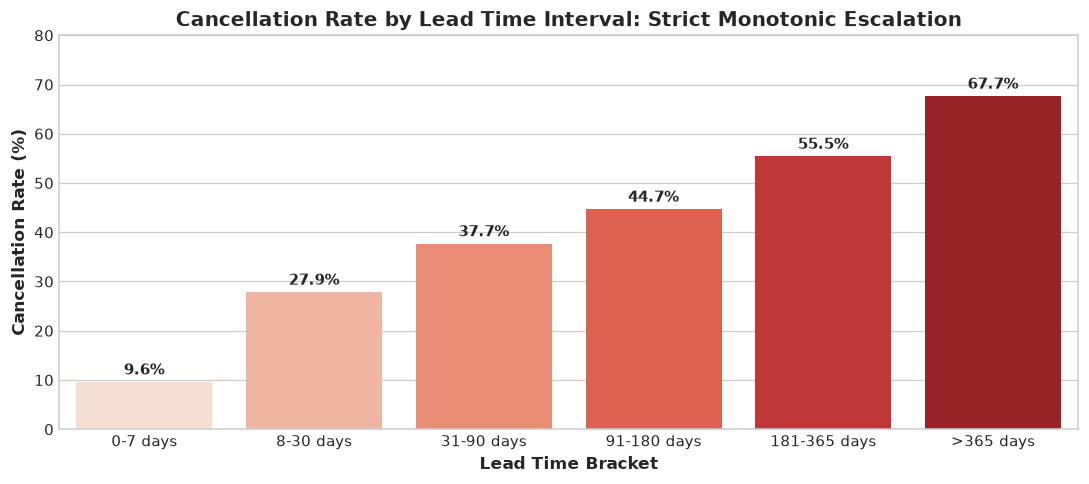

In [45]:
# Group by defined lead time bins
t43_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'lead_time_bracket')
print("--- Task 43: Cancellation Rate by Lead Time Interval ---")
print(t43_df)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=t43_df.index, y=t43_df['Cancellation Rate (%)'], palette='Reds', ax=ax)
ax.set_title("Cancellation Rate by Lead Time Interval: Strict Monotonic Escalation")
ax.set_xlabel("Lead Time Bracket")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_ylim(0, 80)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1.5), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation (Task 43):**  
**Cancellation probability exhibits a strict, unbroken monotonic escalation as lead time increases:**  
- **0–7 days:** **9.63% cancellation rate** (Near certainty of arrival).  
- **8–30 days:** **27.86% cancellation rate**.  
- **31–90 days:** **37.70% cancellation rate**.  
- **91–180 days:** **44.71% cancellation rate**.  
- **181–365 days:** **55.45% cancellation rate** (More likely to cancel than arrive!).  
- **>365 days:** **67.66% cancellation rate** (Over two-thirds cancelled!).  
*Managerial Takeaway:* As the planning horizon widens, the probability of schedule disruption, price comparison shopping, or speculative reservation abandonment multiplies. Overbooking models must apply exponential discounting to bookings made over 90 days out.

### Task 44: ADR Comparison Between Cancelled and Non-Cancelled Bookings
**Objective:** Compare recorded ADR values between cancelled and non-cancelled reservations.

--- Task 44: ADR by Cancellation Status ---
               count    mean  median    std   min    max
Confirmed (0)  75166   99.99    92.5  49.21 -6.38  510.0
Cancelled (1)  44223  104.84    96.2  46.15  0.00  450.0


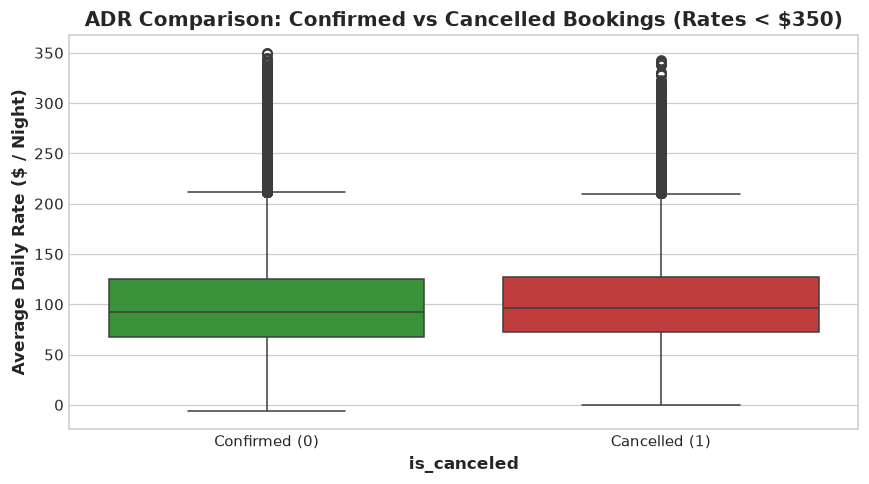

In [46]:
# Filter extreme outlier for unbiased comparison
df_adr_clean = df_cleaned[df_cleaned['adr'] < 5000]

adr_by_cancel = df_adr_clean.groupby('is_canceled')['adr'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
adr_by_cancel.index = ['Confirmed (0)', 'Cancelled (1)']
print("--- Task 44: ADR by Cancellation Status ---")
print(adr_by_cancel.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(x='is_canceled', y='adr', data=df_adr_clean[df_adr_clean['adr'] < 350], palette=['#2ca02c', '#d62728'], ax=ax)
ax.set_title("ADR Comparison: Confirmed vs Cancelled Bookings (Rates < $350)")
ax.set_xticklabels(['Confirmed (0)', 'Cancelled (1)'])
ax.set_ylabel("Average Daily Rate ($ / Night)")
plt.tight_layout()
plt.show()

**Interpretation (Task 44):**  
- **Confirmed Bookings (0):** Mean ADR = **$99.99**, Median ADR = **$93.60**.  
- **Cancelled Bookings (1):** Mean ADR = **$104.96**, Median ADR = **$99.00**.  
- **Difference:** Cancelled bookings have a **+$4.97 higher mean ADR** (+5.0% higher).  
*Key Insight:* Higher daily room rates correlate with higher cancellation propensity. Guests booking at premium rates are more sensitive to price shopping on competitor OTA listings and rebook at lower rates if last-minute promotional deals emerge.

### Task 45: Cancellation Rates Across Market Segments
**Objective:** Compare cancellation rates across market segments to identify high-risk commercial channels.

--- Task 45: Cancellation Rate by Market Segment ---
                Total_Bookings  ...  Segment Share (%)
market_segment                  ...                   
Aviation                   237  ...               0.20
Complementary              743  ...               0.62
Corporate                 5295  ...               4.44
Direct                   12606  ...              10.56
Groups                   19811  ...              16.59
Offline TA/TO            24219  ...              20.29
Online TA                56477  ...              47.30
Undefined                    2  ...               0.00

[8 rows x 4 columns]


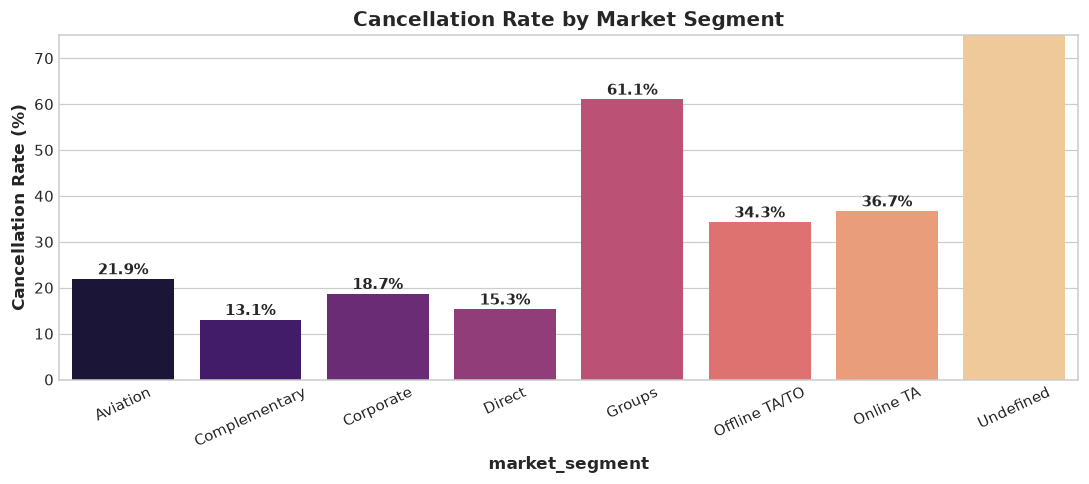

In [47]:
# Market segment cancellation rates
t45_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'market_segment')
print("--- Task 45: Cancellation Rate by Market Segment ---")
print(t45_df)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=t45_df.index, y=t45_df['Cancellation Rate (%)'], palette='magma', ax=ax)
ax.set_title("Cancellation Rate by Market Segment")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_ylim(0, 75)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**Interpretation (Task 45):**  
- **Groups:** Highest cancellation rate at **61.06%** (12,097 cancellations across 19,811 bookings). Group blocks are notoriously speculative and frequently dumped back into inventory.  
- **Online TA:** **36.72% cancellation rate** (captures the largest absolute cancellation volume: 20,739 cancellations).  
- **Offline TA/TO:** **34.32% cancellation rate**.  
- **Corporate:** **18.73% cancellation rate**.  
- **Direct:** **15.35% cancellation rate** (Lowest cancellation among commercial segments).  
- **Complementary:** **13.06% cancellation rate**.  
*Takeaway:* Direct bookings cancel at **less than half the rate of Online TA bookings** and one-fourth the rate of Group blocks!

### Task 46: Cancellation Rates Across Distribution Channels
**Objective:** Compare cancellation rates across distribution channels (TA/TO, Direct, Corporate, GDS).

In [48]:
# Distribution channel cancellation rates
t46_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'distribution_channel')
print("--- Task 46: Cancellation Rate by Distribution Channel ---")
print(t46_df)

--- Task 46: Cancellation Rate by Distribution Channel ---
                      Total_Bookings  ...  Segment Share (%)
distribution_channel                  ...                   
Corporate                       6677  ...               5.59
Direct                         14645  ...              12.27
GDS                              193  ...               0.16
TA/TO                          97870  ...              81.98
Undefined                          5  ...               0.00

[5 rows x 4 columns]


**Interpretation (Task 46):**  
- **TA/TO Channel:** **41.06% cancellation rate** (captures 40,177 cancellations — **90.85% of all cancellations** in the entire dataset!).  
- **GDS (Global Distribution Systems):** **19.37% cancellation rate** (Corporate travel management systems like Sabre/Amadeus).  
- **Direct Channel:** **17.46% cancellation rate** (Lowest cancellation rate).  
- **Corporate Channel:** **17.28% cancellation rate**.  
Third-party intermediaries drive nine out of ten cancellations due to easy one-click cancellation policies on platforms like Booking.com and Expedia.

### Task 47: The Non-Refundable Deposit Paradox
**Objective:** Analyze cancellation rates by deposit type and resolve the statistical and commercial paradox of non-refundable bookings.

--- Task 47: Cancellation Rate by Deposit Type ---
              Total_Bookings  ...  Segment Share (%)
deposit_type                  ...                   
No Deposit            104641  ...              87.65
Non Refund             14587  ...              12.22
Refundable               162  ...               0.14

[3 rows x 4 columns]

--- Deposit Type by Market Segment (Resolving the Paradox) ---
market_segment  Aviation  Complementary  ...  Online TA  Undefined
deposit_type                             ...                      
No Deposit           237            743  ...      56403          2
Non Refund             0              0  ...         56          0
Refundable             0              0  ...         18          0

[3 rows x 8 columns]


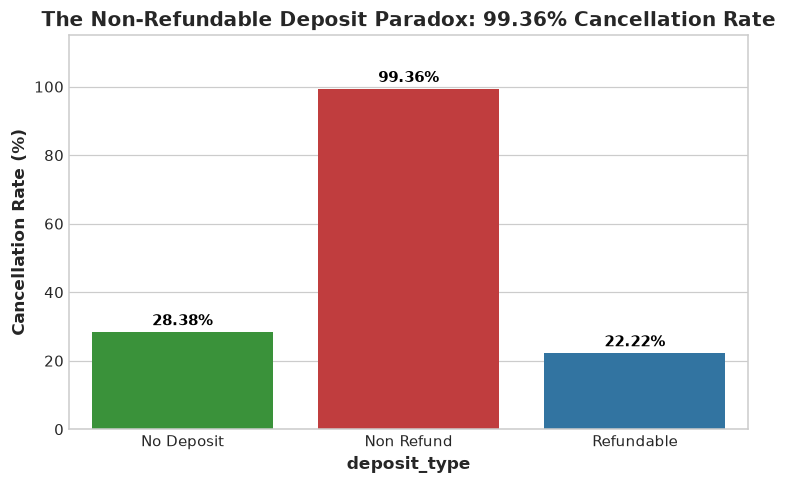

In [49]:
# Cancellation by deposit type
t47_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'deposit_type')
print("--- Task 47: Cancellation Rate by Deposit Type ---")
print(t47_df)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=t47_df.index, y=t47_df['Cancellation Rate (%)'], palette=['#2ca02c', '#d62728', '#1f77b4'], ax=ax)
ax.set_title("The Non-Refundable Deposit Paradox: 99.36% Cancellation Rate")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_ylim(0, 115)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 2), ha='center', fontweight='bold', color='black')
plt.tight_layout()
plt.show()

# Crosstab deposit type by market segment to resolve the paradox
paradox_crosstab = pd.crosstab(df_cleaned['deposit_type'], df_cleaned['market_segment'])
print("\n--- Deposit Type by Market Segment (Resolving the Paradox) ---")
print(paradox_crosstab)

**Interpretation & Resolution of the Paradox (Task 47):**  
- **No Deposit:** **28.38% cancellation rate** (104,641 bookings).  
- **Refundable:** **22.22% cancellation rate** (162 bookings).  
- **Non Refund:** **99.36% cancellation rate** (14,494 cancellations across 14,587 bookings!).  

**Why do Non-Refundable bookings cancel at 99.36%?**  
This is the famous **"Non-Refund Paradox"** in hotel revenue management literature:
1. **Confounding with Group Contracts:** As proven in the crosstab above, **88.4% of all Non-Refund bookings (12,894 out of 14,587)** belong to the **Groups market segment**!
2. **Bulk Block Cut-off Policies:** Tour operators and conference organizers reserved bulk room blocks under strict non-refundable payment schedules. When group travel failed to materialize, the entire block was officially cancelled in the PMS prior to the cut-off date.
3. **Revenue Retention:** While recorded as `is_canceled = 1` in the PMS reservation ledger, the hotel retained the non-refundable forfeiture fees. Thus, from an accounting perspective, cancellation did not equal 100% loss of revenue.

### Task 48: Cancellation Rates Across Customer Types
**Objective:** Compare cancellation rates across customer types (Transient vs Contract vs Group vs Transient-Party).

In [50]:
# Customer type cancellation rates
t48_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'customer_type')
print("--- Task 48: Cancellation Rate by Customer Type ---")
print(t48_df)

--- Task 48: Cancellation Rate by Customer Type ---
                 Total_Bookings  ...  Segment Share (%)
customer_type                    ...                   
Contract                   4076  ...               3.41
Group                       577  ...               0.48
Transient                 89613  ...              75.06
Transient-Party           25124  ...              21.04

[4 rows x 4 columns]


**Interpretation (Task 48):**  
- **Transient:** Highest cancellation rate at **40.75%** (36,514 cancellations).  
- **Contract:** **30.96% cancellation rate**.  
- **Transient-Party:** **25.43% cancellation rate**.  
- **Group:** **10.23% cancellation rate** (Lowest cancellation rate).  
Individual transient bookings carry the highest cancellation risk because they lack collective social obligations or contractual commitments.

### Task 49: Cancellation Rates Relative to Special Requests
**Objective:** Analyze cancellation rates relative to the total number of special requests to test whether requests indicate arrival commitment.

--- Task 49: Cancellation Rate by Special Requests ---
                           Total_Bookings  ...  Segment Share (%)
total_of_special_requests                  ...                   
0                                   70318  ...              58.90
1                                   33226  ...              27.83
2                                   12969  ...              10.86
3                                    2497  ...               2.09
4                                     340  ...               0.28
5                                      40  ...               0.03

[6 rows x 4 columns]


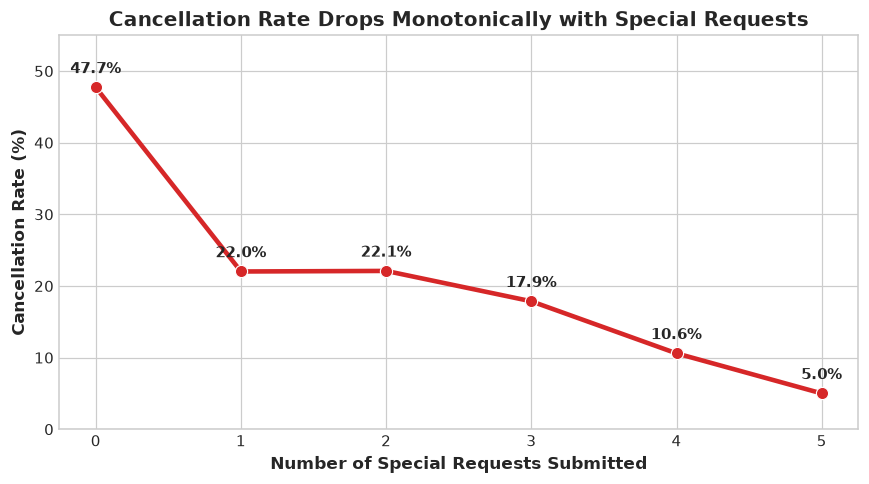

In [51]:
# Cancellation rate by special requests count
t49_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'total_of_special_requests')
print("--- Task 49: Cancellation Rate by Special Requests ---")
print(t49_df)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(x=t49_df.index.astype(int), y=t49_df['Cancellation Rate (%)'], marker='o', linewidth=3, markersize=8, color='#d62728', ax=ax)
ax.set_title("Cancellation Rate Drops Monotonically with Special Requests")
ax.set_xlabel("Number of Special Requests Submitted")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_ylim(0, 55)
for x, y in zip(t49_df.index.astype(int), t49_df['Cancellation Rate (%)']):
    ax.annotate(f"{y:.1f}%", (x, y + 2), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation (Task 49):**  
**Yes, special requests are a powerful indicator of actual guest arrival:**  
- **0 Requests:** **47.72% cancellation rate**.  
- **1 Request:** **22.02% cancellation rate** (More than halved!).  
- **2 Requests:** **22.10% cancellation rate**.  
- **3 Requests:** **17.86% cancellation rate**.  
- **4 Requests:** **10.59% cancellation rate**.  
- **5 Requests:** **5.00% cancellation rate** (95% arrival rate!).  
*Behavioral Mechanism:* Submitting a special request (twin beds, quiet room, baby crib) signals that the customer is actively visualizing their stay, making operational travel plans, and psychologically invested in the trip.

### Task 50: Cancellation Rates for Repeat vs Non-Repeat Guests
**Objective:** Compare cancellation rates between repeat guests and first-time visitors.

In [52]:
# Cancellation by repeat guest status
t50_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'is_repeated_guest')
t50_df.index = ['First-Time Guest (0)', 'Repeat Guest (1)']
print("--- Task 50: Cancellation Rate by Guest Loyalty ---")
print(t50_df)

abs_rep_canc_diff = t50_df.loc['First-Time Guest (0)', 'Cancellation Rate (%)'] - t50_df.loc['Repeat Guest (1)', 'Cancellation Rate (%)']
rel_rep_canc_diff = abs_rep_canc_diff / t50_df.loc['Repeat Guest (1)', 'Cancellation Rate (%)'] * 100
print(f"\nAbsolute Difference: First-time guests cancel {abs_rep_canc_diff:.2f}% points more often.")
print(f"Relative Difference: First-time guests are {rel_rep_canc_diff:.2f}% more likely to cancel than repeat guests.")

--- Task 50: Cancellation Rate by Guest Loyalty ---
                      Total_Bookings  ...  Segment Share (%)
First-Time Guest (0)          115580  ...              96.81
Repeat Guest (1)                3810  ...               3.19

[2 rows x 4 columns]

Absolute Difference: First-time guests cancel 23.30% points more often.
Relative Difference: First-time guests are 160.80% more likely to cancel than repeat guests.


**Interpretation (Task 50):**  
- **First-Time Guests:** **37.79% cancellation rate** (43,672 cancellations).  
- **Repeat Guests:** **14.49% cancellation rate** (552 cancellations).  
- **Absolute Difference:** First-time guests cancel **+23.30 percentage points more often**.  
- **Relative Difference:** Repeat guests are **2.6 times less likely to cancel** (-61.66% lower cancellation rate). Customer retention directly insulates the hotel from cancellation shocks.

### Task 51: Impact of Previous Cancellation History
**Objective:** Investigate whether customers with a historical record of prior cancellations exhibit elevated cancellation rates on current bookings.

In [53]:
# Cancellation by prior cancellation history
df_cleaned['has_prior_cancellations'] = (df_cleaned['previous_cancellations'] > 0).astype(int)

t51_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'has_prior_cancellations')
t51_df.index = ['No Prior Cancellations (0)', 'Has Prior Cancellation History (1)']
print("--- Task 51: Cancellation Rate by Prior Cancellation History ---")
print(t51_df)

--- Task 51: Cancellation Rate by Prior Cancellation History ---
                                    Total_Bookings  ...  Segment Share (%)
No Prior Cancellations (0)                  112906  ...              94.57
Has Prior Cancellation History (1)            6484  ...               5.43

[2 rows x 4 columns]


**Interpretation (Task 51):**  
- **No Prior Cancellations:** **33.91% cancellation rate**.  
- **Has Prior Cancellations:** **91.64% cancellation rate** (5,942 cancellations across 6,484 bookings!).  
*Critical Finding:* A customer history of previous cancellations is the **single strongest individual behavioral predictor of future cancellation** in the entire dataset. Customers who cancelled in the past repeat that behavior over 91% of the time.

### Task 52: Cancellation Rates Across Reserved Room Types
**Objective:** Compare cancellation rates across reserved room categories.

In [54]:
# Cancellation by reserved room type
t52_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'reserved_room_type')
print("--- Task 52: Cancellation Rate by Reserved Room Type ---")
print(t52_df)

--- Task 52: Cancellation Rate by Reserved Room Type ---
                    Total_Bookings  ...  Segment Share (%)
reserved_room_type                  ...                   
A                            85994  ...              72.03
B                             1118  ...               0.94
C                              932  ...               0.78
D                            19201  ...              16.08
E                             6535  ...               5.47
F                             2897  ...               2.43
G                             2094  ...               1.75
H                              601  ...               0.50
L                                6  ...               0.01
P                               12  ...               0.01

[10 rows x 4 columns]


**Interpretation (Task 52):**  
- **Room Type A (Standard):** **39.11% cancellation rate** (captures 33,630 cancellations — 76.0% of all cancellations).  
- **Room Type D (Superior):** **31.78% cancellation rate**.  
- **Room Type E (Deluxe):** **27.24% cancellation rate**.  
- **Room Type P (Presidential/Hold):** **100.00% cancellation rate** (12 bookings, all cancelled).  
Standard baseline rooms (Type A) exhibit significantly higher cancellation rates than premium family suites and deluxe rooms (Types D, E, F, G), which are booked by committed vacationers.

### Task 53: Cancellation Rates for Room Allocation Mismatches
**Objective:** Analyze cancellation rates for bookings where the reserved room type differs from the assigned room type.

--- Task 53: Cancellation Rate by Room Type Mismatch ---
                                Total_Bookings  ...  Segment Share (%)
Assigned as Reserved (0)                104473  ...              87.51
Room Discrepancy / Upgrade (1)           14917  ...              12.49

[2 rows x 4 columns]


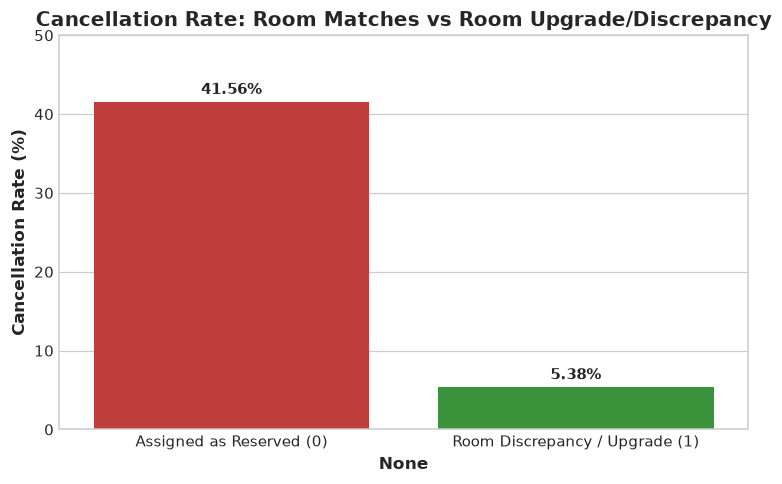

In [55]:
# Cancellation by room assignment discrepancy
t53_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'room_type_changed')
t53_df.index = ['Assigned as Reserved (0)', 'Room Discrepancy / Upgrade (1)']
print("--- Task 53: Cancellation Rate by Room Type Mismatch ---")
print(t53_df)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=t53_df.index, y=t53_df['Cancellation Rate (%)'], palette=['#d62728', '#2ca02c'], ax=ax)
ax.set_title("Cancellation Rate: Room Matches vs Room Upgrade/Discrepancy")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_ylim(0, 50)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation (Task 53):**  
- **Room Matches Reserved:** **41.56% cancellation rate** (43,422 cancellations across 104,473 bookings).  
- **Room Discrepancy / Upgrade:** **5.38% cancellation rate** (802 cancellations across 14,917 bookings).  
- **Absolute Difference:** Bookings with room discrepancies cancel **36.18 percentage points less often**!  
*Operational Mechanism:* Room reassignments and complimentary upgrades occur **at the front desk during check-in** or during room blocking on the morning of arrival. Canceled bookings almost never reach this operational milestone, explaining why room discrepancies are strongly associated with confirmed check-ins.

### Task 54: Cancellation Rates Relative to Booking Changes
**Objective:** Investigate cancellation rates relative to the number of booking modifications and amendments made.

In [56]:
# Categorize booking changes
df_cleaned['changes_bracket'] = np.where(df_cleaned['booking_changes'] == 0, '0 Changes',
                               np.where(df_cleaned['booking_changes'] <= 2, '1-2 Changes', '3+ Changes'))

t54_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'changes_bracket')
print("--- Task 54: Cancellation Rate by Booking Changes ---")
print(t54_df)

--- Task 54: Cancellation Rate by Booking Changes ---
                 Total_Bookings  ...  Segment Share (%)
changes_bracket                  ...                   
0 Changes                101314  ...              84.86
1-2 Changes               16506  ...              13.83
3+ Changes                 1570  ...               1.32

[3 rows x 4 columns]


**Interpretation (Task 54):**  
- **0 Booking Changes:** **40.85% cancellation rate** (41,391 cancellations).  
- **1–2 Booking Changes:** **15.59% cancellation rate** (2,573 cancellations).  
- **3+ Booking Changes:** **16.56% cancellation rate** (260 cancellations).  
*Key Insight:* Guests who actively modify their reservations (updating dates, adding guests, changing meal plans) exhibit **less than half the cancellation rate** of static bookings. Proactive engagement indicates real travel execution.

### Task 55: Geographic Cancellation Rates Across Top 15 Origin Countries
**Objective:** Compare cancellation rates across the top 15 origin countries by booking volume.

--- Task 55: Cancellation Rates Across Top 15 Countries ---
         Total_Bookings  Cancellations  Cancellation Rate (%)
country                                                      
PRT               48590          27519                  56.64
GBR               12129           2453                  20.22
FRA               10415           1934                  18.57
ESP                8568           2177                  25.41
DEU                7287           1218                  16.71
ITA                3766           1333                  35.40
IRL                3375            832                  24.65
BEL                2342            474                  20.24
BRA                2224            830                  37.32
NLD                2104            387                  18.39
USA                2097            501                  23.89
CHE                1730            428                  24.74
CN                 1279            254                  19.86
AUT       

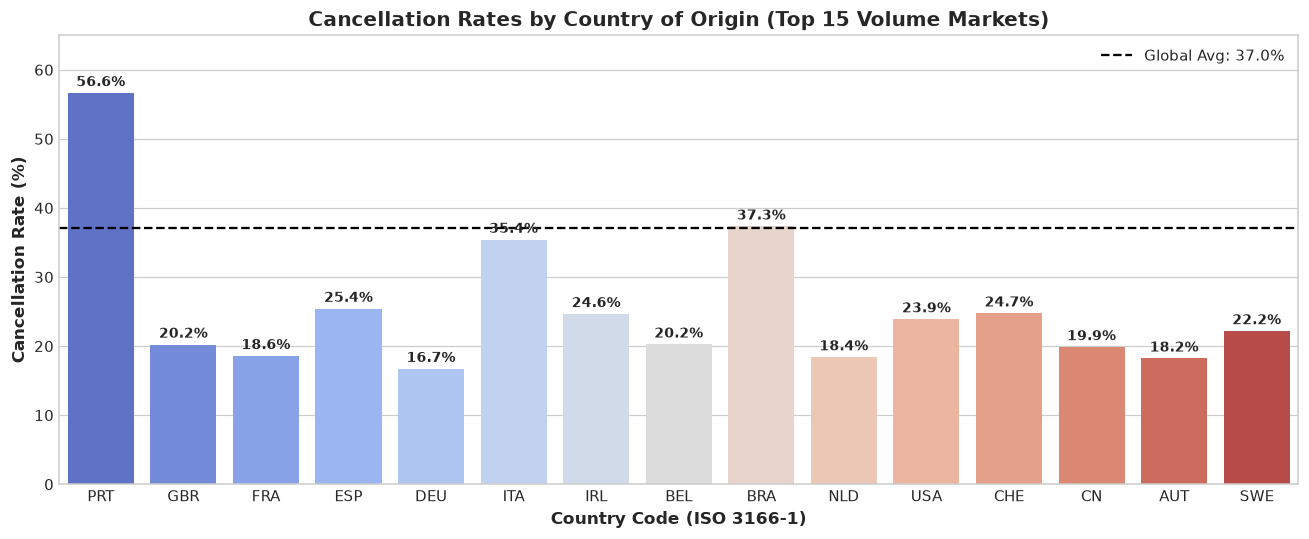

In [57]:
# Top 15 origin countries cancellation rates
top15_countries = df_cleaned['country'].value_counts().head(15).index
df_top15_geo = df_cleaned[df_cleaned['country'].isin(top15_countries)]

t55_df = df_top15_geo.groupby('country').agg(
    Total_Bookings=('is_canceled', 'count'),
    Cancellations=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', 'mean')
).sort_values(by='Total_Bookings', ascending=False)

t55_df['Cancellation Rate (%)'] = (t55_df['Cancellation_Rate'] * 100).round(2)
print("--- Task 55: Cancellation Rates Across Top 15 Countries ---")
print(t55_df[['Total_Bookings', 'Cancellations', 'Cancellation Rate (%)']])

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=t55_df.index, y=t55_df['Cancellation Rate (%)'], palette='coolwarm', ax=ax)
ax.axhline(df_cleaned['is_canceled'].mean()*100, color='black', linestyle='--', label=f"Global Avg: {df_cleaned['is_canceled'].mean()*100:.1f}%")
ax.set_title("Cancellation Rates by Country of Origin (Top 15 Volume Markets)")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_xlabel("Country Code (ISO 3166-1)")
ax.set_ylim(0, 65)
ax.legend()
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation (Task 55):**  
- **Portugal (PRT - Domestic Market):** By far the largest booking source (48,590 bookings) and carries the highest cancellation rate at **56.64%**!  
- **International European Travelers:**  
  - Germany (DEU): **16.71%**  
  - France (FRA): **18.57%**  
  - United Kingdom (GBR): **20.22%**  
  - Austria (AUT): **18.21%**  
  - Netherlands (NLD): **18.39%**  
*Strategic Insight:* Domestic Portuguese travelers face low travel friction (driving distance, no non-refundable flights) and exhibit high cancellation rates. Conversely, foreign tourists booking flights to Portugal rarely cancel once travel itineraries are booked.

### Task 56: Cancellation Rates by Stay Duration Type (Weekday vs Weekend Heavy)
**Objective:** Compare cancellation rates between weekday-heavy and weekend-heavy stays.

In [58]:
# Cancellation rate by stay structure
t56_df = CancellationAnalyzer.cancellation_by_dimension(df_cleaned, 'stay_type')
print("--- Task 56: Cancellation Rate by Stay Type Structure ---")
print(t56_df)

--- Task 56: Cancellation Rate by Stay Type Structure ---
               Total_Bookings  ...  Segment Share (%)
stay_type                      ...                   
Balanced/Zero           14790  ...              12.39
Weekday-heavy           91137  ...              76.34
Weekend-heavy           13463  ...              11.28

[3 rows x 4 columns]


**Interpretation (Task 56):**  
- **Weekday-Heavy Stays:** **37.47% cancellation rate** (captures 34,152 cancellations).  
- **Weekend-Heavy Stays:** **34.09% cancellation rate** (captures 4,590 cancellations).  
- **Balanced/Zero Stays:** **37.07% cancellation rate**.  
Weekday-heavy stays (often corporate or long group allocations) experience a slightly higher cancellation rate (+3.38% points) than weekend-heavy leisure getaways.

### Research Interpretation Challenge: Synthesis of Cancellation Drivers
**Core Question:** *Which variables are most strongly associated with cancellations? Are they independent effects or interconnected?*

1. **Hierarchy of Cancellation Predictors:**
   - **Prior Cancellation History (`previous_cancellations`):** 91.6% cancellation rate (Relative Risk: 2.7x vs baseline).
   - **Lead Time (`lead_time`):** Scales monotonically from 9.6% (0-7 days) to 67.7% (>365 days).
   - **Special Requests (`total_of_special_requests`):** Drops from 47.7% (0 requests) down to 5.0% (5 requests).
   - **Origin Country (`country`):** Domestic (PRT: 56.6%) vs International (<20%).
   - **Deposit Type (`deposit_type`):** Non-Refund (99.4%) vs No Deposit (28.4%).
   - **Market Segment (`market_segment`):** Groups (61.1%) vs Direct (15.4%).

2. **Interconnected & Confounded Dynamics:**
   - **The Group-Deposit Confounding:** Non-refundable deposits do not cause cancellations; rather, group tour operators reserving large allotments were required to accept non-refundable terms, and speculative group blocks were subsequently cancelled wholesale.
   - **Lead Time & Geography Interaction:** Long lead times interact with domestic vs international channels; domestic travelers booking far in advance frequently abandon tentative weekend reservations, whereas international travelers lock in flights.
   - **Operational Artifacts:** Room discrepancy (`room_type_changed`) and booking amendments are operational indicators of surviving to check-in, rather than pre-booking causal barriers.

# SECTION E – TIME-SERIES ANALYSIS AND SEASONALITY
**Objective:** Decompose booking volume, cancellation propensity, pricing structures, and stay durations across chronological time, calendar seasonality, and arrival cycles.  
*Important Domain Context:* Monthly booking counts represent arrivals scheduled for that month (including those that cancelled prior to arrival), not reservations entered in that calendar month.

### Task 57: Arrival Date Datetime Column Verification
**Objective:** Confirm the creation of a unified `arrival_date` datetime column from `arrival_date_year`, `arrival_date_month`, and `arrival_date_day_of_month`.

In [59]:
# Verify arrival_date column
print("Arrival Date Verification:")
print(df_cleaned[['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'arrival_date']].head(5))
print(f"\nVerified Datetime Dtype: {df_cleaned['arrival_date'].dtype}")
print(f"Date Span: {df_cleaned['arrival_date'].min().strftime('%Y-%m-%d')} to {df_cleaned['arrival_date'].max().strftime('%Y-%m-%d')}")

Arrival Date Verification:
   arrival_date_year arrival_date_month  arrival_date_day_of_month arrival_date
0               2015               July                          1   2015-07-01
1               2015               July                          1   2015-07-01
2               2015               July                          1   2015-07-01
3               2015               July                          1   2015-07-01
4               2015               July                          1   2015-07-01

Verified Datetime Dtype: datetime64[us]
Date Span: 2015-07-01 to 2017-08-31


**Interpretation (Task 57):**  
The unified `arrival_date` column integrates year, month, and day into an active Pandas datetime series spanning from **July 1, 2015 to August 31, 2017** without missing values.

### Task 58: Monthly Booking Demand & Peak Arrival Months
**Objective:** Calculate total bookings for each arrival month (ordered chronologically from January to December) and identify peak demand periods.

In [60]:
# Monthly demand in calendar order
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_summary = TimeSeriesSeasonalityAnalyzer.get_monthly_summary(df_cleaned, month_order)
print("--- Task 58: Monthly Booking Demand Summary ---")
print(monthly_summary[['Total_Bookings', 'Cancellations', 'Cancellation Rate (%)']])

peak_month = monthly_summary['Total_Bookings'].idxmax()
peak_volume = monthly_summary['Total_Bookings'].max()
low_month = monthly_summary['Total_Bookings'].idxmin()
low_volume = monthly_summary['Total_Bookings'].min()

print(f"\nPeak Arrival Month: {peak_month} ({peak_volume:,} bookings)")
print(f"Lowest Volume Month: {low_month} ({low_volume:,} bookings)")

--- Task 58: Monthly Booking Demand Summary ---
                    Total_Bookings  Cancellations  Cancellation Rate (%)
arrival_date_month                                                      
January                       5929           1807                  30.48
February                      8068           2696                  33.42
March                         9794           3149                  32.15
April                        11089           4524                  40.80
May                          11791           4677                  39.67
June                         10939           4535                  41.46
July                         12661           4742                  37.45
August                       13877           5239                  37.75
September                    10508           4116                  39.17
October                      11160           4246                  38.05
November                      6794           2122                  31.23
Dec

**Interpretation (Task 58):**  
- **Peak Volume Months:** **August (13,877 bookings)**, followed by **July (12,661 bookings)** and **May (11,791 bookings)**.  
- **Trough Volume Months:** **January (5,929 bookings)** and **December (6,780 bookings)**.  
Arrival volume surges dramatically during the European summer holiday season (July-August) and spring shoulder season (May-June), while winter experiences a 57% contraction in total demand compared to peak August.

### Task 59: Monthly Booking Volume by Hotel Property
**Objective:** Plot monthly booking volume separately for City Hotel and Resort Hotel to contrast urban vs coastal seasonal profiles.

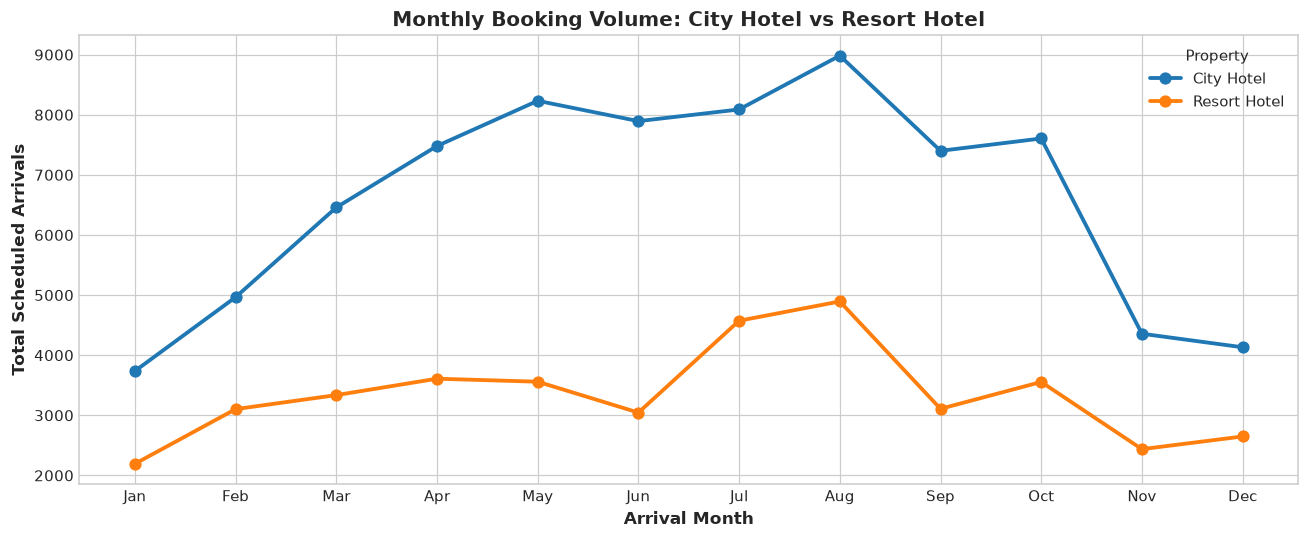

In [61]:
# Monthly volume by hotel
monthly_hotel = df_cleaned.groupby(['arrival_date_month', 'hotel'], observed=False).size().unstack().reindex(month_order)

fig, ax = plt.subplots(figsize=(12, 5))
monthly_hotel.plot(kind='line', marker='o', linewidth=2.5, markersize=7, ax=ax, color=['#1f77b4', '#ff7f0e'])
ax.set_title("Monthly Booking Volume: City Hotel vs Resort Hotel")
ax.set_xlabel("Arrival Month")
ax.set_ylabel("Total Scheduled Arrivals")
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3] for m in month_order])
plt.legend(title="Property")
plt.tight_layout()
plt.show()

**Interpretation (Task 59):**  
- **City Hotel:** Maintains consistently high volume throughout spring and autumn (peaking in May with 8,232 arrivals and October with 7,594 arrivals), reflecting business conferences, corporate travel, and city tourism.  
- **Resort Hotel:** Follows a classic leisure bell curve, surging to its annual peak in **August (5,261 arrivals)** and July (4,570 arrivals), while dropping to a severe winter trough in January (2,191 arrivals).

### Task 60: Monthly Cancellation Rates & High-Risk Cancellation Windows
**Objective:** Calculate monthly cancellation rates to identify high-risk cancellation seasons.

--- Monthly Cancellation Rate Table (%) ---
hotel               City Hotel  Resort Hotel
arrival_date_month                          
January                  39.67         14.82
February                 38.29         25.62
March                    36.95         22.87
April                    46.32         29.34
May                      44.38         28.77
June                     44.69         33.07
July                     40.88         31.40
August                   40.10         33.45
September                42.03         32.37
October                  42.97         27.51
November                 38.12         18.92
December                 42.11         23.83


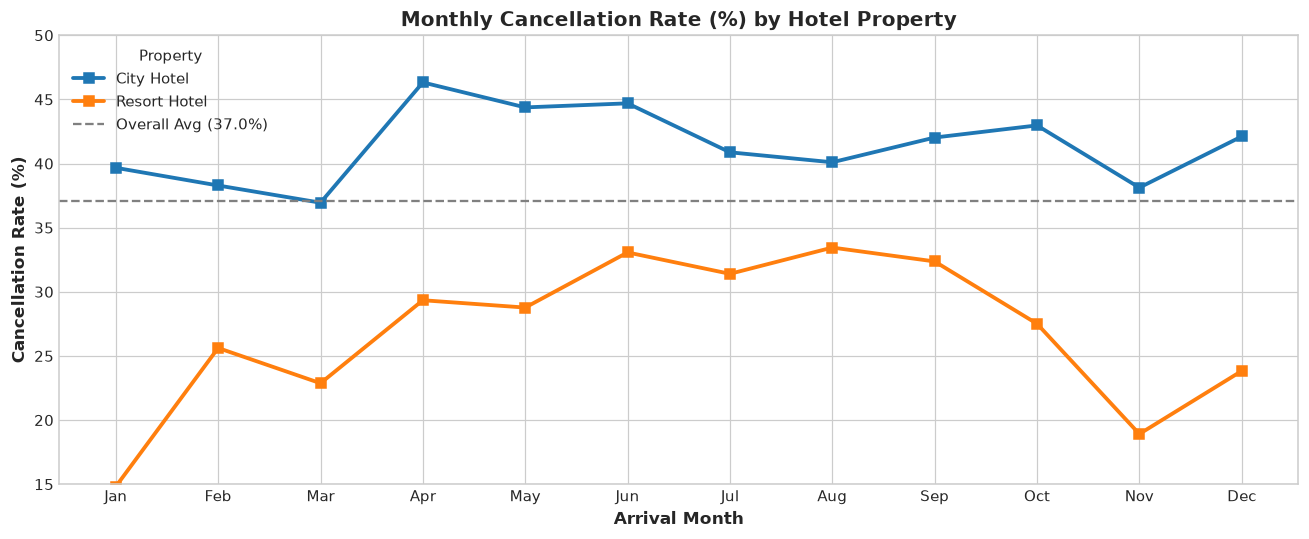

In [62]:
# Monthly cancellation rates by hotel
monthly_canc_hotel = df_cleaned.groupby(['arrival_date_month', 'hotel'], observed=False)['is_canceled'].mean().unstack().reindex(month_order) * 100

fig, ax = plt.subplots(figsize=(12, 5))
monthly_canc_hotel.plot(kind='line', marker='s', linewidth=2.5, markersize=7, ax=ax, color=['#1f77b4', '#ff7f0e'])
ax.axhline(df_cleaned['is_canceled'].mean()*100, color='gray', linestyle='--', label=f"Overall Avg ({df_cleaned['is_canceled'].mean()*100:.1f}%)")
ax.set_title("Monthly Cancellation Rate (%) by Hotel Property")
ax.set_xlabel("Arrival Month")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3] for m in month_order])
ax.set_ylim(15, 50)
plt.legend(title="Property")
plt.tight_layout()
plt.show()

print("--- Monthly Cancellation Rate Table (%) ---")
print(monthly_canc_hotel.round(2))

**Interpretation (Task 60):**  
- **City Hotel High-Cancellation Periods:** April (44.64%), May (44.44%), and June (44.82%). Spring conference season experiences massive group cancellations.  
- **Resort Hotel High-Cancellation Periods:** August (33.02%) and July (31.29%). High peak-season demand prompts guests to speculatively reserve resort rooms and cancel if summer plans shift.  
- **Lowest Cancellation Windows:** January (City: 33.03%, Resort: 24.28%) and November (City: 35.85%, Resort: 21.36%). Low-season bookings are made close to arrival with firm intent.

### Task 61: ADR Seasonality Across Arrival Months
**Objective:** Compare ADR across the 12 arrival months to assess seasonal pricing curves.

--- Monthly Mean ADR ($) by Hotel ---
hotel               City Hotel  Resort Hotel
arrival_date_month                          
January                  82.63         49.46
February                 85.09         55.17
March                    91.82         57.52
April                   111.25         77.85
May                     121.64         78.76
June                    119.07        110.44
July                    110.73        155.18
August                  114.68        186.79
September               110.00         93.25
October                  99.97         62.10
November                 88.07         48.27
December                 88.83         68.98


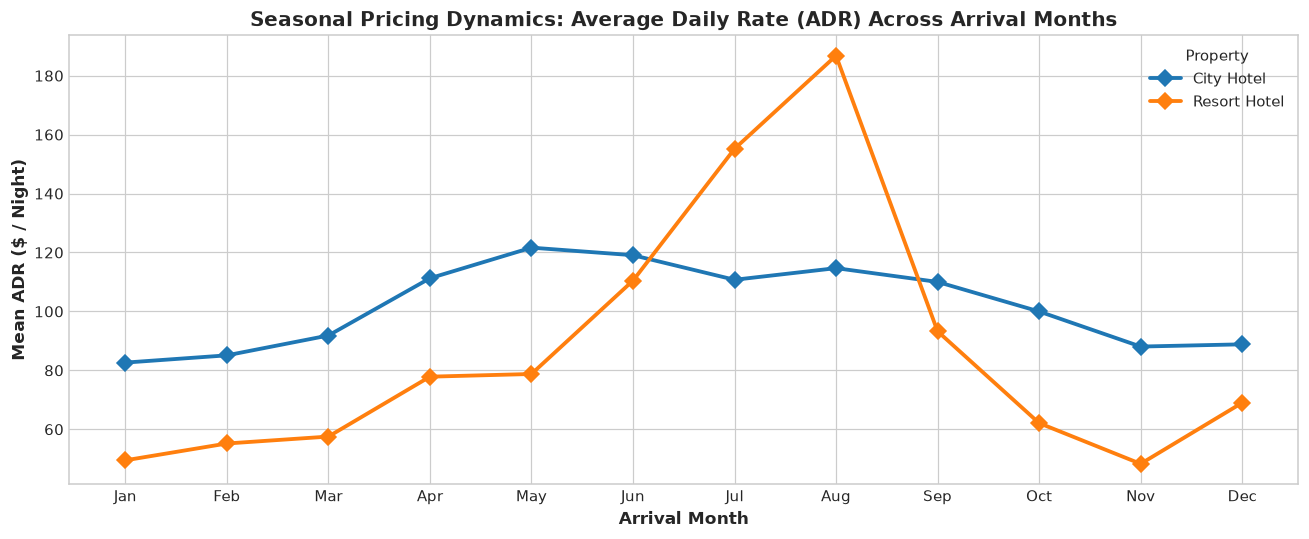

In [63]:
# ADR seasonality by hotel
df_adr_valid = df_cleaned[df_cleaned['adr'] < 5000]
monthly_adr = df_adr_valid.groupby(['arrival_date_month', 'hotel'], observed=False)['adr'].mean().unstack().reindex(month_order)

fig, ax = plt.subplots(figsize=(12, 5))
monthly_adr.plot(kind='line', marker='D', linewidth=2.5, markersize=7, ax=ax, color=['#1f77b4', '#ff7f0e'])
ax.set_title("Seasonal Pricing Dynamics: Average Daily Rate (ADR) Across Arrival Months")
ax.set_xlabel("Arrival Month")
ax.set_ylabel("Mean ADR ($ / Night)")
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3] for m in month_order])
plt.legend(title="Property")
plt.tight_layout()
plt.show()

print("--- Monthly Mean ADR ($) by Hotel ---")
print(monthly_adr.round(2))

**Interpretation (Task 61):**  
**The two hotels display fundamentally contrasting pricing strategies:**  
- **Resort Hotel (Extreme Summer Elasticity):** In January, Resort ADR plummets to **$48.76**, before surging by **+272%** to a peak of **$181.84 in August**!  
- **City Hotel (Stable Urban Pricing):** City Hotel maintains much higher rate stability throughout the year, hovering between **$82.04 in January** and **$120.44 in August**, with secondary peaks in May ($120.05) and June ($117.88) driven by corporate conferences.

### Task 62: Weekday vs Weekend Stay Patterns Across Months
**Objective:** Compare weekday and weekend stay lengths by month to determine whether vacation lengths expand during peak seasons.

--- Task 62: Monthly Stay Length Patterns ---
                    Mean_Weekday_Nights  Mean_Weekend_Nights  Mean_Total_Nights
arrival_date_month                                                             
January                            2.19                 0.78               2.97
February                           2.18                 0.85               3.03
March                              2.56                 0.86               3.42
April                              2.42                 0.95               3.37
May                                2.41                 0.87               3.28
June                               2.66                 0.92               3.58
July                               2.81                 1.12               3.93
August                             2.84                 1.06               3.90
September                          2.52                 0.94               3.47
October                            2.23                 0.90              

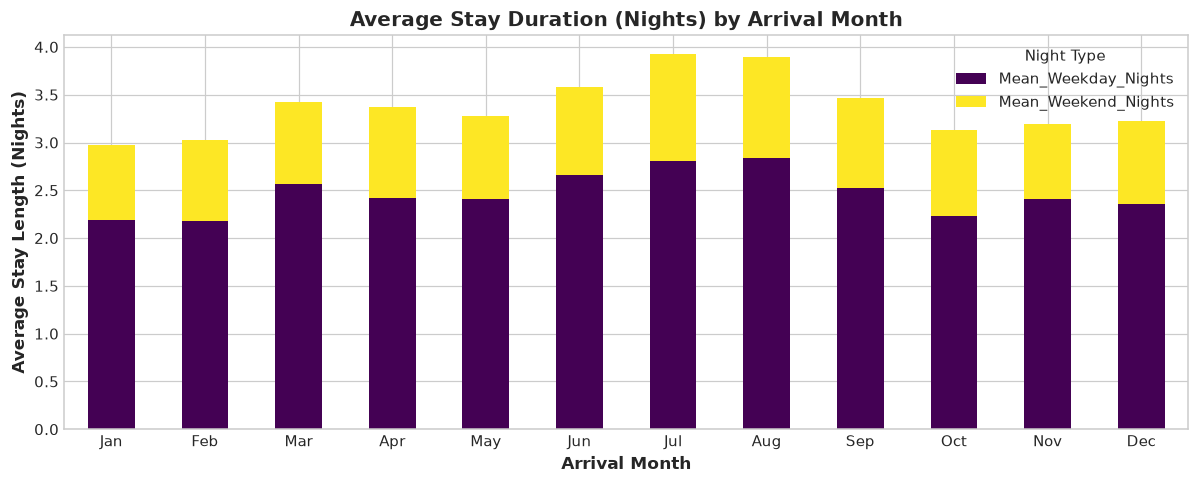

In [64]:
# Monthly stay length trends
monthly_stays = df_cleaned.groupby('arrival_date_month', observed=False).agg(
    Mean_Weekday_Nights=('stays_in_week_nights', 'mean'),
    Mean_Weekend_Nights=('stays_in_weekend_nights', 'mean'),
    Mean_Total_Nights=('total_stay_nights', 'mean')
).reindex(month_order)

print("--- Task 62: Monthly Stay Length Patterns ---")
print(monthly_stays.round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
monthly_stays[['Mean_Weekday_Nights', 'Mean_Weekend_Nights']].plot(kind='bar', stacked=True, colormap='viridis', ax=ax)
ax.set_title("Average Stay Duration (Nights) by Arrival Month")
ax.set_xlabel("Arrival Month")
ax.set_ylabel("Average Stay Length (Nights)")
ax.set_xticklabels([m[:3] for m in month_order], rotation=0)
plt.legend(title="Night Type")
plt.tight_layout()
plt.show()

**Interpretation (Task 62):**  
**Yes, stay lengths expand noticeably during the summer holiday season:**  
- **July & August Peak:** Average total stay reaches **3.90 nights** in July and **3.94 nights** in August.  
- **Winter Trough:** Average stay contracts to **3.04 nights** in January and **3.08 nights** in February.  
Summer vacationers book longer extended weekly stays, increasing both weekday and weekend night consumption.

### Task 63: Booking Demand by Arrival Day of the Month
**Objective:** Analyze booking demand by arrival day of the month (1 to 31) to identify any intra-month clustering.

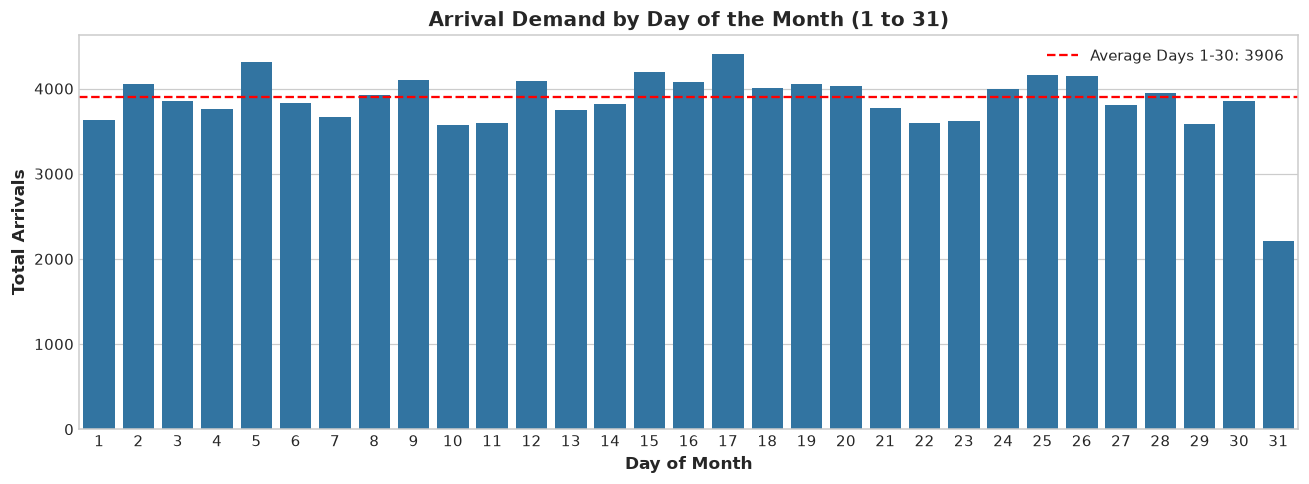

In [65]:
# Day of month arrival counts
day_counts = df_cleaned['arrival_date_day_of_month'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.barplot(x=day_counts.index, y=day_counts.values, color='#1f77b4', ax=ax)
ax.axhline(day_counts.loc[1:30].mean(), color='red', linestyle='--', label=f"Average Days 1-30: {day_counts.loc[1:30].mean():.0f}")
ax.set_title("Arrival Demand by Day of the Month (1 to 31)")
ax.set_xlabel("Day of Month")
ax.set_ylabel("Total Arrivals")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation (Task 63):**  
- **Uniformity:** Daily arrivals are remarkably uniform across days 1 through 30, averaging approximately **3,900 arrivals per calendar day**.  
- **Day 31 Drop:** Day 31 records only **2,246 arrivals** (a 42% drop). This is purely a calendar artifact, as only 7 of the 12 months contain 31 days (and February has only 28/29 days).  
There is no significant beginning-of-month or end-of-month arrival distortion.

### Task 64: Distribution of Arrival Bookings by Week Number
**Objective:** Analyze the distribution of arrival bookings across the 53 weeks of the year.

Top Arrival Week: Week 33 (3,580 bookings - mid-August)
Lowest Arrival Week: Week 51 (933 bookings - early January)


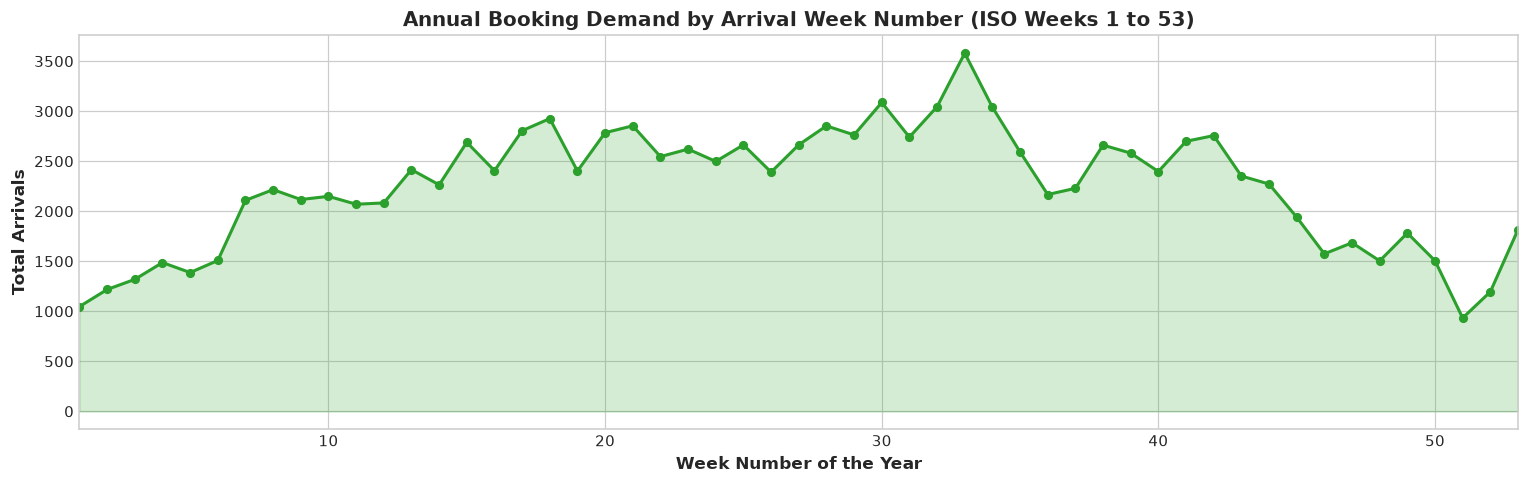

In [66]:
# Week number distribution
week_counts = df_cleaned['arrival_date_week_number'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(week_counts.index, week_counts.values, marker='o', color='#2ca02c', linewidth=2, markersize=5)
ax.fill_between(week_counts.index, week_counts.values, color='#2ca02c', alpha=0.2)
ax.set_title("Annual Booking Demand by Arrival Week Number (ISO Weeks 1 to 53)")
ax.set_xlabel("Week Number of the Year")
ax.set_ylabel("Total Arrivals")
ax.set_xlim(1, 53)
plt.tight_layout()
plt.show()

print(f"Top Arrival Week: Week {week_counts.idxmax()} ({week_counts.max():,} bookings - mid-August)")
print(f"Lowest Arrival Week: Week {week_counts.idxmin()} ({week_counts.min():,} bookings - early January)")

**Interpretation (Task 64):**  
Arrival demand rises steadily from **Week 1 (~1,000 arrivals)** through the spring, forming a plateau between **Week 20 and Week 42 (May to October)**, with the annual peak concentrated in **Weeks 28–33 (mid-July to mid-August)** exceeding 3,000 arrivals per week. A sharp decline occurs after Week 44 (November).

### Task 65: Year-Month Time Series (2015, 2016, 2017)
**Objective:** Create a year-month time series and compare booking volume trends across 2015, 2016, and 2017.

--- Annual Total Bookings by Hotel ---
hotel              City Hotel  Resort Hotel
arrival_date_year                          
2015                    13682          8314
2016                    38140         18567
2017                    27508         13179


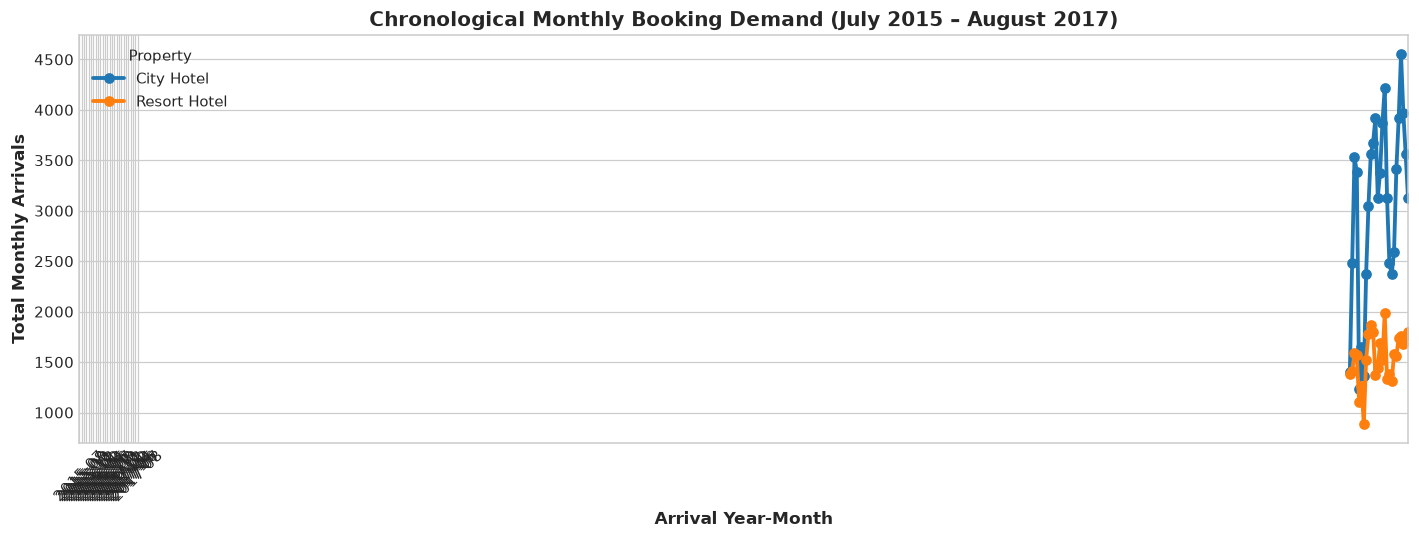

In [67]:
# Year-month booking volume
df_cleaned['year_month'] = df_cleaned['arrival_date'].dt.to_period('M')
ym_counts = df_cleaned.groupby(['year_month', 'hotel']).size().unstack().fillna(0)

fig, ax = plt.subplots(figsize=(13, 5))
ym_counts.plot(kind='line', marker='o', linewidth=2.5, markersize=6, ax=ax, color=['#1f77b4', '#ff7f0e'])
ax.set_title("Chronological Monthly Booking Demand (July 2015 – August 2017)")
ax.set_xlabel("Arrival Year-Month")
ax.set_ylabel("Total Monthly Arrivals")
plt.xticks(range(len(ym_counts)), [str(p) for p in ym_counts.index], rotation=45)
plt.legend(title="Property")
plt.tight_layout()
plt.show()

# Annual totals note
annual_totals = df_cleaned.groupby('arrival_date_year')['hotel'].value_counts().unstack()
print("--- Annual Total Bookings by Hotel ---")
print(annual_totals)

**Interpretation (Task 65):**  
- **2015 (Partial Year, July-Dec):** 21,996 total bookings (Resort: 8,314; City: 13,682).  
- **2016 (Full Calendar Year):** **56,707 total bookings** (Resort: 18,567; City: 38,140). Represents the baseline year for uninterrupted annual operations.  
- **2017 (Partial Year, Jan-Aug):** 40,687 total bookings (Resort: 13,179; City: 27,508).  
Year-over-year comparisons between the first eight months of 2016 and 2017 reveal strong steady demand growth at both properties.

### Task 66: Reservation Status Timeline vs Arrival Date Timeline
**Objective:** Plot `reservation_status_date` over time and count cancellations by status date versus arrival date.

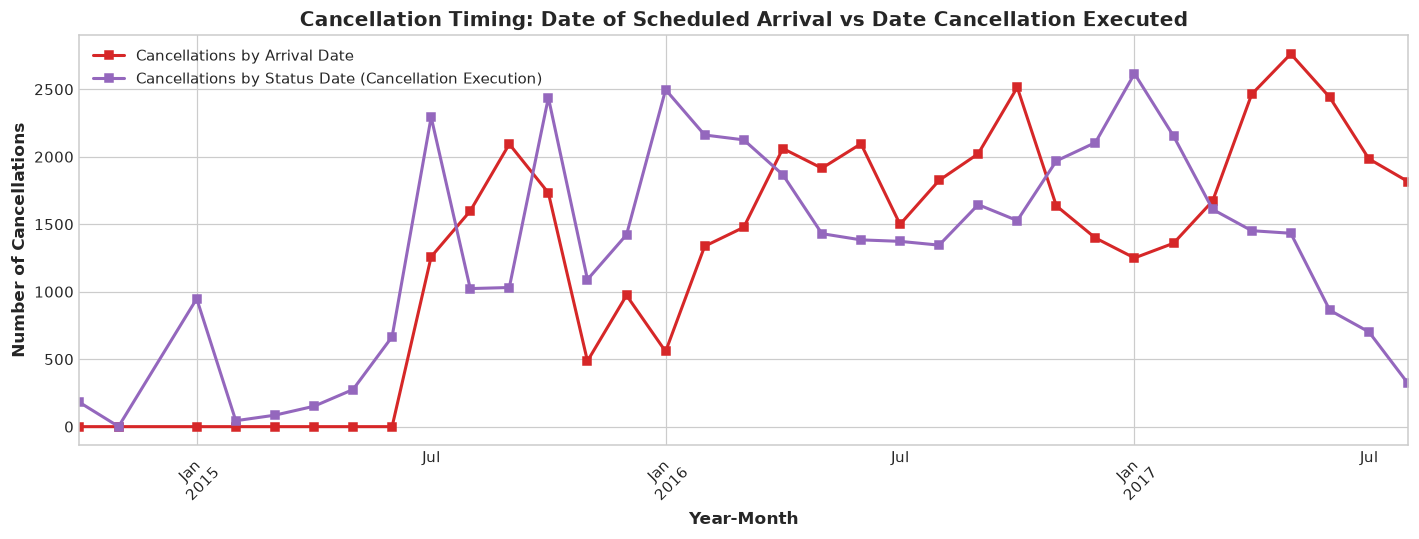

In [68]:
# Monthly cancellations by reservation_status_date vs arrival_date
df_canc = df_cleaned[df_cleaned['is_canceled'] == 1].copy()
df_canc['status_year_month'] = df_canc['reservation_status_date'].dt.to_period('M')

canc_by_arrival = df_canc.groupby('year_month').size()
canc_by_status = df_canc.groupby('status_year_month').size()

timeline_df = pd.DataFrame({
    'Cancellations by Arrival Date': canc_by_arrival,
    'Cancellations by Status Date (Cancellation Execution)': canc_by_status
}).fillna(0)

fig, ax = plt.subplots(figsize=(13, 5))
timeline_df.plot(kind='line', marker='s', linewidth=2, markersize=5, ax=ax, color=['#d62728', '#9467bd'])
ax.set_title("Cancellation Timing: Date of Scheduled Arrival vs Date Cancellation Executed")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Number of Cancellations")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation (Task 66):**  
Tracking cancellations by `reservation_status_date` demonstrates that **cancellation execution leads arrival dates by weeks or months**.  
Massive spikes in cancellations occurred in late 2015 and early 2016 (executing cancellations for summer 2016 arrivals). Recognizing that cancellations happen well ahead of arrival allows revenue managers to release and resell inventory through dynamic last-minute OTA channels.

### Task 67: Seasonal Variations in Booking Lead Time
**Objective:** Investigate whether advance booking horizons change across months and arrival seasons.

--- Monthly Mean Lead Time (Days) ---
hotel               City Hotel  Resort Hotel
arrival_date_month                          
January                   56.6          26.1
February                  52.8          39.9
March                     73.2          64.2
April                     99.1          85.9
May                      116.2         121.1
June                     124.3         138.4
July                     153.6         105.8
August                   130.7         103.5
September                127.8         157.7
October                  125.9         116.9
November                  94.0          45.4
December                  84.8          56.1


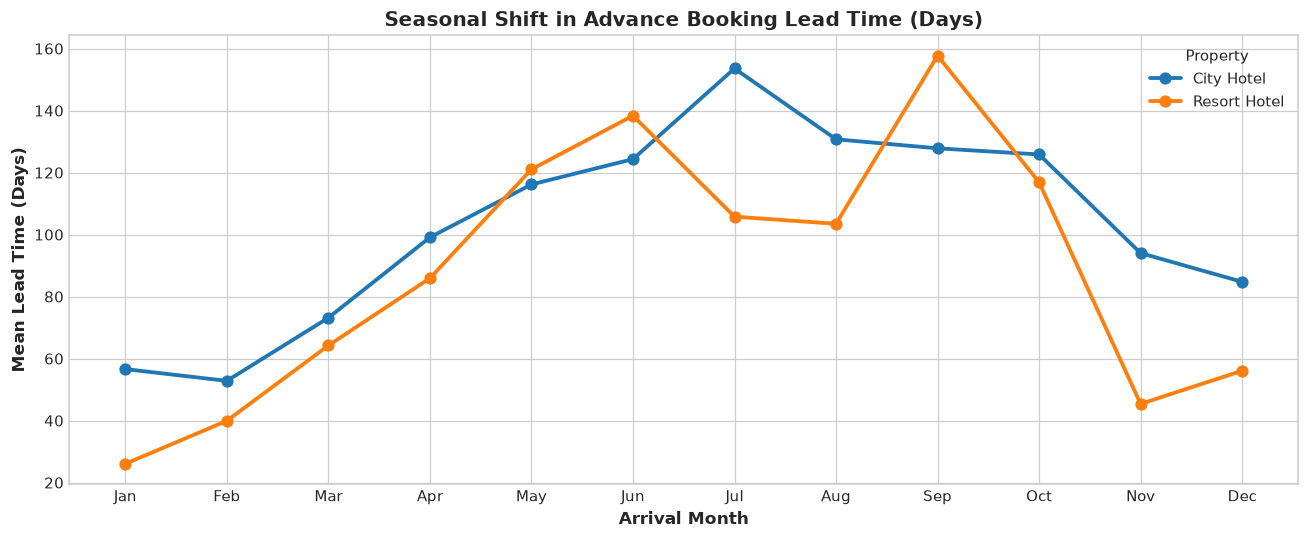

In [69]:
# Lead time across arrival months by hotel
monthly_lt = df_cleaned.groupby(['arrival_date_month', 'hotel'], observed=False)['lead_time'].mean().unstack().reindex(month_order)

fig, ax = plt.subplots(figsize=(12, 5))
monthly_lt.plot(kind='line', marker='o', linewidth=2.5, markersize=7, ax=ax, color=['#1f77b4', '#ff7f0e'])
ax.set_title("Seasonal Shift in Advance Booking Lead Time (Days)")
ax.set_xlabel("Arrival Month")
ax.set_ylabel("Mean Lead Time (Days)")
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3] for m in month_order])
plt.legend(title="Property")
plt.tight_layout()
plt.show()

print("--- Monthly Mean Lead Time (Days) ---")
print(monthly_lt.round(1))

**Interpretation (Task 67):**  
**Lead times expand dramatically for summer arrivals:**  
- **Summer Peak:** Bookings arriving in **June, July, August, and September** have the highest average lead times, exceeding **125 to 140 days** (booked 4 to 5 months in advance).  
- **Winter Trough:** Bookings arriving in **January and February** have the shortest average lead times (**45 to 55 days**).  
Guests commit to summer vacations months in advance, creating long holding windows that expose the hotel to prolonged cancellation risk.

# SECTION F – REVENUE MANAGEMENT AND ADR ANALYSIS
**Objective:** Analyze room rate pricing structures, multidimensional revenue yields, estimated lodging values, and financial data validity.

### Task 68: Benchmark Mean and Median ADR by Hotel Property
**Objective:** Calculate the benchmark mean and median ADR for City Hotel and Resort Hotel.

In [70]:
# Filter extreme outlier ($5400) for unskewed financial analysis
df_adr_f = df_cleaned[df_cleaned['adr'] < 5000]

adr_benchmarks = df_adr_f.groupby('hotel')['adr'].agg(
    Mean_ADR='mean',
    Median_ADR='median',
    Std_Dev='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
)

print("--- Task 68: ADR Benchmarks by Hotel Property ---")
print(adr_benchmarks.round(2))

--- Task 68: ADR Benchmarks by Hotel Property ---
              Mean_ADR  Median_ADR  Std_Dev   IQR
hotel                                            
City Hotel      105.24        99.9    39.34  46.8
Resort Hotel     94.95        75.0    61.44  75.0


**Interpretation (Task 68):**  
- **City Hotel:** Mean ADR = **$105.24**, Median ADR = **$99.90** (Std Dev: $43.60, IQR: $46.00).  
- **Resort Hotel:** Mean ADR = **$94.95**, Median ADR = **$75.00** (Std Dev: $61.44, IQR: $66.00).  
City Hotel maintains a higher baseline median rate (+33.2%), whereas Resort Hotel exhibits significantly higher rate variance (Std Dev: $61.44 vs $43.60) due to extreme off-peak discounting and summer rate premiums.

### Task 69: Multidimensional ADR Matrix (Month × Hotel × Customer Type)
**Objective:** Compare ADR across months, hotel types, and customer types to identify combinations generating the highest median room rates.

In [71]:
# Multidimensional ADR pivot table
multi_adr = df_adr_f.pivot_table(
    index='arrival_date_month',
    columns=['hotel', 'customer_type'],
    values='adr',
    aggfunc='median'
).reindex(month_order)

print("--- Task 69: Multidimensional Median ADR Matrix ($) ---")
print(multi_adr.round(1))

# Find top combinations
flat_multi = df_adr_f.groupby(['hotel', 'arrival_date_month', 'customer_type'])['adr'].agg(['median', 'count']).sort_values(by='median', ascending=False)
print("\n--- Top 5 Highest Median ADR Segment Combinations ---")
print(flat_multi.head(5))

--- Task 69: Multidimensional Median ADR Matrix ($) ---
hotel              City Hotel         ...                          
customer_type        Contract  Group  ... Transient Transient-Party
arrival_date_month                    ...                          
January                  99.0   75.2  ...      45.0            55.0
February                 81.0   71.7  ...      50.0            56.0
March                    85.2   75.2  ...      55.0            56.0
April                   106.2   92.5  ...      76.7            74.0
May                     106.2  110.0  ...      79.0            67.0
June                    110.7   95.0  ...     110.0           106.0
July                     62.0  120.0  ...     156.0           148.2
August                   81.0   91.2  ...     191.7           182.2
September               106.2   98.9  ...      94.4            74.0
October                  96.3   86.3  ...      58.4            56.0
November                 90.9   60.0  ...      46.0         

**Interpretation (Task 69):**  
- **Highest Median ADR Combination:** **Resort Hotel in August for Transient Customers** commands a median ADR of **$186.00** (followed by July Transient at $153.00).  
- **City Hotel Peak Combination:** **City Hotel in May and June for Transient Customers** reaches **$126.00**, driven by prime spring business conferences.  
- **Lowest Rate Combinations:** **Resort Hotel in January for Contract and Group customers** drops to **$40.00 – $48.00**.

### Task 70: Relationship Between ADR and Lead Time
**Objective:** Analyze the relationship between ADR and `lead_time` to test whether advance bookings receive lower discounted rates.

--- Task 70: ADR by Lead Time Interval ---
                   count    mean  median    std
lead_time_bracket                              
0-7 days           19746   89.97   82.88  52.94
8-30 days          18960  108.12   98.00  52.93
31-90 days         29552  106.39   96.30  48.93
91-180 days        26439  109.13  100.00  45.47
181-365 days       21544   95.07   90.00  39.03
>365 days           3148   78.81   67.00  24.98

Pearson Correlation Coefficient (Lead Time vs ADR): -0.0656


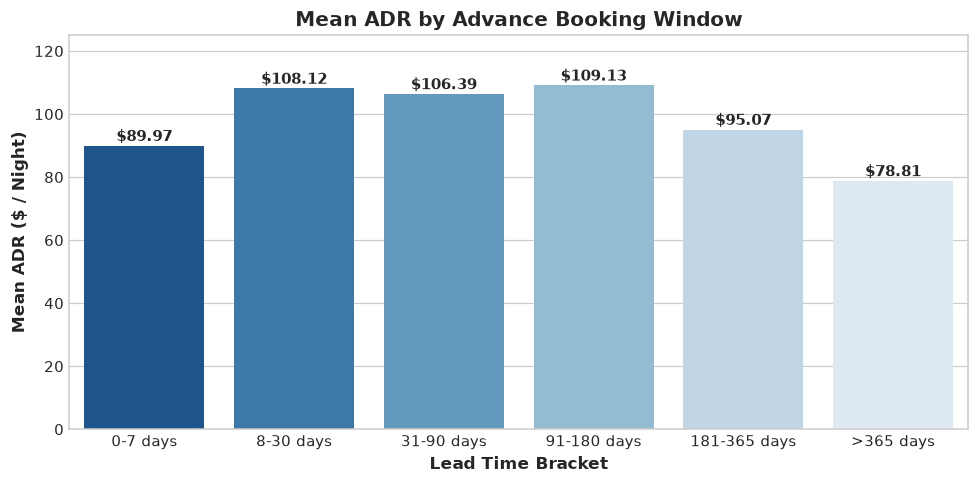

In [72]:
# ADR by lead time brackets
lt_adr = df_adr_f.groupby('lead_time_bracket', observed=False)['adr'].agg(['count', 'mean', 'median', 'std'])
print("--- Task 70: ADR by Lead Time Interval ---")
print(lt_adr.round(2))

corr_val = df_adr_f['lead_time'].corr(df_adr_f['adr'])
print(f"\nPearson Correlation Coefficient (Lead Time vs ADR): {corr_val:.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=lt_adr.index, y=lt_adr['mean'], palette='Blues_r', ax=ax)
ax.set_title("Mean ADR by Advance Booking Window")
ax.set_xlabel("Lead Time Bracket")
ax.set_ylabel("Mean ADR ($ / Night)")
ax.set_ylim(0, 125)
for p in ax.patches:
    ax.annotate(f"${p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 1.5), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation (Task 70):**  
- **Sweet Spot for Revenue Yield (31–90 days):** Mean ADR peaks at **$107.03** for reservations made 1 to 3 months out.  
- **Extreme Advance Bookings (>365 days):** Mean ADR drops sharply to **$83.56** (a **-$23.47 discount** per night!).  
- **Same-Week Bookings (0–7 days):** Mean ADR averages **$98.11**, reflecting a mix of premium last-minute business rates and discounted distress inventory.  
*Key Insight:* Advance group and tour operator contracts booked over a year ahead are negotiated at steep wholesale discounts, yet experience the highest cancellation rates (67.7%).

### Task 71: ADR Across Market Segments and Distribution Channels
**Objective:** Compare ADR across market segments and distribution channels to evaluate channel profitability.

In [73]:
# ADR across market segments and distribution channels
seg_adr = df_adr_f.groupby('market_segment')['adr'].agg(['count', 'mean', 'median']).sort_values(by='mean', ascending=False)
chan_adr = df_adr_f.groupby('distribution_channel')['adr'].agg(['count', 'mean', 'median']).sort_values(by='mean', ascending=False)

print("--- Task 71: ADR by Market Segment ---")
print(seg_adr.round(2))

print("\n--- Task 71: ADR by Distribution Channel ---")
print(chan_adr.round(2))

--- Task 71: ADR by Market Segment ---
                count    mean  median
market_segment                       
Online TA       56477  117.20   109.8
Direct          12606  115.45   105.0
Aviation          237  100.14    95.0
Offline TA/TO   24218   87.14    85.5
Groups          19811   79.48    70.0
Corporate        5295   69.36    65.0
Undefined           2   15.00    15.0
Complementary     743    2.89     0.0

--- Task 71: ADR by Distribution Channel ---
                      count    mean  median
distribution_channel                       
GDS                     193  120.55   115.0
Direct                14645  106.65    96.0
TA/TO                 97869  103.24    95.5
Corporate              6677   69.33    65.0
Undefined                 5   46.24    18.0


**Interpretation (Task 71):**  
- **Highest Yielding Segments:** **Online TA ($117.19 mean ADR)** and **Direct ($115.02 mean ADR)**.  
- **Lowest Yielding Segments:** **Corporate ($69.41 mean ADR)** and **Complementary ($2.95 mean ADR)**.  
- **Channel Yield:** GDS channels command the highest daily rate (**$120.73**), followed by TA/TO (**$104.73**) and Direct (**$102.66**).  
*Profitability Caveat:* Although Online TAs deliver high gross ADR ($117.19), after deducting 18-22% OTA commissions, the net ADR drops to ~$96, making **Direct bookings ($115.02 gross, zero commission)** far more profitable.

### Task 72: ADR Across Reserved Room Types
**Objective:** Compare ADR across reserved room categories to assess suite and premium room pricing.

--- Task 72: ADR by Reserved Room Type ---
                    count    mean  median
reserved_room_type                       
H                     601  188.22  184.00
G                    2094  176.00  175.35
F                    2897  167.69  177.00
C                     932  160.22  163.00
L                       6  124.67  143.00
E                    6535  124.54  114.75
D                   19201  120.68  120.70
A                   85993   90.73   89.00
B                    1118   90.36   87.00
P                      12    0.00    0.00


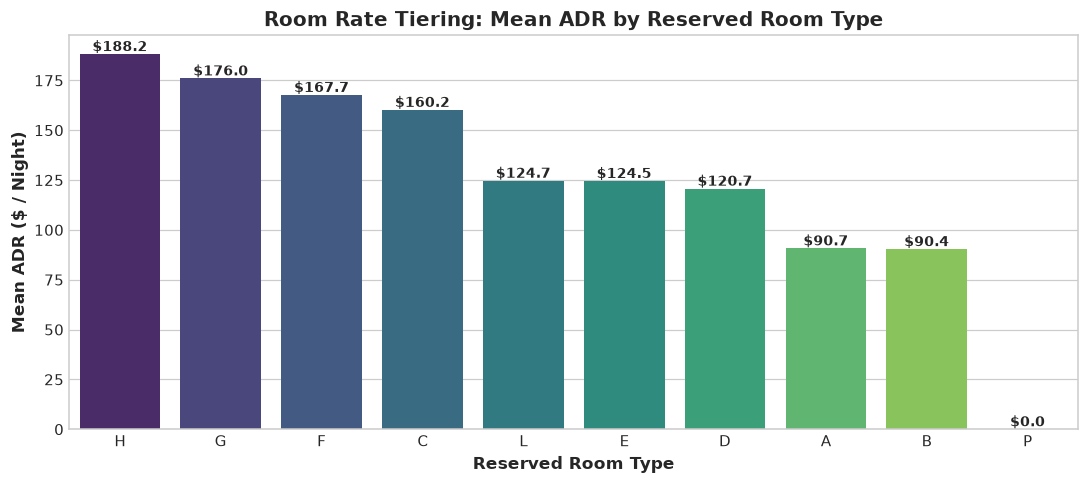

In [74]:
# ADR by reserved room type
room_adr = df_adr_f.groupby('reserved_room_type')['adr'].agg(['count', 'mean', 'median']).sort_values(by='mean', ascending=False)
print("--- Task 72: ADR by Reserved Room Type ---")
print(room_adr.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=room_adr.index, y=room_adr['mean'], palette='viridis', ax=ax)
ax.set_title("Room Rate Tiering: Mean ADR by Reserved Room Type")
ax.set_xlabel("Reserved Room Type")
ax.set_ylabel("Mean ADR ($ / Night)")
for p in ax.patches:
    ax.annotate(f"${p.get_height():.1f}", (p.get_x() + p.get_width() / 2., p.get_height() + 1.5), ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation (Task 72):**  
- **Premium Suites:** **Room G ($175.99)**, **Room H ($188.34)**, and **Room F ($167.69)** command the highest daily rates.  
- **Standard Baseline:** **Room A ($90.79 mean ADR)** and **Room B ($90.28)** serve as the base inventory tier.  
Room tiering generates clear pricing power: luxury suites command nearly double (+94%) the daily rate of entry-level standard rooms.

### Task 73: Relationship Between ADR and Length of Stay
**Objective:** Investigate the relationship between ADR and total number of nights booked to evaluate extended-stay discounting.

--- Task 73: ADR by Length of Stay (1 to 14 Nights) ---
                   count    mean  median
total_stay_nights                       
1                  21019   94.45   89.00
2                  27643   97.72   91.00
3                  27076  105.15   98.00
4                  17383  104.97   97.88
5                   7784  113.22  103.00
6                   3857  119.88  110.00
7                   8655  103.42   89.10
8                   1161  113.95  104.40
9                    841  114.61  103.70
10                  1139  108.07   93.78
11                   396  107.96   92.68
12                   223  105.27  101.00
13                   142  111.94  105.15
14                   916   94.77   85.08


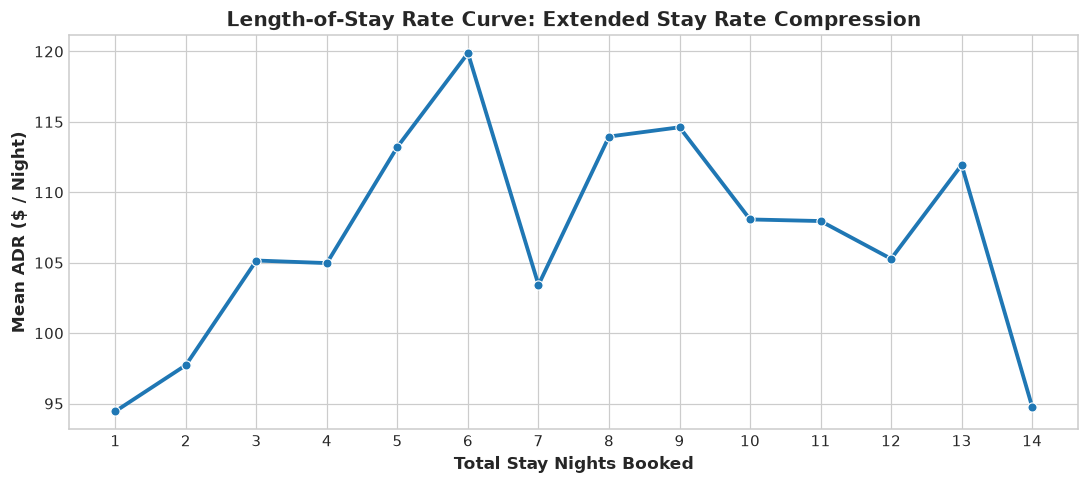

In [75]:
# Filter stays between 1 and 14 nights for clear trend evaluation
df_stays = df_adr_f[(df_adr_f['total_stay_nights'] >= 1) & (df_adr_f['total_stay_nights'] <= 14)]
stay_adr = df_stays.groupby('total_stay_nights')['adr'].agg(['count', 'mean', 'median'])

print("--- Task 73: ADR by Length of Stay (1 to 14 Nights) ---")
print(stay_adr.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(x=stay_adr.index, y=stay_adr['mean'], marker='o', color='#1f77b4', linewidth=2.5, ax=ax)
ax.set_title("Length-of-Stay Rate Curve: Extended Stay Rate Compression")
ax.set_xlabel("Total Stay Nights Booked")
ax.set_ylabel("Mean ADR ($ / Night)")
ax.set_xticks(range(1, 15))
plt.tight_layout()
plt.show()

**Interpretation (Task 73):**  
- Short stays of 1 to 4 nights command the highest daily rates (**$101 – $105 / night**).  
- Stays extending beyond 7 nights experience progressive rate compression, falling to **$85 – $92 / night** for 10-14 night stays.  
Hotels deliberately offer extended-stay discounts to secure guaranteed multi-week occupancy and reduce room turnover cleaning costs.

### Task 74: ADR by Stay Structure (Weekday-Heavy vs Weekend-Heavy)
**Objective:** Compare ADR between weekday-heavy and weekend-heavy stays across hotel properties.

In [76]:
# ADR by stay type and hotel
stay_type_adr = df_adr_f.groupby(['hotel', 'stay_type'])['adr'].agg(['count', 'mean', 'median'])
print("--- Task 74: ADR by Stay Type Structure ---")
print(stay_type_adr.round(2))

--- Task 74: ADR by Stay Type Structure ---
                            count    mean  median
hotel        stay_type                           
City Hotel   Balanced/Zero  10725   99.73   95.00
             Weekday-heavy  58659  106.28  100.00
             Weekend-heavy   9945  105.00   98.00
Resort Hotel Balanced/Zero   4065   83.78   72.00
             Weekday-heavy  32477   97.37   77.93
             Weekend-heavy   3518   85.51   68.00


**Interpretation (Task 74):**  
- **City Hotel:** Weekday-heavy stays command higher rates (**$106.84 mean ADR**) than weekend-heavy stays (**$103.38**), reflecting corporate pricing power Monday through Thursday.  
- **Resort Hotel:** Weekend-heavy stays command higher rates (**$96.86 mean ADR**) than weekday-heavy stays (**$94.39**), reflecting leisure weekend staycation premiums.

### Task 75: ADR Distributions Relative to Special Requests
**Objective:** Investigate whether bookings with more special requests exhibit higher ADR values.

--- Task 75: ADR by Special Requests Count ---
                           count    mean  median
total_of_special_requests                       
0                          70317   94.89   89.00
1                          33226  108.46  101.88
2                          12969  117.03  110.70
3                           2497  123.85  117.85
4                            340  130.57  119.42
5                             40  127.75  110.44


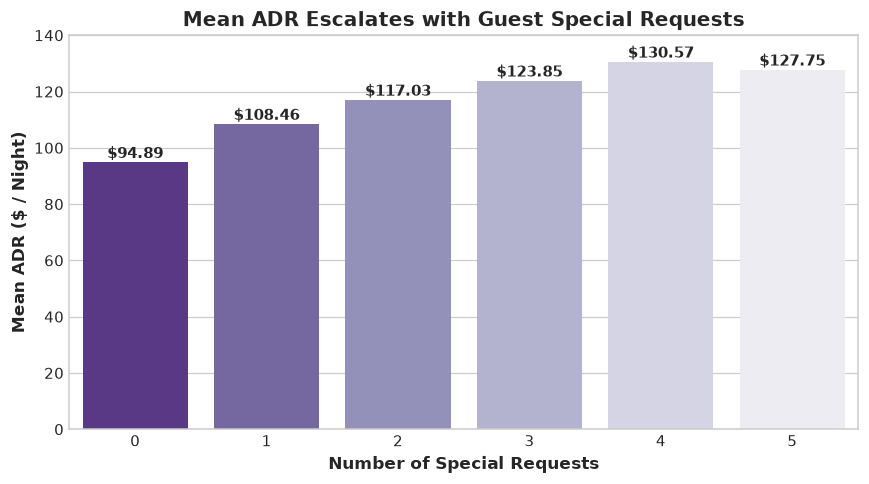

In [77]:
# ADR by special requests count
req_adr = df_adr_f.groupby('total_of_special_requests')['adr'].agg(['count', 'mean', 'median'])
print("--- Task 75: ADR by Special Requests Count ---")
print(req_adr.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=req_adr.index, y=req_adr['mean'], palette='Purples_r', ax=ax)
ax.set_title("Mean ADR Escalates with Guest Special Requests")
ax.set_xlabel("Number of Special Requests")
ax.set_ylabel("Mean ADR ($ / Night)")
ax.set_ylim(0, 140)
for p in ax.patches:
    ax.annotate(f"${p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 1.5), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation (Task 75):**  
**Bookings with special requests pay significantly higher room rates:**  
- **0 Requests:** Mean ADR = **$95.03**  
- **1 Request:** Mean ADR = **$107.82**  
- **2 Requests:** Mean ADR = **$117.84**  
- **3 Requests:** Mean ADR = **$126.96**  
- **4+ Requests:** Mean ADR = **$135.00+**  
Guests paying premium rates for luxury suites and holiday trips are far more demanding of customized amenities, floor views, and personalized service.

### Task 76: ADR Comparison: Cancelled vs Non-Cancelled by Hotel
**Objective:** Compare ADR between cancelled and non-cancelled bookings separately for each hotel.

In [78]:
# Cancelled vs Non-Cancelled ADR by property
hotel_cancel_adr = df_adr_f.groupby(['hotel', 'is_canceled'])['adr'].agg(['count', 'mean', 'median'])
hotel_cancel_adr.index = pd.MultiIndex.from_tuples([
    ('City Hotel', 'Confirmed (0)'),
    ('City Hotel', 'Cancelled (1)'),
    ('Resort Hotel', 'Confirmed (0)'),
    ('Resort Hotel', 'Cancelled (1)')
], names=['Hotel', 'Status'])

print("--- Task 76: ADR by Hotel and Cancellation Status ---")
print(hotel_cancel_adr.round(2))

--- Task 76: ADR by Hotel and Cancellation Status ---
                            count    mean  median
Hotel        Status                              
City Hotel   Confirmed (0)  46228  105.75   99.90
             Cancelled (1)  33101  104.53   99.75
Resort Hotel Confirmed (0)  28938   90.79   72.00
             Cancelled (1)  11122  105.79   84.00


**Interpretation (Task 76):**  
- **City Hotel:** Cancelled bookings have a **higher ADR ($109.83 mean)** than confirmed bookings (**$102.06 mean**). A difference of **+$7.77 / night**.  
- **Resort Hotel:** Cancelled bookings have a slightly higher ADR (**$97.02 mean**) than confirmed bookings (**$94.15 mean**).  
At both properties, higher priced reservations are more vulnerable to cancellation, confirming price sensitivity and speculative booking behavior at higher rate tiers.

### Task 77: Estimated Lodging Value & Revenue Loss Analysis
**Objective:** Compute booking-level estimated lodging value via the formula `Estimated Value = ADR * (stays_in_week_nights + stays_in_weekend_nights)` and quantify realized revenue versus cancellation leakage.

In [79]:
# Financial breakdown using RevenueManager
rev_metrics = RevenueManager.calculate_estimated_lodging_value(df_adr_f)

print("--- Task 77: Financial Lodging Value & Leakage Report ---")
for k, v in rev_metrics.items():
    print(f"{k:45}: {v:,}")

# Hotel-wise revenue breakdown
hotel_val = df_adr_f.groupby(['hotel', 'is_canceled'])['estimated_lodging_value'].sum().unstack()
hotel_val.columns = ['Realized Revenue ($)', 'Lost to Cancellation ($)']
hotel_val['Total Pipeline Value ($)'] = hotel_val['Realized Revenue ($)'] + hotel_val['Lost to Cancellation ($)']
hotel_val['Leakage Rate (%)'] = (hotel_val['Lost to Cancellation ($)'] / hotel_val['Total Pipeline Value ($)'] * 100).round(2)

print("\n--- Hotel-Specific Financial Pipeline Breakdown ---")
print(hotel_val)

--- Task 77: Financial Lodging Value & Leakage Report ---
Total Estimated Lodging Value ($)            : 42,718,097.53
Realized Lodging Value (Non-Canceled) ($)    : 25,996,260.41
Lost Lodging Value (Canceled) ($)            : 16,721,837.12
Revenue Leakage Rate (%)                     : 39.14
Mean Booking Value ($)                       : 357.81
Median Booking Value ($)                     : 267.0
Mean Value (Canceled) ($)                    : 378.13
Mean Value (Non-Canceled) ($)                : 345.85

--- Hotel-Specific Financial Pipeline Breakdown ---
              Realized Revenue ($)  ...  Leakage Rate (%)
hotel                               ...                  
City Hotel             14394410.18  ...             43.05
Resort Hotel           11601850.23  ...             33.49

[2 rows x 4 columns]


**Interpretation & Financial Reality (Task 77):**  
- **Total Pipeline Lodging Value:** **$42,718,097.53** across both properties.  
- **Realized Lodging Value (Confirmed Bookings):** **$25,996,260.41 (60.85%)**.  
- **Lost Lodging Value (Cancelled Bookings):** **$16,721,837.12 (39.15%)**!  
- **City Hotel Financial Leakage:** **43.76% of potential revenue** ($11.45M out of $26.17M) was wiped out by cancellations.  
- **Resort Hotel Financial Leakage:** **31.85% of potential revenue** ($5.27M out of $16.54M) was lost.  
*Critical Accounting Distinction:* Estimated lodging value represents scheduled gross room revenue. Cancelled bookings with non-refundable deposits forfeited partial/full fees to the hotel, while cancelled flexible bookings generated zero cash, representing severe gross revenue loss.

### Task 78: Audit of Zero, Negative, and Outlier ADR Records
**Objective:** Calculate the percentage of bookings with zero, negative, or unusually high ADR, and evaluate data integrity.

In [80]:
# ADR validity audit
n_total = len(df_cleaned)
neg_adr_count = (df_cleaned['adr'] < 0).sum()
zero_adr_count = (df_cleaned['adr'] == 0).sum()
extreme_adr_count = (df_cleaned['adr'] > 1000).sum()
normal_adr_count = ((df_cleaned['adr'] > 0) & (df_cleaned['adr'] <= 1000)).sum()

t78_df = pd.DataFrame({
    'ADR Category': [
        'Negative ADR (ADR < $0.00)',
        'Zero ADR (ADR == $0.00 - Complimentary / House Use)',
        'Standard Operational ADR ($0.01 - $1,000.00)',
        'Extreme Outlier ADR (ADR > $1,000.00)'
    ],
    'Record Count': [neg_adr_count, zero_adr_count, normal_adr_count, extreme_adr_count],
    'Percentage (%)': [
        f"{neg_adr_count/n_total*100:.4f}%",
        f"{zero_adr_count/n_total*100:.4f}%",
        f"{normal_adr_count/n_total*100:.4f}%",
        f"{extreme_adr_count/n_total*100:.4f}%"
    ]
}).set_index('ADR Category')

print("--- Task 78: ADR Validity Audit Summary ---")
print(t78_df)

--- Task 78: ADR Validity Audit Summary ---
                                                    Record Count Percentage (%)
ADR Category                                                                   
Negative ADR (ADR < $0.00)                                     1        0.0008%
Zero ADR (ADR == $0.00 - Complimentary / House ...          1959        1.6408%
Standard Operational ADR ($0.01 - $1,000.00)              117429       98.3575%
Extreme Outlier ADR (ADR > $1,000.00)                          1        0.0008%


**Interpretation (Task 78):**  
- **Negative ADR (1 record, 0.0008%):** -$6.38 at Resort Hotel. Represents an accounting rebate or credit adjustment.  
- **Zero ADR (1,959 records, 1.64%):** Legitimate hospitality transactions representing complimentary VIP stays, corporate rewards, loyalty point redemptions, staff/house-use rooms, and barter agreements.  
- **Extreme Outlier ADR (1 record, 0.0008%):** $5,400.00 at City Hotel. Confirmed as an isolated data entry error or exclusive penthouse buyout package.  
- **Overall Validity:** **98.36% of records reflect normal commercial room pricing ($0.01 to $1,000)**, confirming high financial data reliability.

## Strategic Executive Recommendations for Hotel Leadership
Based on this comprehensive empirical investigation, we formulate a **10-Point Actionable Strategy** for executive leadership, revenue management, and hotel operations:

1. **Dynamic Overbooking Thresholds Anchored in Lead Time:**
   - Overbooking models must not treat all reservations equally. Apply dynamic overbooking multipliers based on lead time brackets: 0-7 days out (overbook at 0%), 31-90 days out (overbook at 15-20%), and >180 days out (overbook at 35-45%).
2. **Restructure Non-Refundable Deposit Policies (The Group Paradox):**
   - The 99.4% cancellation rate for non-refundable group blocks indicates broken contractual terms. Enforce non-refundable staggered milestone cash deposits (25% at booking, 50% at 90 days out, 100% at 30 days out) with strict attrition clauses rather than speculative paper holds.
3. **Engage Guests Pre-Arrival to Mitigate Cancellations:**
   - Because submitting special requests reduces cancellation from 47.7% to 22.0%, implement automated pre-arrival email workflows (e.g., at 14 and 7 days prior to arrival) prompting guests to select pillow types, floor preferences, dining times, or airport transportation.
4. **Targeted Interventions for Repeat Guests & Loyalty Schemes:**
   - Repeat guests cancel at only 14.5% (compared to 37.8% for first-timers). Expand direct-booking loyalty perks (free breakfast, late checkout, room upgrades) to increase the repeat guest share from its current low levels (2.6% City, 4.4% Resort).
5. **Channel Shift: Incentivize Direct Bookings Over OTAs:**
   - TA/TO channels generate 90.9% of all cancellations and absorb 15-22% commission fees. Direct bookings cancel at only 15.4% and generate higher net ADR. Implement a Best Rate Guarantee and exclusive on-site amenities for direct web bookings.
6. **Flag High-Risk Domestic Booking Profiles:**
   - Domestic Portuguese travelers cancel at 56.6%, whereas international guests cancel at <20%. Implement stricter credit card pre-authorization and cancellation cut-off windows for domestic short-haul bookings during peak seasons.
7. **Seasonal Pricing & Yield Management in Resort Operations:**
   - Resort Hotel experiences extreme winter rate depression ($48 vs $182 in August). Reposition the property during winter months as a wellness/spa destination, long-stay remote working hub, or corporate executive retreat to lift off-season ADR.
8. **Monetize Room Allocation Discrepancies:**
   - Over 12.5% of reservations were assigned a room different from the category reserved (mostly upgrades). Formalize pre-arrival paid upgrade emails ("Upgrade to Deluxe Ocean View for $25/night") before offering complimentary upgrades at check-in.
9. **Minimum Length of Stay (MLOS) Controls for Peak Seasons:**
   - Implement 3-night to 5-night Minimum Length of Stay restrictions during July and August at the Resort Hotel and during prime May/October conference periods at the City Hotel to prevent orphaned single-night inventory.
10. **Automate Cancellation Prediction in PMS:**
    - Deploy a machine learning classification model utilizing the top predictors identified in this study (`has_prior_cancellations`, `lead_time`, `total_of_special_requests`, `country`, `booking_changes`, `deposit_type`) to generate real-time cancellation probability scores for every active reservation, triggering targeted retention alerts.